## V1 - Baseline HeteroGNN

In [ ]:
# V1 / 1. CONFIGURAZIONE E DATI COMPLETI

# Setup: Python 3.12; da questa cartella: python -m pip install -r requirements.txt (credo sia sufficiente anche in un virtualenv); poi apri questo notebook in JupyterLab o dove preferisci.
# Seleziona quel kernel ed esegui le quattro celle della sola V1 oppure V2.

# Gli output salvati sono storici: riesegui le celle per valutare la configurazione attuale.

from pathlib import Path
from datetime import datetime
import os

# MODIFICA QUESTO BLOCCO come fosse un configuratore: i parametri qui sotto valgono per tutti i dataset selezionati. Per cambiare il comportamento di un dataset specifico, modifica MODEL_PARAMS o PARAM_GRID.; 
# Esecuzione: questi interruttori valgono sia in holdout sia in k-fold.
GRID_SEARCH = False
EARLY_STOPPING = True
DOWNLOAD_MISSING_DATA = True  # Primo avvio: ~0.9 GB da Internet, ~4 GB su disco; poi usa la cache.
USE_GPU = True  # GPU NVIDIA/AMD se utilizzabile; False forza la CPU.
CPU_THREADS = max(1, (os.cpu_count() or 1) - 1)
SEED = 123  # Inizializzazione, dropout e ordine dei batch.
SPLIT_SEED = 123  # Cambialo solo per cambiare la suddivisione dei dati.

# Dati: commenta una voce per eseguire solo l'altro dataset.
DATASETS = {
    "CICIDS2017": Path("data/cicids2017"),
    "CICToNIoT": Path("data/cictoniot/CIC-ToN-IoT-graph.parquet"),
}
WINDOW_MINUTES = 1

# Valutazione: 1 = holdout; >= 2 = k-fold di grafi interi.
N_FOLDS = {"CICIDS2017": 5, "CICToNIoT": 5}
FOLDS_TO_RUN = {"CICIDS2017": None, "CICToNIoT": None}  # None = tutti; [1, 3] = soltanto quei fold.
HOLDOUT_TEST_FRACTION = 0.15
HOLDOUT_VAL_FRACTION = 0.15  # Frazione dell'intero dataset.
KFOLD_VAL_FRACTION = 0.15  # Frazione dei grafi rimasti dopo il test esterno.

# Training: con EARLY_STOPPING=False si completano tutte le epoche.
MAX_EPOCHS = 100
PATIENCE = 10
MIN_DELTA = 1e-4

# GRID_SEARCH=False: un solo setting per dataset, anche in holdout.
MODEL_PARAMS = {
    "CICIDS2017": {"hidden_channels":64,"out_channels":16,"dropout":0.2,
                   "lr":1e-3,"weight_decay":1e-4,"batch_size":4},
    "CICToNIoT": {"hidden_channels":32,"out_channels":16,"dropout":0.2,
                  "lr":1e-3,"weight_decay":1e-4,"batch_size":4},
}

# GRID_SEARCH=True: valori da provare sul validation interno.
PARAM_GRID = {
    "hidden_channels": [32, 64], "out_channels": [16, 32], "dropout": [0.2],
    "lr": [1e-3, 3e-4], "weight_decay": [1e-4, 1e-3], "batch_size": [4],
}

# Avanzati: possono restare invariati.
FOCAL_ALPHA = 0.25  # Fattore comune alle classi, non un peso maggiore per gli attacchi.
FOCAL_GAMMA = 2.0
COUNT_PERCENTILES = [90, 95, 99]
TREE_MAX_DEPTH = 1
STUMP_FEATURES = ["source_out", "destination_in"]
LOADER_WORKERS = 0  # In Jupyter su Windows lascia 0; il parallelismo CPU usa CPU_THREADS.
CSV_CHUNK_ROWS = 250_000
MAX_GRAPH_PAIRS = 8
PLOT_DPI = 140
OUTPUT_ROOT = Path("data/marco_output")   # Cambia se vuoi salvare altrove; la cartella viene creata automaticamente. 
SEMANTICS = {
    "network": ["Source Port", "Destination Port"],
    "context": ["Flow Duration", "Flow IAT Mean"],
    "knowledge": ["Packet Length Std", "SYN Flag Count"],
}
# FINE CONFIGURAZIONE

if isinstance(CPU_THREADS,bool) or not isinstance(CPU_THREADS,int) or CPU_THREADS<1:
    raise ValueError("CPU_THREADS: serve un intero positivo")
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = str(CPU_THREADS)
import json
import hashlib
import urllib.request
import urllib.parse
import zipfile
import random
import time
import warnings
import gc
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric
from torch_geometric.data import HeteroData
from torch_geometric.loader import DataLoader
from torch_geometric.nn import HeteroConv, GCNConv
from sklearn.model_selection import ParameterGrid, train_test_split, KFold, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
    confusion_matrix, precision_recall_fscore_support, roc_auc_score, balanced_accuracy_score,
    matthews_corrcoef, ConfusionMatrixDisplay, precision_recall_curve)
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from tqdm import tqdm


RUN_DIR = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
FEATURES = [f for group in SEMANTICS.values() for f in group]
REQUIRED = ["Source IP", "Destination IP", "Timestamp", "Label", *FEATURES]
RELATIONS = [("ip", name, "ip") for name in SEMANTICS]
ALIASES = {"Src IP": "Source IP", "Dst IP": "Destination IP", "Src Port": "Source Port",
           "Dst Port": "Destination Port", "Pkt Len Std": "Packet Length Std", "SYN Flag Cnt": "SYN Flag Count"}


def validate_configuration():
    for name,value in [("GRID_SEARCH",GRID_SEARCH),("EARLY_STOPPING",EARLY_STOPPING),("USE_GPU",USE_GPU),("DOWNLOAD_MISSING_DATA",DOWNLOAD_MISSING_DATA)]:
        if not isinstance(value,bool):
            raise ValueError(f"{name}: usare True oppure False")
    integers = {"MAX_EPOCHS":MAX_EPOCHS,"CPU_THREADS":CPU_THREADS,"WINDOW_MINUTES":WINDOW_MINUTES,
        "CSV_CHUNK_ROWS":CSV_CHUNK_ROWS,"TREE_MAX_DEPTH":TREE_MAX_DEPTH,"MAX_GRAPH_PAIRS":MAX_GRAPH_PAIRS,
        "PLOT_DPI":PLOT_DPI}
    for name,value in integers.items():
        if isinstance(value,bool) or not isinstance(value,int) or value<1:
            raise ValueError(f"{name}: serve un intero positivo")
    if isinstance(LOADER_WORKERS,bool) or not isinstance(LOADER_WORKERS,int) or LOADER_WORKERS<0:
        raise ValueError("LOADER_WORKERS deve essere un intero >= 0")
    if EARLY_STOPPING and (not isinstance(PATIENCE,int) or isinstance(PATIENCE,bool) or PATIENCE<1
                          or not isinstance(MIN_DELTA,(int,float)) or not np.isfinite(MIN_DELTA) or MIN_DELTA<0):
        raise ValueError("Early stopping: PATIENCE positiva e MIN_DELTA finito >= 0")
    if not (0<HOLDOUT_TEST_FRACTION<1 and 0<HOLDOUT_VAL_FRACTION<1
            and HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION<1 and 0<KFOLD_VAL_FRACTION<1):
        raise ValueError("Frazioni di split fra 0 e 1; test + validation holdout deve essere < 1")
    if not (np.isfinite(FOCAL_ALPHA) and FOCAL_ALPHA>0 and np.isfinite(FOCAL_GAMMA) and FOCAL_GAMMA>=0):
        raise ValueError("FOCAL_ALPHA deve essere > 0 e FOCAL_GAMMA >= 0, entrambi finiti")
    if (not COUNT_PERCENTILES or len(set(COUNT_PERCENTILES))!=len(COUNT_PERCENTILES)
        or any(not np.isfinite(q) or not 0<q<100 for q in COUNT_PERCENTILES)):
        raise ValueError("COUNT_PERCENTILES: almeno un percentile, senza duplicati, fra 0 e 100")
    if not DATASETS:
        raise ValueError("Selezionare almeno un dataset in DATASETS")
    if not GRID_SEARCH and any(name not in MODEL_PARAMS for name in DATASETS):
        raise ValueError("Serve un MODEL_PARAMS per ogni dataset selezionato")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def probe_device(device):
    layer = GCNConv(3, 4).to(device)
    x = torch.ones(3, 3, device=device)
    edges = torch.tensor([[0, 0, 1, 2], [1, 1, 2, 0]], device=device)
    optimizer = torch.optim.Adam(layer.parameters())
    logits = layer(x, edges)
    loss = F.cross_entropy(logits, torch.tensor([0, 1, 0], device=device))
    loss.backward()
    optimizer.step()
    if not torch.isfinite(loss).item():
        raise RuntimeError("Prova GPU: loss non finita")

def select_device():
    if not USE_GPU:
        return torch.device("cpu"), "CPU (USE_GPU=False)"
    if torch.cuda.is_available():
        for index in range(torch.cuda.device_count()):
            device = torch.device(f"cuda:{index}")
            try:
                probe_device(device)
                vendor = "AMD ROCm" if torch.version.hip else "NVIDIA CUDA"
                return device, f"{vendor}: {torch.cuda.get_device_name(index)}"
            except (RuntimeError, NotImplementedError) as error:
                print(f"GPU {index} non utilizzabile dalla GCN: {error}")
    try:
        import torch_directml
        for index in range(torch_directml.device_count()):
            name = torch_directml.device_name(index)
            if any(vendor in name.lower() for vendor in ["amd", "radeon", "nvidia"]):
                device = torch_directml.device(index)
                try:
                    probe_device(device)
                    return device, f"DirectML: {name}"
                except (RuntimeError, NotImplementedError) as error:
                    print(f"DirectML non compatibile con la GCN: {error}")
    except (ImportError, OSError, RuntimeError) as error:
        if not isinstance(error, ImportError):
            print(f"DirectML non disponibile: {error}")
    return torch.device("cpu"), "CPU: nessun backend NVIDIA/AMD utilizzabile in questo ambiente Python"

validate_configuration()
torch.set_num_threads(CPU_THREADS)
DEVICE, DEVICE_NAME = select_device()
seed_everything(SEED)
print(f"Dispositivo: {DEVICE_NAME}; thread CPU: {CPU_THREADS}")
print("Configurazioni per fold:", {name: len(ParameterGrid(PARAM_GRID)) if GRID_SEARCH else 1 for name in DATASETS})
print("Fold per dataset:", N_FOLDS, "| selezione:", FOLDS_TO_RUN, "| grid:", GRID_SEARCH, "| early stopping:", EARLY_STOPPING)
print("Output:", RUN_DIR, "| task: benigno vs QUALSIASI attacco; grafi indipendenti da 1 minuto")












############################################################################################################################################################
############################################################################################################################################################

# I percorsi locali si impostano in DATASETS, in alto. DOWNLOAD_MISSING_DATA=True scarica i file mancanti; questi URL sono le fonti, non cartelle locali.


CIC2017_BASE_URL = "https://huggingface.co/datasets/bvsam/cic-ids-2017/resolve/b7e532345512edcd530cb1770dc76636aeb52802/traffic_labels/"
CIC2017_SHA256 = {
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv.parquet": "7c5876d52189fc01af54bad6cf23afe9f7fbc0e3ca6c3595920754f0c3ba8f66",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv.parquet": "4d78cee297c27f1a9947b9384793e587a46c7a3ea89db199553dabddc9835d4a",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv.parquet": "2c00236b13a69f4b1c222b8f4a89451dc2148cb04a8cd0c45c2a87af51471774",
    "Monday-WorkingHours.pcap_ISCX.csv.parquet": "dfdcef4b8670e52af54dc4f82174834365a393473e877174cca46d17b12dfd02",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv.parquet": "5da010354f0fc1040fd1fe65967096e1063475de8dd30ae4f657c07201d728a7",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv.parquet": "d8110c04a7af91124ada1c5ad901c4210879df1af8882dc637767532e7165350",
    "Tuesday-WorkingHours.pcap_ISCX.csv.parquet": "27e83d518cb093faefd0f883cb4df3ad8b353f150934004f28d0e7962f9f31c4",
    "Wednesday-workingHours.pcap_ISCX.csv.parquet": "d23a259820b16e1ad54f9f3b58d5727c5032d383015f90bc7c07cebbdf8a7140"
}
TONIOT_DOWNLOAD_API = "https://api.rdm.uq.edu.au/datasets/127784c0-ef9d-11ed-a964-b70596e96ad5/download"
TONIOT_SOURCE = "https://rdm.uq.edu.au/files/127784c0-ef9d-11ed-a964-b70596e96ad5"
TONIOT_CSV_SHA1 = "5a1e5954512212b4511adbd60ba509bd5d19fc5c"
TONIOT_CSV_BYTES = 2_989_504_284

############################################################################################################################################################
############################################################################################################################################################
















def file_digest(path, algorithm="sha256"):
    digest = hashlib.new(algorithm)
    with Path(path).open("rb") as source:
        for chunk in iter(lambda: source.read(1024*1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def write_data_stream(source, target, total=None, expected_hash=None, algorithm="sha256"):
    target = Path(target)
    target.parent.mkdir(parents=True,exist_ok=True)
    temporary = target.with_name(target.name+".part")
    digest = hashlib.new(algorithm)
    written = 0
    try:
        with temporary.open("wb") as destination, tqdm(total=total,desc=target.name,unit="B",unit_scale=True,position=0) as progress:
            for chunk in iter(lambda: source.read(1024*1024),b""):
                destination.write(chunk);digest.update(chunk);progress.update(len(chunk));written += len(chunk)
        if total is not None and written!=total:
            raise ValueError(f"Download incompleto: {target.name}")
        if expected_hash is not None and digest.hexdigest()!=expected_hash:
            raise ValueError(f"Checksum non valido: {target.name}; il file non viene usato")
        temporary.replace(target)
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise

def download_file(url, target, sha256=None):
    target = Path(target)
    if target.is_file():
        if sha256 is not None and file_digest(target)!=sha256:
            raise ValueError(f"Checksum non valido per il file locale {target}; verificarlo prima di riprovare")
        return target
    request = urllib.request.Request(url,headers={"User-Agent":"GraphIDS-Marco/1.0"})
    with urllib.request.urlopen(request,timeout=60) as response:
        length = response.headers.get("Content-Length")
        write_data_stream(response,target,int(length) if length else None,sha256)
    return target

def convert_toniot_csv(source, target):
    source,target = Path(source),Path(target)
    target.parent.mkdir(parents=True,exist_ok=True)
    temporary = target.with_name(target.name+".part")
    columns = pd.read_csv(source,nrows=0,encoding="latin1").columns
    rename = {c:ALIASES.get(c.strip(),c.strip()) for c in columns}
    if not set(REQUIRED).issubset(rename.values()):
        raise ValueError("Serve CIC-ToN-IoT originale con IP/porte/Timestamp, non il V2 Kaggle ripulito")
    usecols = [c for c in columns if rename[c] in [*REQUIRED,"Attack"]]
    writer = None
    try:
        with pd.read_csv(source,usecols=usecols,chunksize=CSV_CHUNK_ROWS,encoding="latin1") as reader, tqdm(desc="Parquet CIC-ToN-IoT",unit="flow",position=0) as progress:
            for chunk in reader:
                chunk = chunk.rename(columns=rename)
                for c in ["Source IP","Destination IP","Label","Attack"]:
                    if c in chunk:
                        chunk[c] = chunk[c].astype("string")
                chunk[FEATURES] = chunk[FEATURES].apply(pd.to_numeric,errors="coerce").astype("float64")
                chunk["Timestamp"] = pd.to_datetime(chunk["Timestamp"].astype("string").str.upper(),
                    format="%d/%m/%Y %I:%M:%S %p",errors="raise")
                table = pa.Table.from_pandas(chunk,preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(temporary,table.schema,compression="snappy")
                writer.write_table(table);progress.update(len(chunk))
        if writer is None:
            raise ValueError("CSV CIC-ToN-IoT vuoto")
        writer.close();writer = None
        temporary.replace(target)
    finally:
        if writer is not None:
            writer.close()
        temporary.unlink(missing_ok=True)
    return target

def prepare_toniot(target):
    target = Path(target)
    if target.is_file():
        return target
    csv = target.parent/"original"/"CIC-ToN-IoT.csv"
    if csv.is_file():
        if file_digest(csv,"sha1")!=TONIOT_CSV_SHA1:
            raise ValueError("Il CSV CIC-ToN-IoT locale non coincide con la versione attesa")
    else:
        archive = target.parent/"original"/"CIC-ToN-IoT.zip"
        if not archive.is_file():
            request = urllib.request.Request(TONIOT_DOWNLOAD_API,headers={"User-Agent":"GraphIDS-Marco/1.0"})
            with urllib.request.urlopen(request,timeout=60) as response:
                metadata = json.load(response)
            url = metadata.get("url","")
            if not isinstance(url,str) or not url.startswith("https://"):
                raise ValueError(f"Download UQ non disponibile: recuperare il CSV originale da {TONIOT_SOURCE}")
            download_file(url,archive)
        with zipfile.ZipFile(archive) as zipped:
            members = [i for i in zipped.infolist() if Path(i.filename).name=="CIC-ToN-IoT.csv"]
            if len(members)!=1 or members[0].file_size!=TONIOT_CSV_BYTES:
                raise ValueError("Archivio UQ inatteso: manca il CSV originale della versione usata")
            # Si copia solo il membro atteso, senza estrarre percorsi contenuti nello ZIP.
            with zipped.open(members[0]) as source:
                write_data_stream(source,csv,members[0].file_size,TONIOT_CSV_SHA1,"sha1")
    return convert_toniot_csv(csv,target)

def prepare_datasets(selection):
    resolved = {}
    for name,value in selection.items():
        if isinstance(value,(str,Path)):
            location = Path(value)
            if name=="CICIDS2017" and location.suffix=="":
                if DOWNLOAD_MISSING_DATA:
                    files = [download_file(CIC2017_BASE_URL+urllib.parse.quote(filename),location/filename,digest)
                             for filename,digest in CIC2017_SHA256.items()]
                else:
                    files = sorted([*location.glob("*.parquet"),*location.glob("*.csv")])
            elif name=="CICToNIoT" and location.name=="CIC-ToN-IoT-graph.parquet" and DOWNLOAD_MISSING_DATA:
                files = [prepare_toniot(location)]
            else:
                files = [location]
        else:
            files = [Path(p) for p in value]
        if not files or any(not p.is_file() for p in files):
            raise FileNotFoundError(f"{name}: dati mancanti. Abilita DOWNLOAD_MISSING_DATA o indica i file originali in DATASETS")
        resolved[name] = files
    return resolved

def load_flows(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Manca il dataset: {path}")
    columns = pq.ParquetFile(path).schema.names if path.suffix == ".parquet" else pd.read_csv(path, nrows=0, encoding="latin1").columns
    rename = {c: ALIASES.get(c.strip(), c.strip()) for c in columns}
    missing = set(REQUIRED) - set(rename.values())
    if missing:
        raise ValueError(f"{path.name}: campi mancanti {sorted(missing)}; servono IP, porte e Timestamp originali.")
    usecols = [c for c in columns if rename[c] in [*REQUIRED, "Attack"]]
    if path.suffix == ".parquet":
        chunks = [pd.read_parquet(path, columns=usecols)]
    else:
        chunks = pd.read_csv(path, usecols=usecols, chunksize=CSV_CHUNK_ROWS, encoding="latin1")
    parts, rows = [], 0
    for raw in chunks:
        rows += len(raw)
        raw = raw.rename(columns=rename)
        for c in ["Source IP", "Destination IP", "Label"]:
            raw[c] = raw[c].astype("string").str.strip().replace("", pd.NA)
        raw["Timestamp"] = pd.to_datetime(raw["Timestamp"], format="mixed", dayfirst=True, errors="coerce")
        raw[FEATURES] = raw[FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
        raw = raw.dropna(subset=REQUIRED).copy()
        if raw.empty:
            continue
        numeric = pd.to_numeric(raw["Label"], errors="coerce")
        if numeric.notna().any():
            if not numeric.notna().all() or not numeric.isin([0, 1]).all():
                raise ValueError("Label numeriche: sono ammessi solo 0/1, senza mescolare nomi di attacco.")
            raw["target"] = numeric.astype("int64")
        else:
            raw["target"] = (~raw["Label"].str.upper().isin(["BENIGN", "NORMAL"])).astype("int64")
        raw["attack_type"] = raw["Attack"].astype("string").fillna(raw["Label"]) if "Attack" in raw else raw["Label"]
        raw.loc[raw["target"] == 0, "attack_type"] = "BENIGN"
        raw["source_file"] = path.name
        parts.append(raw[[*REQUIRED, "target", "attack_type", "source_file"]])
    if not parts:
        raise ValueError(f"Nessun flow valido in {path}")
    result = pd.concat(parts, ignore_index=True)
    result.attrs["rows_read"] = rows
    return result

def load_dataset(paths):
    if not paths:
        raise FileNotFoundError("Nessun file selezionato per il dataset")
    parts = [load_flows(path) for path in tqdm(paths, desc="File dati", unit="file")]
    rows = sum(part.attrs["rows_read"] for part in parts)
    df = pd.concat(parts, ignore_index=True).sort_values("Timestamp", kind="stable").reset_index(drop=True)
    df["flow_id"] = np.arange(len(df))
    df["window"] = df["Timestamp"].dt.floor(f"{WINDOW_MINUTES}min")
    df.attrs["rows_read"] = rows
    print(f"Letti {rows:,}; scartati {rows-len(df):,}; flow usati {len(df):,}; finestre {df.window.nunique():,}")
    return df

def build_graph(window_df):
    graph = nx.MultiDiGraph()
    graph.add_edges_from(zip(window_df["Source IP"], window_df["Destination IP"]))
    nodes = list(graph.nodes)
    mapping = {node: i for i, node in enumerate(nodes)}
    communities = nx.community.label_propagation_communities(nx.Graph(graph))
    community_id = {node: c for c, members in enumerate(communities) for node in members}

    data = HeteroData()
    data["ip"].num_nodes = len(nodes)
    data["ip"].x = torch.tensor([
        [community_id[node], graph.in_degree(node), graph.out_degree(node)] for node in nodes
    ], dtype=torch.float32)
    edge_index = torch.tensor([
        window_df["Source IP"].map(mapping).tolist(),
        window_df["Destination IP"].map(mapping).tolist(),
    ], dtype=torch.long)
    for relation, features in SEMANTICS.items():
        store = data["ip", relation, "ip"]
        store.edge_index = edge_index.clone()
        store.edge_attr = torch.tensor(window_df[features].to_numpy(dtype=np.float32))
        store.edge_label = torch.tensor(window_df["target"].to_numpy(), dtype=torch.long)
    data.flow_id = torch.tensor(window_df["flow_id"].to_numpy(), dtype=torch.long)
    data.window = str(window_df["window"].iloc[0])
    data.validate(raise_on_error=True)
    return data


DATASETS = prepare_datasets(DATASETS)
datasets = {name: load_dataset(paths) for name, paths in DATASETS.items()}


c:\Users\marco\Desktop\Università\graph_ad\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: AMD ROCm: AMD Radeon RX 7900 XTX; thread CPU: 15; configurazioni per dataset: 16
Output: data\marco_output\20261024_145428_252015 | task: benigno vs QUALSIASI attacco; grafi indipendenti da 1 minuto


File dati: 100%|██████████| 8/8 [00:02<00:00,  3.46file/s]


Letti 3,119,345; scartati 288,602; flow usati 2,830,743; finestre 2,454


File dati: 100%|██████████| 1/1 [00:02<00:00,  2.39s/file]


Letti 5,351,760; scartati 0; flow usati 5,351,760; finestre 7,206


,dataset,file,righe lette,scartate,flow validi,IP,grafi/minuti,benigni,attacchi,attacchi (%)
0,CICIDS2017,8,3119345,288602,2830743,19129,2454,2273097,557646,19.7
1,CICToNIoT,1,5351760,0,5351760,143809,7206,2515236,2836524,53.0


,famiglia,feature,significato,dove si trova,usata dalla GCN
0,network,Source Port,Porta del mittente,edge_attr,No
1,network,Destination Port,Porta del servizio destinatario,edge_attr,No
2,context,Flow Duration,Durata della comunicazione,edge_attr,No
3,context,Flow IAT Mean,Intervallo medio fra pacchetti del flow,edge_attr,No
4,knowledge,Packet Length Std,Variabilita delle dimensioni dei pacchetti,edge_attr,No
5,knowledge,SYN Flag Count,Pacchetti con flag TCP SYN,edge_attr,No
6,nodi,community,ID della comunita topologica locale,x,Si
7,nodi,in_degree,Flow entranti nell'IP nel minuto,x,Si
8,nodi,out_degree,Flow uscenti dall'IP nel minuto,x,Si


CICIDS2017


,flow,percentuale (%)
attack_type,,
BENIGN,2273097,80.3
DoS Hulk,231073,8.16
PortScan,158930,5.61
DDoS,128027,4.52
DoS GoldenEye,10293,0.36
FTP-Patator,7938,0.28
SSH-Patator,5897,0.21
DoS slowloris,5796,0.2
DoS Slowhttptest,5499,0.19


,scenario,IP osservato,minuto,flow benigni,flow attacco
0,prima,192.168.10.50,2017-07-07 18:55:00,102,0
1,durante attacco,192.168.10.50,2017-07-07 18:57:00,1470,8244


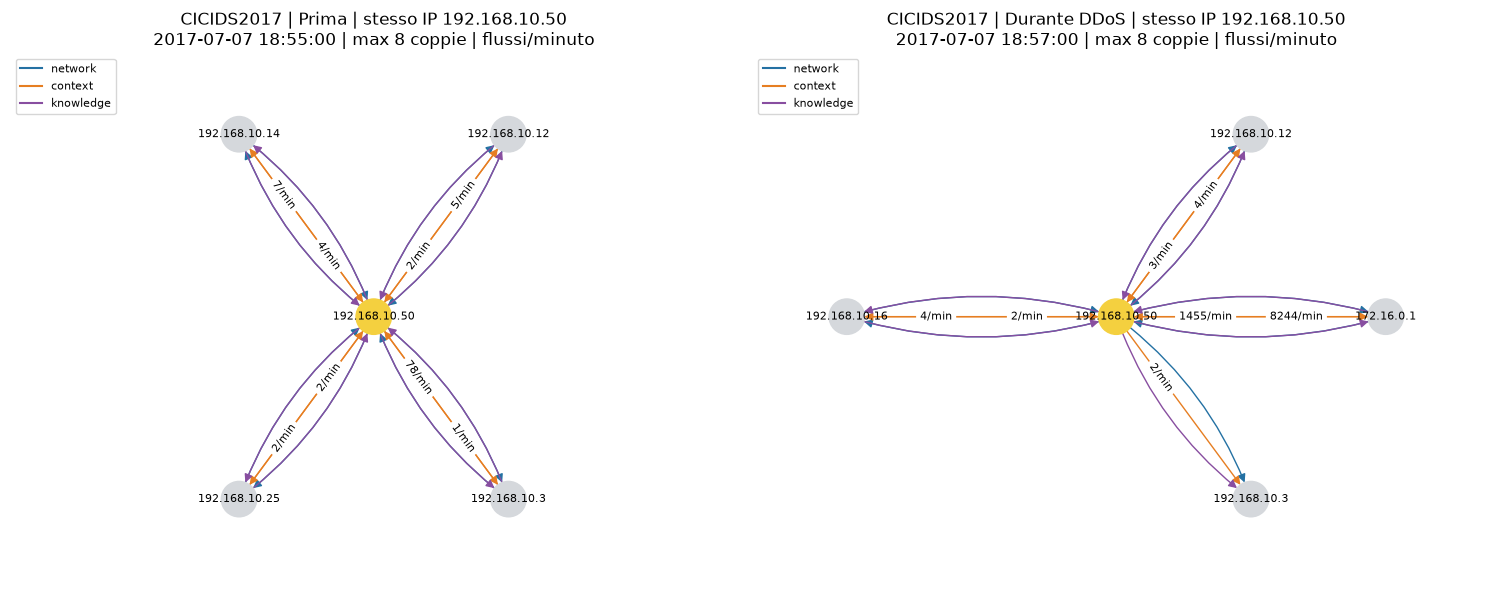

CICToNIoT


,flow,percentuale (%)
attack_type,,
BENIGN,2515236,47.0
xss,2149308,40.16
password,340208,6.36
injection,277696,5.19
scanning,36205,0.68
backdoor,27145,0.51
ransomware,5098,0.1
mitm,517,0.01
ddos,202,0.0


,scenario,IP osservato,minuto,flow benigni,flow attacco
0,prima,192.168.1.1,2019-04-29 19:45:00,9,0
1,durante attacco,192.168.1.1,2019-04-29 22:22:00,13,100


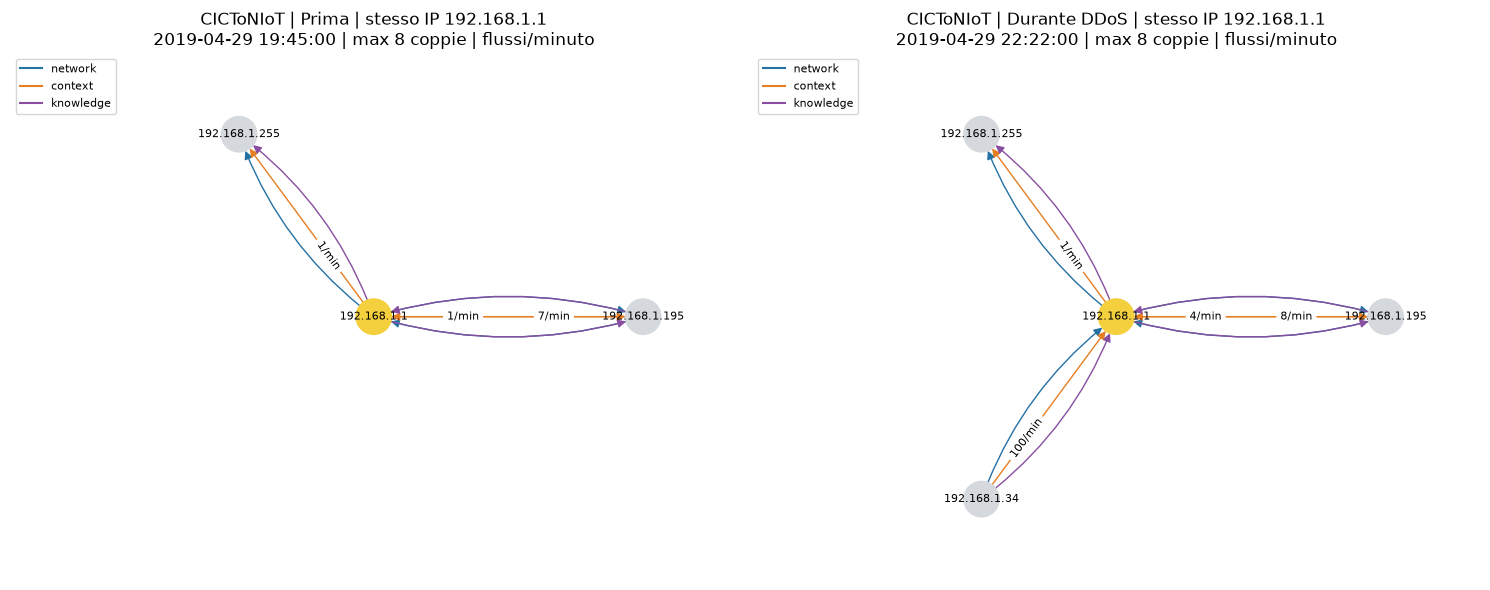

In [2]:
# 2. DIMENSIONI, CLASSI, FEATURE E STESSO HOST PRIMA/DURANTE L'ATTACCO
display(pd.DataFrame([{"dataset": name, "file": len(DATASETS[name]), "righe lette": frame.attrs["rows_read"],
    "scartate": frame.attrs["rows_read"]-len(frame), "flow validi": len(frame),
    "IP": len(set(frame["Source IP"]) | set(frame["Destination IP"])), "grafi/finestre": frame.window.nunique(),
    "benigni": int((frame.target==0).sum()), "attacchi": int(frame.target.sum()),
    "attacchi (%)": round(100*frame.target.mean(), 2)} for name, frame in datasets.items()]))
feature_summary = pd.DataFrame([
    ["network", "Source Port", "Porta del mittente", "edge_attr", "No"],
    ["network", "Destination Port", "Porta del servizio destinatario", "edge_attr", "No"],
    ["context", "Flow Duration", "Durata della comunicazione", "edge_attr", "No"],
    ["context", "Flow IAT Mean", "Intervallo medio fra pacchetti del flow", "edge_attr", "No"],
    ["knowledge", "Packet Length Std", "Variabilita delle dimensioni dei pacchetti", "edge_attr", "No"],
    ["knowledge", "SYN Flag Count", "Pacchetti con flag TCP SYN", "edge_attr", "No"],
    ["nodi", "community", "ID della comunita topologica locale", "x", "Si"],
    ["nodi", "in_degree", "Flow entranti nell'IP nella finestra", "x", "Si"],
    ["nodi", "out_degree", "Flow uscenti dall'IP nella finestra", "x", "Si"],
], columns=["famiglia", "feature", "significato", "dove si trova", "usata dalla GCN"])
display(feature_summary)

def same_host_scenarios(df):
    attacks = df[df["target"] == 1]
    ddos = attacks[attacks["attack_type"].str.contains("ddos", case=False, na=False)]
    if not ddos.empty:
        attacks = ddos
    for host in attacks["Destination IP"].value_counts().index:
        incoming = attacks[attacks["Destination IP"] == host]
        first_attack = incoming["window"].min()
        incident = df[(df["Source IP"] == host) | (df["Destination IP"] == host)]
        earlier = incident[incident["window"] < first_attack]
        benign_windows = earlier.groupby("window")["target"].sum()
        benign_windows = benign_windows[benign_windows == 0]
        if not benign_windows.empty:
            before = incident[incident["window"] == benign_windows.index.max()]
            peak = incoming.groupby("window").size().idxmax()
            during = incident[incident["window"] == peak]
            return host, before, during
    return None


for dataset_name, df in datasets.items():
    print(dataset_name)
    counts = df["attack_type"].value_counts().rename("flow").to_frame()
    counts["percentuale (%)"] = (100*counts["flow"]/len(df)).round(2)
    display(counts)
    scenario = same_host_scenarios(df)
    if scenario is None:
        print("Nessun host con traffico benigno precedente e attacco successivo nei dati selezionati.")
    else:
        host, before, during = scenario
        scenario_summary = pd.DataFrame([
            {"scenario": name, "IP osservato": host, "minuto": part["window"].iloc[0],
             "flow benigni": int((part["target"] == 0).sum()), "flow attacco": int(part["target"].sum())}
            for name, part in [("prima", before), ("durante attacco", during)]
        ])
        display(scenario_summary)
        shown_pairs = []
        for part in [before, during]:
            pairs = part.groupby(["Source IP", "Destination IP"]).size().sort_values(ascending=False)
            shown_pairs.append(pairs.head(MAX_GRAPH_PAIRS))
        union = nx.DiGraph()
        for pairs in shown_pairs:
            union.add_edges_from(pairs.index)
        peers = sorted(set(union.nodes) - {host})
        positions = {host: (0, 0)}
        positions.update({peer: (np.cos(2*np.pi*i/len(peers)), np.sin(2*np.pi*i/len(peers)))
                          for i, peer in enumerate(peers)})
        fig, axes = plt.subplots(1, 2, figsize=(15, 6))
        relation_colors = ["#2471a3", "#e67e22", "#884ea0"]
        for ax, title, part, pairs in zip(axes, ["Prima", "Durante DDoS" if during["attack_type"].str.contains("ddos", case=False, na=False).any() else "Durante attacco"], [before, during], shown_pairs):
            graph = nx.DiGraph()
            graph.add_edges_from(pairs.index)
            nx.draw_networkx_nodes(graph, positions, ax=ax, node_size=650,
                node_color=["#f4d03f" if node == host else "#d5d8dc" for node in graph.nodes])
            nx.draw_networkx_labels(graph, positions, ax=ax, font_size=8)
            for color, radius in zip(relation_colors, [-0.15, 0, 0.15]):
                nx.draw_networkx_edges(graph, positions, ax=ax, node_size=650, edge_color=color,
                    arrowsize=12, connectionstyle=f"arc3,rad={radius}")
            labels = {(u, v): f"{int(count)}/{WINDOW_MINUTES}min" for (u, v), count in pairs.items()}
            nx.draw_networkx_edge_labels(graph, positions, ax=ax, edge_labels=labels, font_size=8, label_pos=0.32)
            ax.legend(handles=[Line2D([0], [0], color=color, label=name)
                               for name, color in zip(SEMANTICS, relation_colors)], loc="upper left", fontsize=8)
            ax.set_title(f"{dataset_name} | {title} | stesso IP {host}\n{part['window'].iloc[0]} | max {MAX_GRAPH_PAIRS} coppie | flow/{WINDOW_MINUTES}min")
            ax.set(xlim=(-1.35, 1.35), ylim=(-1.25, 1.25))
            ax.axis("off")
        plt.tight_layout()
        plt.show()


In [3]:
# 3. GRID SEARCH, EARLY STOPPING, CHECKPOINT E SOGLIA VALIDATION
class HeteroEdgeClassifier(nn.Module):
    def __init__(self, hidden_channels=64, out_channels=32, num_classes=2, dropout=0.2):
        super().__init__()

        self.conv1 = HeteroConv({
            ('ip', 'network', 'ip'): GCNConv(-1, hidden_channels),
            ('ip', 'context', 'ip'): GCNConv(-1, hidden_channels),
            ('ip', 'knowledge', 'ip'): GCNConv(-1, hidden_channels),
            #selected fetures
        }, aggr='sum')

        self.bn1_ip = nn.BatchNorm1d(hidden_channels)

        self.conv2 = HeteroConv({
            ('ip', 'network', 'ip'): GCNConv(hidden_channels, hidden_channels),
            ('ip', 'context', 'ip'): GCNConv(hidden_channels, hidden_channels),
            ('ip', 'knowledge', 'ip'): GCNConv(hidden_channels, hidden_channels),
            #selected fetures
        }, aggr='sum')

        self.bn2_ip = nn.BatchNorm1d(hidden_channels)

        self.lin_node = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels * 2),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_channels * 2, out_channels),
            nn.ReLU()
        )

        self.lin_edge = nn.Sequential(
            nn.Linear(out_channels * 2, out_channels),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(out_channels, out_channels),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(out_channels, num_classes)
        )

    def forward(self, data):
        x_dict = self.conv1(data.x_dict, data.edge_index_dict)
        x_dict['ip'] = (self.bn1_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn1_ip.running_mean, self.bn1_ip.running_var,
                                      self.bn1_ip.weight, self.bn1_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict = self.conv2(x_dict, data.edge_index_dict)
        x_dict['ip'] = (self.bn2_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn2_ip.running_mean, self.bn2_ip.running_var,
                                      self.bn2_ip.weight, self.bn2_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict['ip'] = self.lin_node(x_dict['ip'])
        return x_dict

    def edge_classify(self, z_src, z_dst):
        z_cat = torch.cat([z_src, z_dst], dim=-1)
        logits = self.lin_edge(z_cat)
        return logits



def focal_loss(logits, targets):
    ce = F.cross_entropy(logits, targets, reduction="none")
    return (FOCAL_ALPHA * (1 - torch.exp(-ce)) ** FOCAL_GAMMA * ce).mean()

def graph_loss(model, graph):
    z = model(graph)["ip"]
    return sum(focal_loss(model.edge_classify(z[graph[r].edge_index[0]], z[graph[r].edge_index[1]]),
                          graph[r].edge_label) for r in RELATIONS)

@torch.no_grad()
def predict(model, items, device, batch_size=4):
    model.eval()
    rows = []
    for batch in DataLoader(items, batch_size=batch_size, shuffle=False, num_workers=LOADER_WORKERS):
        batch = batch.to(device)
        z = model(batch)["ip"]
        src, dst = batch[RELATIONS[0]].edge_index
        rows.append(pd.DataFrame({"flow_id": batch.flow_id.cpu().numpy(),
            "target": batch[RELATIONS[0]].edge_label.cpu().numpy(),
            "score": model.edge_classify(z[src], z[dst]).softmax(-1)[:, 1].cpu().numpy()}))
    return pd.concat(rows, ignore_index=True)

def choose_threshold(items):
    if items.target.nunique() != 2:
        raise ValueError("Servono benigni e attacchi per scegliere la soglia F1.")
    if not np.isfinite(items.score).all():
        raise ValueError("Score non finiti.")
    p, r, thresholds = precision_recall_curve(items.target, items.score)
    denominator = p[:-1] + r[:-1]
    f1 = np.divide(2*p[:-1]*r[:-1], denominator, out=np.zeros_like(denominator), where=denominator>0)
    return float(thresholds[np.flatnonzero(f1 == f1.max())[-1]])

def split_graphs(graphs, seed=None):
    if seed is None:
        seed = SPLIT_SEED
    if len(graphs)<3:
        raise ValueError("Servono almeno tre finestre per train, validation e test.")
    rest_size = max(2, int(np.ceil((HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION)*len(graphs))))
    if rest_size>=len(graphs):
        raise ValueError("Le frazioni holdout lasciano troppo pochi grafi nel train")
    indices = np.arange(len(graphs))
    strata = np.array([int(g[RELATIONS[0]].edge_label.max()) for g in graphs])
    classes, counts = np.unique(strata,return_counts=True)
    stratify = strata if min(counts)>=4 and min(rest_size,len(graphs)-rest_size)>=len(classes) else None
    train, rest = train_test_split(indices,test_size=rest_size,random_state=seed,stratify=stratify)
    ratio = HOLDOUT_TEST_FRACTION/(HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION)
    test_size = min(len(rest)-1,max(1,int(np.ceil(ratio*len(rest)))))
    classes, counts = np.unique(strata[rest],return_counts=True)
    stratify = strata[rest] if min(counts)>=2 and min(test_size,len(rest)-test_size)>=len(classes) else None
    val, test = train_test_split(rest,test_size=test_size,random_state=seed,stratify=stratify)
    return [[graphs[i] for i in part] for part in [train,val,test]]

def new_model(params):
    return HeteroEdgeClassifier(**{k: params[k] for k in ["hidden_channels", "out_channels", "dropout"]})

def save_checkpoint(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)

def train_model(train_items, val_items, params, checkpoint_path, max_epochs, patience, min_delta):
    if max_epochs < 1 or (EARLY_STOPPING and (patience < 1 or min_delta < 0 or not np.isfinite(min_delta))):
        raise ValueError("Epoche/patience positive e min_delta non negativo.")
    seed_everything(SEED)
    model = new_model(params).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_items, batch_size=params["batch_size"], shuffle=True,
                              generator=generator, num_workers=LOADER_WORKERS)
    val_loader = DataLoader(val_items, batch_size=params["batch_size"], shuffle=False, num_workers=LOADER_WORKERS)
    history, best_loss, significant_loss, stale = [], float("inf"), float("inf"), 0
    progress = tqdm(range(1, max_epochs+1), desc=Path(checkpoint_path).stem, unit="epoca", position=0, leave=True)
    for epoch in progress:
        model.train()
        train_sum, train_count = 0., 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            loss = graph_loss(model, batch)
            if not torch.isfinite(loss):
                raise RuntimeError("Loss train non finita.")
            loss.backward()
            optimizer.step()
            count = batch[RELATIONS[0]].num_edges
            train_sum += loss.item()*count
            train_count += count
        model.eval()
        val_sum, val_count = 0., 0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(DEVICE)
                count = batch[RELATIONS[0]].num_edges
                val_sum += graph_loss(model, batch).item()*count
                val_count += count
        train_loss, val_loss = train_sum/train_count, val_sum/val_count
        if not np.isfinite(val_loss):
            raise RuntimeError("Loss validation non finita.")
        history.append({"epoca": epoch, "train": train_loss, "validation": val_loss})
        if val_loss < best_loss:
            best_loss = val_loss
            save_checkpoint({"state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "params": params, "best_epoch": epoch, "validation_loss": val_loss, "seed": SEED}, checkpoint_path)
        if EARLY_STOPPING:
            if val_loss < significant_loss - min_delta:
                significant_loss, stale = val_loss, 0
            else:
                stale += 1
        progress.set_postfix(train=f"{train_loss:.5f}", validation=f"{val_loss:.5f}", attesa=stale if EARLY_STOPPING else "off")
        if EARLY_STOPPING and stale >= patience:
            break
    progress.close()
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model.load_state_dict(checkpoint["state_dict"])
    validation = predict(model, val_items, DEVICE, params["batch_size"])
    threshold = choose_threshold(validation)
    vp, vr, vf1, _ = precision_recall_fscore_support(validation.target, validation.score>=threshold,
                                                   average="binary", zero_division=0)
    checkpoint.update({"threshold": threshold, "history": history,
        "validation_F1": float(vf1), "validation_AP": float(average_precision_score(validation.target, validation.score)),
        "epochs_run": len(history), "stopped_early": len(history)<max_epochs, "early_stopping": EARLY_STOPPING,
        "focal_alpha": FOCAL_ALPHA, "focal_gamma": FOCAL_GAMMA})
    save_checkpoint(checkpoint, checkpoint_path)
    return checkpoint

def flow_counts(flows):
    return flows.groupby(["window", "Source IP", "Destination IP"]).size().rename("flow_count").reset_index()

def count_features(flows):
    result = flows[["flow_id", "window", "Source IP", "Destination IP", "target", "attack_type"]].merge(
        flow_counts(flows), on=["window", "Source IP", "Destination IP"], validate="many_to_one")
    result["source_out"] = result.groupby(["window", "Source IP"])["flow_id"].transform("size")
    result["destination_in"] = result.groupby(["window", "Destination IP"])["flow_id"].transform("size")
    return result

def fit_count_thresholds(train_flows):
    counts = flow_counts(train_flows).flow_count
    if counts.empty:
        raise ValueError("Nessuna coppia IP/minuto nel train.")
    return {f"P{q:g}": float(counts.quantile(q/100)) for q in COUNT_PERCENTILES}


def evaluation_splits(graphs, dataset_name):
    count = N_FOLDS.get(dataset_name, 1)
    if isinstance(count, bool) or not isinstance(count, int) or not 1 <= count <= len(graphs):
        raise ValueError(f"{dataset_name}: N_FOLDS deve essere 1 oppure un intero da 2 a {len(graphs)}")
    if len({g.window for g in graphs}) != len(graphs):
        raise ValueError("Ogni minuto deve corrispondere a un solo grafo prima dei fold")
    selected = FOLDS_TO_RUN.get(dataset_name)
    if selected is not None:
        if (not isinstance(selected, (list,tuple)) or not selected
            or any(isinstance(f,bool) or not isinstance(f,int) or not 1 <= f <= count for f in selected)
            or len(set(selected)) != len(selected)):
            raise ValueError(f"{dataset_name}: FOLDS_TO_RUN deve essere None o una lista senza duplicati fra 1 e {count}")
    if count == 1:
        return [(1, *split_graphs(graphs, SPLIT_SEED))]
    strata = np.array([int(g[RELATIONS[0]].edge_label.max()) for g in graphs])
    counts = np.unique(strata, return_counts=True)[1]
    splitter = (StratifiedKFold(count, shuffle=True, random_state=SPLIT_SEED) if min(counts) >= count
                else KFold(count, shuffle=True, random_state=SPLIT_SEED))
    folds = []
    for fold, (remaining, test) in enumerate(splitter.split(np.arange(len(graphs)), strata), 1):
        if selected is not None and fold not in selected:
            continue
        if len(remaining) < 3:
            raise ValueError("Troppi pochi grafi per separare train e validation dentro ogni fold")
        labels = strata[remaining]
        classes, frequencies = np.unique(labels, return_counts=True)
        val_size = int(np.ceil(KFOLD_VAL_FRACTION*len(remaining)))
        stratify = labels if min(frequencies)>=2 and val_size>=len(classes) and len(remaining)-val_size>=len(classes) else None
        train, val = train_test_split(remaining, test_size=KFOLD_VAL_FRACTION, random_state=SPLIT_SEED, stratify=stratify)
        parts = [[graphs[i] for i in indices] for indices in [train,val,test]]
        for name, part in zip(["train","validation","test"],parts):
            labels = {int(y) for g in part for y in g[RELATIONS[0]].edge_label.unique().tolist()}
            if labels != {0,1}:
                raise ValueError(f"{dataset_name}, fold {fold}: {name} non contiene entrambe le classi; ridurre i fold o cambiare split")
        folds.append((fold,*parts))
    tested = [g.window for _,_,_,test in folds for g in test]
    assert len(tested) == len(set(tested)), "Finestre ripetute nei test esterni"
    if selected is None:
        assert set(tested) == {g.window for g in graphs}, "K-fold incompleta"
    return folds

experiments = {}
for dataset_name, df in datasets.items():
    graphs = [build_graph(part) for _, part in tqdm(df.groupby("window", sort=True), desc=f"Grafi {dataset_name}")]
    assert sum(g[RELATIONS[0]].num_edges for g in graphs) == len(df)
    n_folds = N_FOLDS.get(dataset_name,1)
    if not GRID_SEARCH and dataset_name not in MODEL_PARAMS:
        raise ValueError(f"Mancano MODEL_PARAMS per {dataset_name}")
    fold_splits = evaluation_splits(graphs,dataset_name)
    for fold, train_graphs, val_graphs, test_graphs in fold_splits:
        folder = RUN_DIR/dataset_name
        if n_folds>1:
            folder = folder/f"fold_{fold:02d}"
        folder.mkdir(parents=True,exist_ok=True)
        experiment_key = dataset_name if n_folds==1 else f"{dataset_name}/fold_{fold:02d}"
        print(f"{dataset_name} | fold {fold}/{n_folds}",flush=True)
        parts = [train_graphs, val_graphs, test_graphs]
        windows = [{g.window for g in part} for part in parts]
        ids = [{int(i) for g in part for i in g.flow_id.tolist()} for part in parts]
        assert all(windows[i].isdisjoint(windows[j]) and ids[i].isdisjoint(ids[j]) for i in range(3) for j in range(i))
        assert all(len({int(y) for g in part for y in g[RELATIONS[0]].edge_label.unique().tolist()}) == 2 for part in parts), "Ogni split deve contenere benigni e attacchi"
        split_table = pd.DataFrame([{"split": name, "grafi": len(part), "flow": len(flow_ids),
            "attacchi": sum(int(g[RELATIONS[0]].edge_label.sum()) for g in part)}
            for name, part, flow_ids in zip(["train", "validation", "test"], parts, ids)])
        print(dataset_name, "| 0 finestre e 0 flow_id condivisi; split di grafi interi, train/validation/test disgiunti")
        display(split_table)
        split_table.to_csv(folder/"split_summary.csv", index=False)
        pd.DataFrame([{"flow_id": i, "split": name} for name, flow_ids in zip(["train", "validation", "test"], ids)
                      for i in sorted(flow_ids)]).to_csv(folder/"split_flows.csv", index=False)
        grid_rows, champion, champion_path = [], None, None
        grid = (list(ParameterGrid(PARAM_GRID)) if GRID_SEARCH else [MODEL_PARAMS[dataset_name]])
        for trial, params in enumerate(grid, 1):
            print(f"{dataset_name} | configurazione {trial}/{len(grid)}", flush=True)
            checkpoint_path = folder / "checkpoints" / f"trial_{trial:03d}.pt"
            start = time.perf_counter()
            checkpoint = train_model(train_graphs, val_graphs, params, checkpoint_path, MAX_EPOCHS, PATIENCE, MIN_DELTA)
            row = {"trial": trial, **params, **{k: checkpoint[k] for k in ["best_epoch", "epochs_run", "stopped_early", "validation_loss", "validation_F1", "validation_AP", "threshold"]},
                   "seconds": time.perf_counter()-start}
            grid_rows.append(row)
            pd.DataFrame(grid_rows).to_csv(folder/"grid_search.csv", index=False)
            rank = (checkpoint["validation_F1"], checkpoint["validation_AP"], -checkpoint["validation_loss"])
            if champion is None or rank > (champion["validation_F1"], champion["validation_AP"], -champion["validation_loss"]):
                champion, champion_path = checkpoint, checkpoint_path
                save_checkpoint(checkpoint, folder/"best_model.pt")
            print(f"{dataset_name} trial {trial}: F1 val {100*checkpoint['validation_F1']:.2f}% | epoca {checkpoint['best_epoch']}")
        display(pd.DataFrame(grid_rows).sort_values(["validation_F1", "validation_AP", "validation_loss"], ascending=[False,False,True]).head(5))
        print("Scelto:", champion_path.name, champion["params"], "| soglia validation:", champion["threshold"])
        experiments[experiment_key] = {"dataset": dataset_name, "fold": fold, "n_folds": n_folds, "folder": folder, "best": champion, "test_graphs": test_graphs,
            "train_ids": np.fromiter(ids[0], dtype=np.int64), "val_ids": np.fromiter(ids[1], dtype=np.int64), "test_ids": np.fromiter(ids[2], dtype=np.int64), "grid_rows": grid_rows}
        del train_graphs, val_graphs, parts
        gc.collect()
    del graphs,fold_splits
    gc.collect()


Grafi CICIDS2017: 100%|██████████| 2454/2454 [00:22<00:00, 111.05it/s]


CICIDS2017 | 0 finestre e 0 flow_id condivisi; split casuale per grafi 70/15/15


,split,grafi,flow,attacchi
0,train,1717,2008166,407753
1,validation,368,450896,108516
2,test,369,371681,41377


Grid CICIDS2017:   6%|▋         | 1/16 [02:13<33:29, 133.95s/it]


CICIDS2017 trial 1: F1 val 97.10% | epoca 8


...

CICToNIoT trial 15: F1 val 93.60% | epoca 4


Grid CICToNIoT: 100%|██████████| 16/16 [1:11:03<00:00, 266.48s/it]


CICToNIoT trial 16: F1 val 94.12% | epoca 5


,trial,batch_size,dropout,hidden_channels,lr,out_channels,weight_decay,best_epoch,epochs_run,stopped_early,validation_loss,validation_F1,validation_AP,threshold,seconds
0,1,4,0.2,32,0.0010,16,0.0001,1,11,True,0.054405,0.973844,0.977411,0.335598,217.872235
1,2,4,0.2,32,0.0010,16,0.0010,1,11,True,0.056975,0.970488,0.964782,0.332523,216.251891
11,12,4,0.2,64,0.0010,32,0.0010,3,13,True,0.029767,0.967989,0.985728,0.561371,262.567572
13,14,4,0.2,64,0.0003,16,0.0010,5,15,True,0.036921,0.967293,0.983328,0.437718,298.916865
9,10,4,0.2,64,0.0010,16,0.0010,1,11,True,0.034324,0.966468,0.978436,0.477671,219.828434


Scelto: trial_001.pt {'batch_size': 4, 'dropout': 0.2, 'hidden_channels': 32, 'lr': 0.001, 'out_channels': 16, 'weight_decay': 0.0001} | soglia validation: 0.3355983793735504


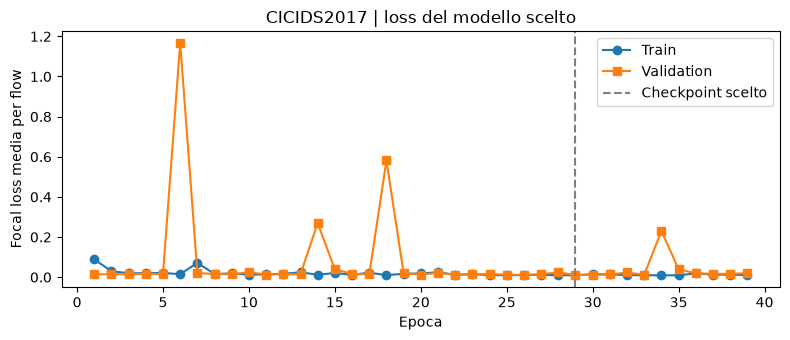

CICIDS2017 | percentili train: {'P90': 5.0, 'P95': 9.0, 'P99': 62.0} | soglia F1 train: 2048.0
Albero appreso sul train:
|--- source_out <= 3955.00
|   |--- class: 0
|--- source_out >  3955.00
|   |--- class: 1

Accuracy sempre benigno: 88.87%
CICIDS2017 | confronto sullo stesso test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),falsi allarmi,attacchi mancati
modello,,,,,,,,
GCN,87.37,94.36,81.34,97.38,95.20,99.04,2012,7719
Dummy P90,27.30,15.82,99.69,40.90,90.37,96.13,219518,127
Dummy P95,29.73,17.48,99.28,47.75,90.37,96.13,193923,297
Dummy P99,36.65,22.55,97.77,62.37,90.37,96.13,138946,924
Dummy soglia train,89.71,100.00,81.34,97.92,90.37,96.13,0,7719
Albero profondita 1,81.41,88.39,75.45,96.16,69.43,87.11,4100,10156


Controllo aggregato per coppia IP/minuto (target diverso dal singolo flow):


,totali,attacchi reali,F1 (%),falsi allarmi,attacchi mancati
modello,,,,,
GCN,74430,161,5.41,19,156
Dummy P90,74430,161,1.99,7203,87
Dummy P95,74430,161,2.67,3455,112
Dummy P99,74430,161,7.07,712,129
Dummy soglia train,74430,161,6.02,0,156
Albero profondita 1,74430,161,5.59,13,156


GCN per famiglia reale: corretti (%) = recall per attacco, specificita per BENIGN


,flow,corretti (%)
attack_type,,
BENIGN,330304.0,99.39
Bot,290.0,0.00
DDoS,23219.0,100.00
DoS Hulk,10439.0,100.00
DoS Slowhttptest,3193.0,0.00
DoS slowloris,259.0,0.00
FTP-Patator,1488.0,0.00
Heartbleed,2.0,0.00
Infiltration,5.0,0.00


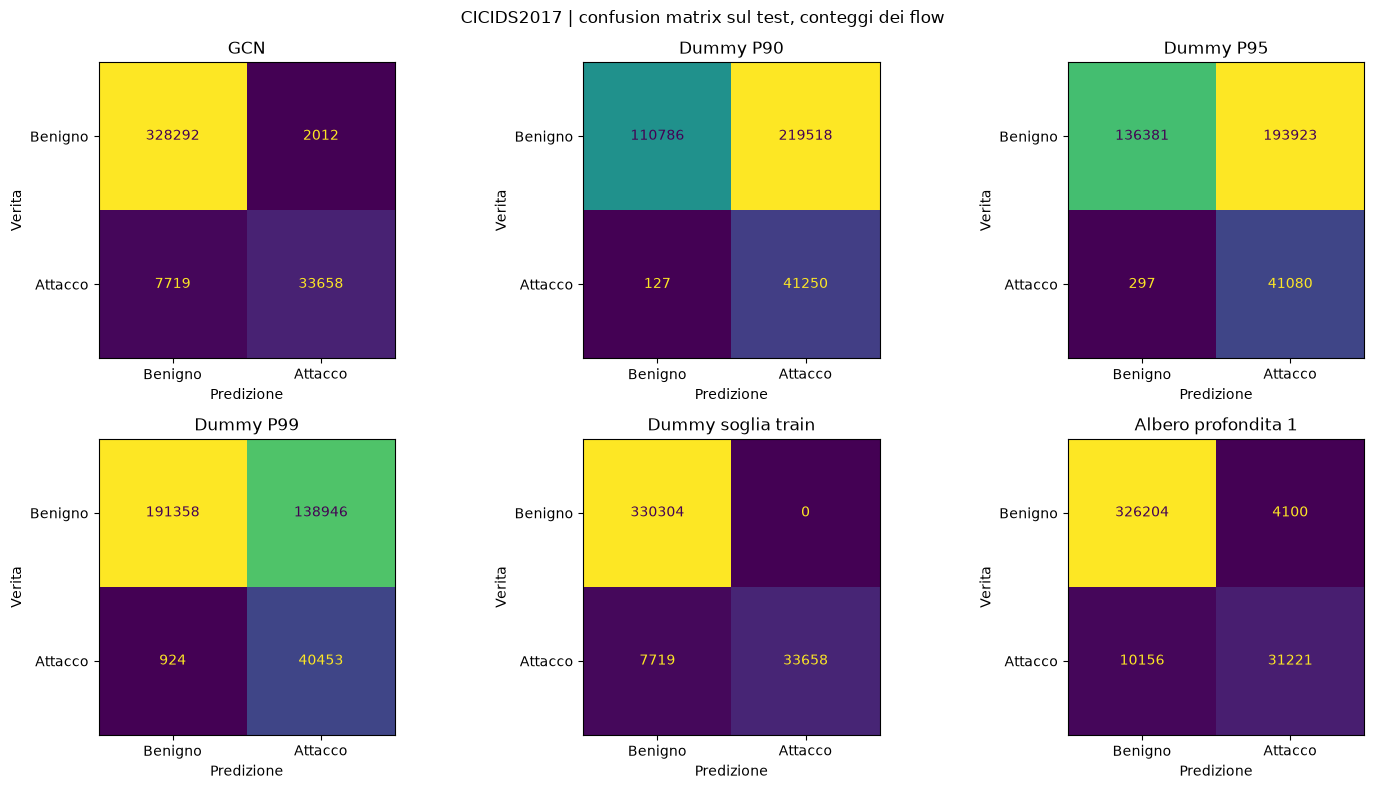

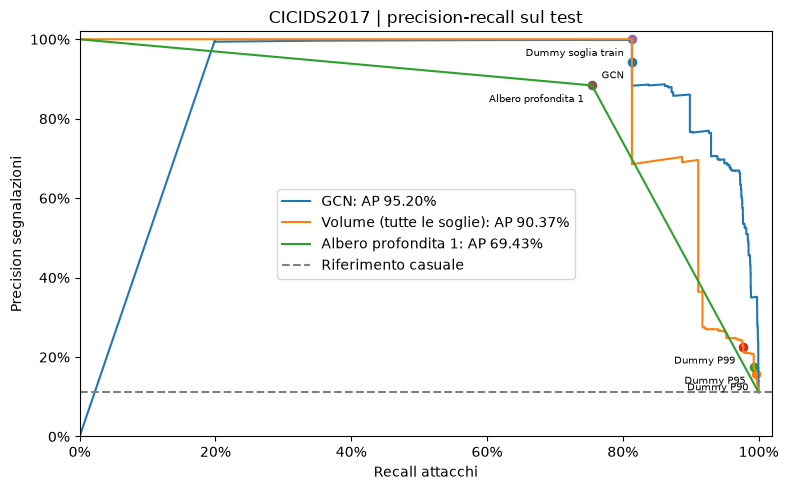

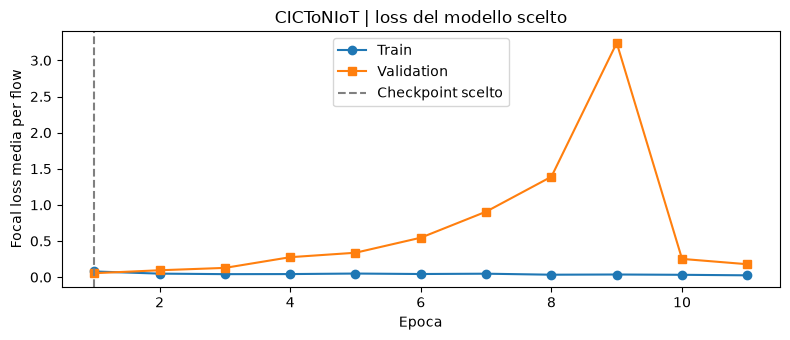

CICToNIoT | percentili train: {'P90': 1.0, 'P95': 2.0, 'P99': 272.0} | soglia F1 train: 54.0
Albero appreso sul train:
|--- source_out <= 1492.50
|   |--- class: 0
|--- source_out >  1492.50
|   |--- class: 1

Accuracy sempre benigno: 47.08%
CICToNIoT | confronto sullo stesso test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),falsi allarmi,attacchi mancati
modello,,,,,,,,
GCN,96.57,96.06,97.09,96.35,95.11,97.64,17582,12855
Dummy P90,74.20,59.00,99.96,63.22,64.21,68.34,306535,180
Dummy P95,74.36,59.21,99.92,63.53,64.21,68.34,303778,349
Dummy P99,73.36,61.22,91.50,64.83,64.21,68.34,255808,37491
Dummy soglia train,74.83,60.31,98.58,64.91,64.21,68.34,286319,6265
Albero profondita 1,88.27,82.20,95.31,86.60,80.83,86.06,91047,20714


Controllo aggregato per coppia IP/minuto (target diverso dal singolo flow):


,totali,attacchi reali,F1 (%),falsi allarmi,attacchi mancati
modello,,,,,
GCN,91065,1555,66.32,368,601
Dummy P90,91065,1555,43.06,3457,180
Dummy P95,91065,1555,52.40,2079,265
Dummy P99,91065,1555,43.58,358,1022
Dummy soglia train,91065,1555,51.91,556,815
Albero profondita 1,91065,1555,70.10,146,637


GCN per famiglia reale: corretti (%) = recall per attacco, specificita per BENIGN


,flow,corretti (%)
attack_type,,
BENIGN,392588.0,95.52
backdoor,3990.0,0.00
ddos,66.0,3.03
dos,32.0,3.12
injection,38501.0,99.93
mitm,216.0,0.93
password,48789.0,99.38
ransomware,446.0,0.00
scanning,5188.0,95.12


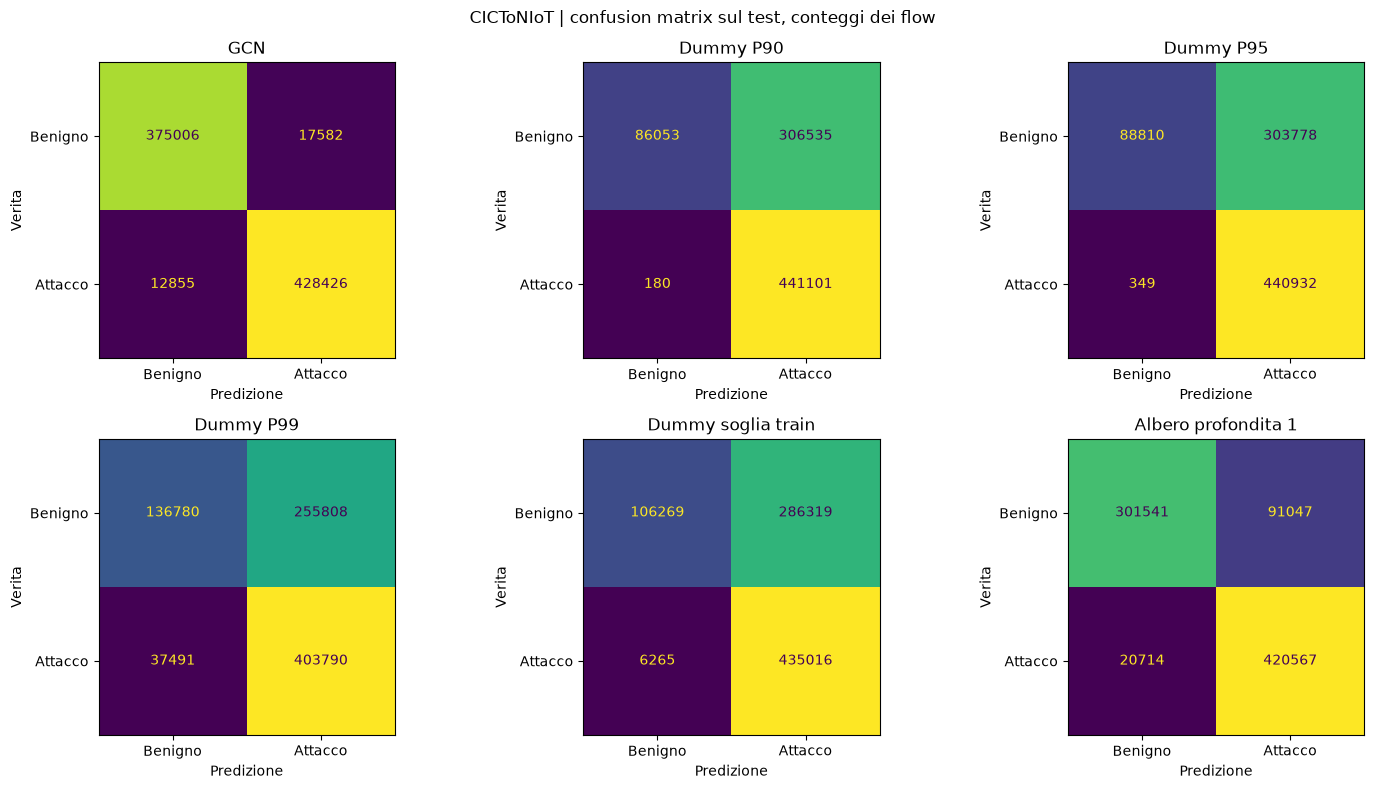

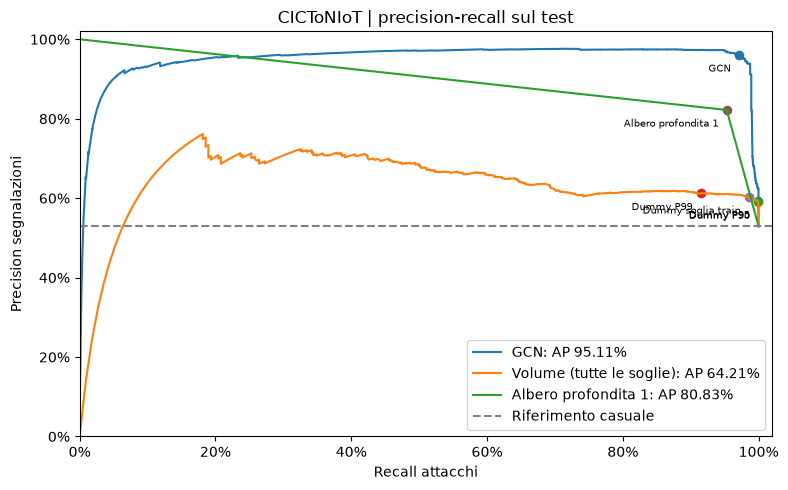

Esperimento completato. Risultati e checkpoint: data\marco_output\20261024_145428_252015


In [ ]:
# 4. TEST, BASELINE E CONFRONTO FINALE
def evaluation_metrics(target, score, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(target, predicted, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(target, predicted, labels=[0, 1]).ravel()
    both = len(np.unique(target)) == 2
    return {"F1 (%)": 100*f1, "precision (%)": 100*precision, "recall (%)": 100*recall,
        "accuracy (%)": 100*accuracy_score(target, predicted),
        "AP (%)": 100*average_precision_score(target, score) if both else None,
        "ROC-AUC (%)": 100*roc_auc_score(target, score) if both else None,
        "balanced accuracy (%)": 100*balanced_accuracy_score(target, predicted),
        "MCC": float(matthews_corrcoef(target, predicted)),
        "veri negativi": int(tn), "falsi allarmi": int(fp), "attacchi mancati": int(fn), "veri positivi": int(tp),
        "FPR (%)": 100*fp/(fp+tn) if fp+tn else None}


def summarize_folds(comparisons, pair_rows, experiments, datasets, run_dir):
    metrics = ["F1 (%)","precision (%)","recall (%)","accuracy (%)","AP (%)","ROC-AUC (%)",
               "balanced accuracy (%)","MCC","FPR (%)","falsi allarmi","attacchi mancati"]
    for rows, filename in [(comparisons,"summary_test.csv"),(pair_rows,"summary_pairs.csv")]:
        frame = pd.DataFrame(rows)
        grouped = frame.groupby(["dataset","modello"])
        stats = grouped[metrics].agg(["mean","std"])
        stats.columns = [f"{metric} {stat}" for metric,stat in stats.columns]
        stats.insert(0,"fold eseguiti",grouped["fold"].nunique())
        stats.to_csv(run_dir/filename)
        print(filename,"| media e deviazione standard fra i fold; std non stimabile con un solo fold")
        display(stats[["fold eseguiti","F1 (%) mean","F1 (%) std","recall (%) mean","falsi allarmi mean"]].round(2))
    coverage = []
    for name,df in datasets.items():
        runs = [e for e in experiments.values() if e["dataset"]==name]
        tested = [int(i) for e in runs for i in e["test_ids"]]
        assert len(tested)==len(set(tested)), "Flow valutati in piu test esterni"
        configured = runs[0]["n_folds"]
        if configured>1 and len(runs)==configured:
            assert set(tested)==set(df.flow_id), "La k-fold completa deve valutare tutti i flow"
        coverage.append({"dataset":name,"fold configurati":configured,"fold eseguiti":len(runs),
                         "flow test unici":len(tested),"flow dataset":len(df),"copertura (%)":100*len(tested)/len(df)})
    coverage = pd.DataFrame(coverage)
    coverage.to_csv(run_dir/"test_coverage.csv",index=False)
    display(coverage.round(2))

all_comparisons, all_pairs = [], []
for experiment in experiments.values():
    dataset_name = experiment["dataset"]
    fold, n_folds = experiment["fold"], experiment["n_folds"]
    print(f"{dataset_name} | test fold {fold}/{n_folds}")
    folder, df = experiment["folder"], datasets[dataset_name]
    best = torch.load(folder/"best_model.pt", map_location="cpu", weights_only=True)
    model = new_model(best["params"])
    model.load_state_dict(best["state_dict"])
    model = model.to(DEVICE)
    predictions = predict(model, experiment["test_graphs"], DEVICE, best["params"]["batch_size"])
    assert predictions.flow_id.is_unique and set(predictions.flow_id) == set(experiment["test_ids"])
    predictions["prediction"] = (predictions.score >= best["threshold"]).astype(int)
    predictions = predictions.merge(df[["flow_id", "window", "Source IP", "Destination IP", "attack_type"]],
                                     on="flow_id", validate="one_to_one")
    history = pd.DataFrame(best["history"]).set_index("epoca")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(history.index, history.train, marker="o", label="Train")
    ax.plot(history.index, history.validation, marker="s", label="Validation")
    ax.axvline(best["best_epoch"], color="gray", linestyle="--", label="Checkpoint scelto")
    ax.set(title=f"{dataset_name} | fold {fold}/{n_folds} | loss del modello scelto", xlabel="Epoca", ylabel="Focal loss media per flow")
    ax.legend(); fig.tight_layout(); fig.savefig(folder/"loss.png", dpi=PLOT_DPI); plt.show()

    train_flows = df[df.flow_id.isin(experiment["train_ids"])]
    test_flows = df[df.flow_id.isin(experiment["test_ids"])]
    train_counts = count_features(train_flows)
    count_predictions = count_features(test_flows).set_index("flow_id").loc[predictions.flow_id].reset_index()
    thresholds = fit_count_thresholds(train_flows)
    count_train_threshold = choose_threshold(train_counts[["target", "flow_count"]].rename(columns={"flow_count": "score"}))
    stump = DecisionTreeClassifier(max_depth=TREE_MAX_DEPTH, random_state=SEED).fit(train_counts[STUMP_FEATURES], train_counts.target)
    stump_rule = export_text(stump, feature_names=STUMP_FEATURES, decimals=2)
    print(dataset_name, "| percentili train:", thresholds, "| soglia F1 train:", count_train_threshold)
    print("Albero appreso sul train:\n" + stump_rule)
    print(f"Accuracy sempre benigno: {100*(predictions.target==0).mean():.2f}%")
    specs = [("GCN", predictions.score.to_numpy(), predictions.prediction.to_numpy(), f"score >= {best['threshold']:.8g}")]
    for name, threshold in thresholds.items():
        count_predictions[name] = (count_predictions.flow_count > threshold).astype(int)
        specs.append((f"Dummy {name}", count_predictions.flow_count.to_numpy(), count_predictions[name].to_numpy(), f"flow > {threshold:g}"))
    count_predictions["Soglia_train"] = (count_predictions.flow_count >= count_train_threshold).astype(int)
    count_predictions["Albero"] = stump.predict(count_predictions[STUMP_FEATURES])
    specs.extend([
        ("Dummy soglia train", count_predictions.flow_count.to_numpy(), count_predictions.Soglia_train.to_numpy(), f"flow >= {count_train_threshold:g}"),
        (f"Albero profondita {TREE_MAX_DEPTH}", stump.predict_proba(count_predictions[STUMP_FEATURES])[:, 1], count_predictions.Albero.to_numpy(), "Regola train stampata sopra"),
    ])
    y = predictions.target.to_numpy()
    comparison_rows, unit_rows, reports = [], [], {}
    for name, scores, guessed, rule in specs:
        comparison_rows.append({"dataset": dataset_name, "fold": fold, "modello": name, "regola": rule,
                                **evaluation_metrics(y, scores, guessed)})
        pairs = predictions[["window", "Source IP", "Destination IP", "target"]].assign(score=scores, prediction=guessed)
        # Una coppia/minuto e positiva se contiene almeno un flow di attacco.
        pairs = pairs.groupby(["window", "Source IP", "Destination IP"]).agg(
            target=("target", "max"), score=("score", "max"), prediction=("prediction", "max"))
        unit_rows.append({"dataset":dataset_name,"fold":fold,"modello": name, "unita": "coppia IP/finestra", "totali": len(pairs),
                          "attacchi reali": int(pairs.target.sum()),
                          **evaluation_metrics(pairs.target, pairs.score, pairs.prediction)})
        reports[name] = classification_report(y, guessed, labels=[0, 1], target_names=["BENIGN", "ATTACK"],
                                               output_dict=True, zero_division=0)
    comparison = pd.DataFrame(comparison_rows).set_index("modello")
    columns = ["F1 (%)", "precision (%)", "recall (%)", "accuracy (%)", "AP (%)", "ROC-AUC (%)", "falsi allarmi", "attacchi mancati"]
    print(dataset_name, "| confronto sullo stesso test: una decisione per flow")
    display(comparison[columns].round(2))
    print("Controllo aggregato per coppia IP/finestra (target diverso dal singolo flow):")
    display(pd.DataFrame(unit_rows).set_index("modello")[["totali", "attacchi reali", "F1 (%)", "falsi allarmi", "attacchi mancati"]].round(2))
    attack_results = predictions.groupby("attack_type").apply(
        lambda part: pd.Series({"flow": len(part), "corretti (%)": 100*(part.target==part.prediction).mean()}))
    print("GCN per famiglia reale: corretti (%) = recall per attacco, specificita per BENIGN")
    display(attack_results.round(2))

    cols = min(3,len(specs)); rows = int(np.ceil(len(specs)/cols))
    fig, axes = plt.subplots(rows,cols,figsize=(5*cols,4*rows),squeeze=False)
    for ax, (name, scores, guessed, rule) in zip(axes.flat, specs):
        ConfusionMatrixDisplay(confusion_matrix(y, guessed, labels=[0, 1]), display_labels=["Benigno", "Attacco"]).plot(
            ax=ax, colorbar=False, values_format="d")
        ax.set(title=name, xlabel="Predizione", ylabel="Verita")
    for ax in list(axes.flat)[len(specs):]:
        ax.axis("off")
    fig.suptitle(f"{dataset_name} | fold {fold}/{n_folds} | confusion matrix sul test, conteggi dei flow")
    fig.tight_layout(); fig.savefig(folder/"confusion_matrices.png", dpi=PLOT_DPI); plt.show()
    fig, ax = plt.subplots(figsize=(8, 5))
    for index in [0, 1, len(specs)-1]:
        name, scores, guessed, rule = specs[index]
        precision, recall, _ = precision_recall_curve(y, scores)
        label = "Volume (tutte le soglie)" if index == 1 else name
        ax.plot(recall, precision, label=f"{label}: AP {average_precision_score(y, scores)*100:.2f}%")
    for name, scores, guessed, rule in specs:
        precision, recall, _, _ = precision_recall_fscore_support(y, guessed, average="binary", zero_division=0)
        ax.scatter([recall], [precision], s=35)
        ax.annotate(name, (recall, precision), xytext=(-6, -12), textcoords="offset points", ha="right", fontsize=7)
    ax.axhline(y.mean(), color="gray", linestyle="--", label="Riferimento casuale")
    ax.set(title=f"{dataset_name} | fold {fold}/{n_folds} | precision-recall sul test", xlabel="Recall attacchi", ylabel="Precision segnalazioni",
           xlim=(0, 1.02), ylim=(0, 1.02))
    ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(); fig.tight_layout(); fig.savefig(folder/"precision_recall.png", dpi=PLOT_DPI); plt.show()

    predictions.to_csv(folder/"predictions.csv", index=False)
    count_predictions.to_csv(folder/"count_baseline_predictions.csv", index=False)
    comparison.to_csv(folder/"comparison_test.csv")
    pd.DataFrame(unit_rows).to_csv(folder/"unit_comparison.csv", index=False)
    attack_results.to_csv(folder/"gcn_attack_families.csv")
    run = {"dataset": dataset_name, "files": [str(p) for p in DATASETS[dataset_name]], "rows": len(df),
        "windows": int(df.window.nunique()), "device": DEVICE_NAME, "cpu_threads": CPU_THREADS,
        "seed": SEED, "params": best["params"], "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "min_delta": MIN_DELTA,
        "best_epoch": best["best_epoch"], "epochs_run": best["epochs_run"], "threshold": best["threshold"],
        "selection": "checkpoint min validation loss; trial max validation F1, AP, then min loss; threshold max validation F1",
        "split": "random minute graphs 70/15/15; stratified by attack presence when possible",
        "test_flows": len(y), "test_attacks": int(y.sum()), "edge_features_used_by_model": False,
        "count_baseline_thresholds": thresholds, "count_train_threshold": count_train_threshold, "stump_rule": stump_rule,
        "loss_history": best["history"], "comparison": comparison.reset_index().to_dict("records"),
        "classification_reports": reports, "accuracy_always_benign": float((y==0).mean()),
        "torch": str(torch.__version__), "pyg": str(torch_geometric.__version__)}
    run.update({"fold":fold,"n_folds":n_folds,
        "evaluation":"holdout" if n_folds==1 else "outer graph k-fold with inner validation",
        "grid_search":GRID_SEARCH,
        "cv_scope":"holdout" if n_folds==1 else ("grid selected on inner validation" if GRID_SEARCH else "fixed configuration; not a new cross-validated hyperparameter search"),
        "split":"disjoint minute graphs; shared by all compared models; external fold never used for checkpoint/threshold selection"})
    run.update({"grid_search":GRID_SEARCH,"early_stopping":EARLY_STOPPING,"split_seed":SPLIT_SEED,
        "holdout_test_fraction":HOLDOUT_TEST_FRACTION,"holdout_validation_fraction":HOLDOUT_VAL_FRACTION,
        "kfold_validation_fraction":KFOLD_VAL_FRACTION,"window_minutes":WINDOW_MINUTES,
        "focal_alpha":FOCAL_ALPHA,"focal_gamma":FOCAL_GAMMA,"count_percentiles":COUNT_PERCENTILES,
        "tree_max_depth":TREE_MAX_DEPTH,"loader_workers":LOADER_WORKERS,"gpu_requested":USE_GPU})
    (folder/"run.json").write_text(json.dumps(run, indent=2), encoding="utf-8")
    all_comparisons.extend(comparison_rows)
    all_pairs.extend(unit_rows)
    del model, train_counts, count_predictions
    gc.collect()
pd.DataFrame(all_comparisons).to_csv(RUN_DIR/"comparison_all_datasets.csv", index=False)
print("Esperimento completato. Risultati e checkpoint:", RUN_DIR)

summarize_folds(all_comparisons,all_pairs,experiments,datasets,RUN_DIR)


## V2 - Ibrid DGM HGNN

In [ ]:
# V2 / 1. CONFIGURAZIONE E DATI COMPLETI

from pathlib import Path

from datetime import datetime
import os

# MODIFICA QUESTO BLOCCO come fosse un configuratore: i parametri qui sotto valgono per tutti i dataset selezionati. Per cambiare il comportamento di un dataset specifico, modifica MODEL_PARAMS o PARAM_GRID.;
# Esecuzione: questi interruttori valgono sia in holdout sia in k-fold.
GRID_SEARCH = False
EARLY_STOPPING = True
DOWNLOAD_MISSING_DATA = True  # Primo avvio: ~0.9 GB da Internet, ~4 GB su disco; poi usa la cache.
USE_GPU = True  # GPU NVIDIA/AMD se utilizzabile; False forza la CPU.
CPU_THREADS = max(1, (os.cpu_count() or 1) - 1)
SEED = 123  # Inizializzazione, dropout e ordine dei batch.
SPLIT_SEED = 123  # Cambialo solo per cambiare la suddivisione dei dati.

# Dati: commenta una voce per eseguire solo l'altro dataset.
DATASETS = {
    "CICIDS2017": Path("data/cicids2017"),
    "CICToNIoT": Path("data/cictoniot/CIC-ToN-IoT-graph.parquet"),
}
WINDOW_MINUTES = 1

# Valutazione: 1 = holdout; >= 2 = k-fold di grafi interi.
N_FOLDS = {"CICIDS2017": 5, "CICToNIoT": 5}
FOLDS_TO_RUN = {"CICIDS2017": None, "CICToNIoT": None}  # None = tutti; [1, 3] = soltanto quei fold.
HOLDOUT_TEST_FRACTION = 0.15
HOLDOUT_VAL_FRACTION = 0.15  # Frazione dell'intero dataset.
KFOLD_VAL_FRACTION = 0.15  # Frazione dei grafi rimasti dopo il test esterno.

# Training: con EARLY_STOPPING=False si completano tutte le epoche.
MAX_EPOCHS = 100
PATIENCE = 10
MIN_DELTA = 1e-4

# GRID_SEARCH=False: un solo setting per dataset, anche in holdout.
MODEL_PARAMS = {
    "CICIDS2017": {"architecture":"hybrid","hidden_channels":32,"out_channels":32,
        "latent_dim":16,"dgm_k":3,"dropout":0.2,"lr":1e-3,"weight_decay":1e-4,"batch_size":4},
    "CICToNIoT": {"architecture":"hybrid","hidden_channels":64,"out_channels":32,
        "latent_dim":16,"dgm_k":3,"dropout":0.2,"lr":3e-4,"weight_decay":1e-4,"batch_size":4},
}

# GRID_SEARCH=True: valori da provare sul validation interno.
PARAM_GRID = {
    "architecture": ["hybrid"], "hidden_channels": [32, 64], "out_channels": [32],
    "dgm_k": [3, 5], "latent_dim": [16], "dropout": [0.2],
    "lr": [1e-3, 3e-4], "weight_decay": [1e-4, 1e-3], "batch_size": [4],
}

# V1 di confronto (la aggiungiamo qui alle baselines, sarebbe il modello fatto sopra): sempre un setting fisso, sugli stessi split della V2.
BASELINE_PARAMS = {"architecture": "v1", "hidden_channels": 64, "out_channels": 32,
    "dropout": 0.2, "lr": 1e-3, "weight_decay": 1e-4, "batch_size": 4}

# Avanzati: possono restare invariati.
FOCAL_ALPHA = 0.25  # Fattore comune alle classi, non un peso maggiore per gli attacchi.
FOCAL_GAMMA = 2.0
COUNT_PERCENTILES = [90, 95, 99]
TREE_MAX_DEPTH = 1
STUMP_FEATURES = ["source_out", "destination_in"]
LOADER_WORKERS = 0  # In Jupyter su Windows lascia 0; il parallelismo CPU usa CPU_THREADS.
CSV_CHUNK_ROWS = 250_000
MAX_GRAPH_PAIRS = 8
MAX_LATENT_NODES = 12
PLOT_DPI = 140
DGM_DISTANCE_CHUNK_SIZE = 256  # Riduce la memoria delle distanze, senza campionare IP.
OUTPUT_ROOT = Path("data/marco_output_v2")
SEMANTICS = {
    "network": ["Source Port", "Destination Port"],
    "context": ["Flow Duration", "Flow IAT Mean"],
    "knowledge": ["Packet Length Std", "SYN Flag Count"],
}
# FINE CONFIGURAZIONE

if isinstance(CPU_THREADS,bool) or not isinstance(CPU_THREADS,int) or CPU_THREADS<1:
    raise ValueError("CPU_THREADS: serve un intero positivo")
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = str(CPU_THREADS)
import json
import hashlib
import urllib.request
import urllib.parse
import zipfile
import random
import time
import warnings
import gc
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric
from torch_geometric.data import HeteroData
from torch_geometric.loader import DataLoader
from torch_geometric.nn import HeteroConv, GCNConv, GATv2Conv
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid, train_test_split, KFold, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
    confusion_matrix, precision_recall_fscore_support, roc_auc_score, balanced_accuracy_score,
    matthews_corrcoef, ConfusionMatrixDisplay, precision_recall_curve)
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from tqdm import tqdm


RUN_DIR = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
FEATURES = [f for group in SEMANTICS.values() for f in group]
REQUIRED = ["Source IP", "Destination IP", "Timestamp", "Label", *FEATURES]
RELATIONS = [("ip", name, "ip") for name in SEMANTICS]
ALIASES = {"Src IP": "Source IP", "Dst IP": "Destination IP", "Src Port": "Source Port",
           "Dst Port": "Destination Port", "Pkt Len Std": "Packet Length Std", "SYN Flag Cnt": "SYN Flag Count"}


def validate_configuration():
    for name,value in [("GRID_SEARCH",GRID_SEARCH),("EARLY_STOPPING",EARLY_STOPPING),("USE_GPU",USE_GPU),("DOWNLOAD_MISSING_DATA",DOWNLOAD_MISSING_DATA)]:
        if not isinstance(value,bool):
            raise ValueError(f"{name}: usare True oppure False")
    integers = {"MAX_EPOCHS":MAX_EPOCHS,"CPU_THREADS":CPU_THREADS,"WINDOW_MINUTES":WINDOW_MINUTES,
        "CSV_CHUNK_ROWS":CSV_CHUNK_ROWS,"TREE_MAX_DEPTH":TREE_MAX_DEPTH,"MAX_GRAPH_PAIRS":MAX_GRAPH_PAIRS,
        "MAX_LATENT_NODES":MAX_LATENT_NODES,"PLOT_DPI":PLOT_DPI}
    for name,value in integers.items():
        if isinstance(value,bool) or not isinstance(value,int) or value<1:
            raise ValueError(f"{name}: serve un intero positivo")
    if isinstance(LOADER_WORKERS,bool) or not isinstance(LOADER_WORKERS,int) or LOADER_WORKERS<0:
        raise ValueError("LOADER_WORKERS deve essere un intero >= 0")
    if EARLY_STOPPING and (not isinstance(PATIENCE,int) or isinstance(PATIENCE,bool) or PATIENCE<1
                          or not isinstance(MIN_DELTA,(int,float)) or not np.isfinite(MIN_DELTA) or MIN_DELTA<0):
        raise ValueError("Early stopping: PATIENCE positiva e MIN_DELTA finito >= 0")
    if not (0<HOLDOUT_TEST_FRACTION<1 and 0<HOLDOUT_VAL_FRACTION<1
            and HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION<1 and 0<KFOLD_VAL_FRACTION<1):
        raise ValueError("Frazioni di split fra 0 e 1; test + validation holdout deve essere < 1")
    if not (np.isfinite(FOCAL_ALPHA) and FOCAL_ALPHA>0 and np.isfinite(FOCAL_GAMMA) and FOCAL_GAMMA>=0):
        raise ValueError("FOCAL_ALPHA deve essere > 0 e FOCAL_GAMMA >= 0, entrambi finiti")
    if (not COUNT_PERCENTILES or len(set(COUNT_PERCENTILES))!=len(COUNT_PERCENTILES)
        or any(not np.isfinite(q) or not 0<q<100 for q in COUNT_PERCENTILES)):
        raise ValueError("COUNT_PERCENTILES: almeno un percentile, senza duplicati, fra 0 e 100")
    if not DATASETS:
        raise ValueError("Selezionare almeno un dataset in DATASETS")
    if not GRID_SEARCH and any(name not in MODEL_PARAMS for name in DATASETS):
        raise ValueError("Serve un MODEL_PARAMS per ogni dataset selezionato")
    if isinstance(DGM_DISTANCE_CHUNK_SIZE,bool) or not isinstance(DGM_DISTANCE_CHUNK_SIZE,int) or DGM_DISTANCE_CHUNK_SIZE<1:
        raise ValueError("DGM_DISTANCE_CHUNK_SIZE deve essere un intero positivo")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def probe_device(device):
    layer = GCNConv(3, 4).to(device)
    x = torch.ones(3, 3, device=device)
    edges = torch.tensor([[0, 0, 1, 2], [1, 1, 2, 0]], device=device)
    optimizer = torch.optim.Adam(layer.parameters())
    logits = layer(x, edges)
    loss = F.cross_entropy(logits, torch.tensor([0, 1, 0], device=device))
    loss.backward()
    optimizer.step()
    if not torch.isfinite(loss).item():
        raise RuntimeError("Prova GPU: loss non finita")

def select_device():
    if not USE_GPU:
        return torch.device("cpu"), "CPU (USE_GPU=False)"
    if torch.cuda.is_available():
        for index in range(torch.cuda.device_count()):
            device = torch.device(f"cuda:{index}")
            try:
                probe_device(device)
                vendor = "AMD ROCm" if torch.version.hip else "NVIDIA CUDA"
                return device, f"{vendor}: {torch.cuda.get_device_name(index)}"
            except (RuntimeError, NotImplementedError) as error:
                print(f"GPU {index} non utilizzabile dalla GCN: {error}")
    try:
        import torch_directml
        for index in range(torch_directml.device_count()):
            name = torch_directml.device_name(index)
            if any(vendor in name.lower() for vendor in ["amd", "radeon", "nvidia"]):
                device = torch_directml.device(index)
                try:
                    probe_device(device)
                    return device, f"DirectML: {name}"
                except (RuntimeError, NotImplementedError) as error:
                    print(f"DirectML non compatibile con la GCN: {error}")
    except (ImportError, OSError, RuntimeError) as error:
        if not isinstance(error, ImportError):
            print(f"DirectML non disponibile: {error}")
    return torch.device("cpu"), "CPU: nessun backend NVIDIA/AMD utilizzabile in questo ambiente Python"

validate_configuration()
torch.set_num_threads(CPU_THREADS)
DEVICE, DEVICE_NAME = select_device()
seed_everything(SEED)
print(f"Dispositivo: {DEVICE_NAME}; thread CPU: {CPU_THREADS}")
print("Configurazioni per fold:", {name: len(ParameterGrid(PARAM_GRID)) if GRID_SEARCH else 1 for name in DATASETS})
print("Fold per dataset:", N_FOLDS, "| selezione:", FOLDS_TO_RUN, "| grid:", GRID_SEARCH, "| early stopping:", EARLY_STOPPING)
print("Output:", RUN_DIR, "| task: benigno vs QUALSIASI attacco; grafi indipendenti da 1 minuto")




############################################################################################################################################################
############################################################################################################################################################

# I percorsi locali si impostano in DATASETS, in alto. DOWNLOAD_MISSING_DATA=True scarica i file mancanti; questi URL sono le fonti, non cartelle locali.
CIC2017_BASE_URL = "https://huggingface.co/datasets/bvsam/cic-ids-2017/resolve/b7e532345512edcd530cb1770dc76636aeb52802/traffic_labels/"
CIC2017_SHA256 = {
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv.parquet": "7c5876d52189fc01af54bad6cf23afe9f7fbc0e3ca6c3595920754f0c3ba8f66",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv.parquet": "4d78cee297c27f1a9947b9384793e587a46c7a3ea89db199553dabddc9835d4a",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv.parquet": "2c00236b13a69f4b1c222b8f4a89451dc2148cb04a8cd0c45c2a87af51471774",
    "Monday-WorkingHours.pcap_ISCX.csv.parquet": "dfdcef4b8670e52af54dc4f82174834365a393473e877174cca46d17b12dfd02",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv.parquet": "5da010354f0fc1040fd1fe65967096e1063475de8dd30ae4f657c07201d728a7",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv.parquet": "d8110c04a7af91124ada1c5ad901c4210879df1af8882dc637767532e7165350",
    "Tuesday-WorkingHours.pcap_ISCX.csv.parquet": "27e83d518cb093faefd0f883cb4df3ad8b353f150934004f28d0e7962f9f31c4",
    "Wednesday-workingHours.pcap_ISCX.csv.parquet": "d23a259820b16e1ad54f9f3b58d5727c5032d383015f90bc7c07cebbdf8a7140"
}
TONIOT_DOWNLOAD_API = "https://api.rdm.uq.edu.au/datasets/127784c0-ef9d-11ed-a964-b70596e96ad5/download"
TONIOT_SOURCE = "https://rdm.uq.edu.au/files/127784c0-ef9d-11ed-a964-b70596e96ad5"
TONIOT_CSV_SHA1 = "5a1e5954512212b4511adbd60ba509bd5d19fc5c"
TONIOT_CSV_BYTES = 2_989_504_284



############################################################################################################################################################
############################################################################################################################################################







def file_digest(path, algorithm="sha256"):
    digest = hashlib.new(algorithm)
    with Path(path).open("rb") as source:
        for chunk in iter(lambda: source.read(1024*1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def write_data_stream(source, target, total=None, expected_hash=None, algorithm="sha256"):
    target = Path(target)
    target.parent.mkdir(parents=True,exist_ok=True)
    temporary = target.with_name(target.name+".part")
    digest = hashlib.new(algorithm)
    written = 0
    try:
        with temporary.open("wb") as destination, tqdm(total=total,desc=target.name,unit="B",unit_scale=True,position=0) as progress:
            for chunk in iter(lambda: source.read(1024*1024),b""):
                destination.write(chunk);digest.update(chunk);progress.update(len(chunk));written += len(chunk)
        if total is not None and written!=total:
            raise ValueError(f"Download incompleto: {target.name}")
        if expected_hash is not None and digest.hexdigest()!=expected_hash:
            raise ValueError(f"Checksum non valido: {target.name}; il file non viene usato")
        temporary.replace(target)
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise

def download_file(url, target, sha256=None):
    target = Path(target)
    if target.is_file():
        if sha256 is not None and file_digest(target)!=sha256:
            raise ValueError(f"Checksum non valido per il file locale {target}; verificarlo prima di riprovare")
        return target
    request = urllib.request.Request(url,headers={"User-Agent":"GraphIDS-Marco/1.0"})
    with urllib.request.urlopen(request,timeout=60) as response:
        length = response.headers.get("Content-Length")
        write_data_stream(response,target,int(length) if length else None,sha256)
    return target

def convert_toniot_csv(source, target):
    source,target = Path(source),Path(target)
    target.parent.mkdir(parents=True,exist_ok=True)
    temporary = target.with_name(target.name+".part")
    columns = pd.read_csv(source,nrows=0,encoding="latin1").columns
    rename = {c:ALIASES.get(c.strip(),c.strip()) for c in columns}
    if not set(REQUIRED).issubset(rename.values()):
        raise ValueError("Serve CIC-ToN-IoT originale con IP/porte/Timestamp, non il V2 Kaggle ripulito")
    usecols = [c for c in columns if rename[c] in [*REQUIRED,"Attack"]]
    writer = None
    try:
        with pd.read_csv(source,usecols=usecols,chunksize=CSV_CHUNK_ROWS,encoding="latin1") as reader, tqdm(desc="Parquet CIC-ToN-IoT",unit="flow",position=0) as progress:
            for chunk in reader:
                chunk = chunk.rename(columns=rename)
                for c in ["Source IP","Destination IP","Label","Attack"]:
                    if c in chunk:
                        chunk[c] = chunk[c].astype("string")
                chunk[FEATURES] = chunk[FEATURES].apply(pd.to_numeric,errors="coerce").astype("float64")
                chunk["Timestamp"] = pd.to_datetime(chunk["Timestamp"].astype("string").str.upper(),
                    format="%d/%m/%Y %I:%M:%S %p",errors="raise")
                table = pa.Table.from_pandas(chunk,preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(temporary,table.schema,compression="snappy")
                writer.write_table(table);progress.update(len(chunk))
        if writer is None:
            raise ValueError("CSV CIC-ToN-IoT vuoto")
        writer.close();writer = None
        temporary.replace(target)
    finally:
        if writer is not None:
            writer.close()
        temporary.unlink(missing_ok=True)
    return target

def prepare_toniot(target):
    target = Path(target)
    if target.is_file():
        return target
    csv = target.parent/"original"/"CIC-ToN-IoT.csv"
    if csv.is_file():
        if file_digest(csv,"sha1")!=TONIOT_CSV_SHA1:
            raise ValueError("Il CSV CIC-ToN-IoT locale non coincide con la versione attesa")
    else:
        archive = target.parent/"original"/"CIC-ToN-IoT.zip"
        if not archive.is_file():
            request = urllib.request.Request(TONIOT_DOWNLOAD_API,headers={"User-Agent":"GraphIDS-Marco/1.0"})
            with urllib.request.urlopen(request,timeout=60) as response:
                metadata = json.load(response)
            url = metadata.get("url","")
            if not isinstance(url,str) or not url.startswith("https://"):
                raise ValueError(f"Download UQ non disponibile: recuperare il CSV originale da {TONIOT_SOURCE}")
            download_file(url,archive)
        with zipfile.ZipFile(archive) as zipped:
            members = [i for i in zipped.infolist() if Path(i.filename).name=="CIC-ToN-IoT.csv"]
            if len(members)!=1 or members[0].file_size!=TONIOT_CSV_BYTES:
                raise ValueError("Archivio UQ inatteso: manca il CSV originale della versione usata")
            # Si copia solo il membro atteso, senza estrarre percorsi contenuti nello ZIP.
            with zipped.open(members[0]) as source:
                write_data_stream(source,csv,members[0].file_size,TONIOT_CSV_SHA1,"sha1")
    return convert_toniot_csv(csv,target)

def prepare_datasets(selection):
    resolved = {}
    for name,value in selection.items():
        if isinstance(value,(str,Path)):
            location = Path(value)
            if name=="CICIDS2017" and location.suffix=="":
                if DOWNLOAD_MISSING_DATA:
                    files = [download_file(CIC2017_BASE_URL+urllib.parse.quote(filename),location/filename,digest)
                             for filename,digest in CIC2017_SHA256.items()]
                else:
                    files = sorted([*location.glob("*.parquet"),*location.glob("*.csv")])
            elif name=="CICToNIoT" and location.name=="CIC-ToN-IoT-graph.parquet" and DOWNLOAD_MISSING_DATA:
                files = [prepare_toniot(location)]
            else:
                files = [location]
        else:
            files = [Path(p) for p in value]
        if not files or any(not p.is_file() for p in files):
            raise FileNotFoundError(f"{name}: dati mancanti. Abilita DOWNLOAD_MISSING_DATA o indica i file originali in DATASETS")
        resolved[name] = files
    return resolved

def load_flows(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Manca il dataset: {path}")
    columns = pq.ParquetFile(path).schema.names if path.suffix == ".parquet" else pd.read_csv(path, nrows=0, encoding="latin1").columns
    rename = {c: ALIASES.get(c.strip(), c.strip()) for c in columns}
    missing = set(REQUIRED) - set(rename.values())
    if missing:
        raise ValueError(f"{path.name}: campi mancanti {sorted(missing)}; servono IP, porte e Timestamp originali.")
    usecols = [c for c in columns if rename[c] in [*REQUIRED, "Attack"]]
    if path.suffix == ".parquet":
        chunks = [pd.read_parquet(path, columns=usecols)]
    else:
        chunks = pd.read_csv(path, usecols=usecols, chunksize=CSV_CHUNK_ROWS, encoding="latin1")
    parts, rows = [], 0
    for raw in chunks:
        rows += len(raw)
        raw = raw.rename(columns=rename)
        for c in ["Source IP", "Destination IP", "Label"]:
            raw[c] = raw[c].astype("string").str.strip().replace("", pd.NA)
        raw["Timestamp"] = pd.to_datetime(raw["Timestamp"], format="mixed", dayfirst=True, errors="coerce")
        raw[FEATURES] = raw[FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
        raw = raw.dropna(subset=REQUIRED).copy()
        if raw.empty:
            continue
        numeric = pd.to_numeric(raw["Label"], errors="coerce")
        if numeric.notna().any():
            if not numeric.notna().all() or not numeric.isin([0, 1]).all():
                raise ValueError("Label numeriche: sono ammessi solo 0/1, senza mescolare nomi di attacco.")
            raw["target"] = numeric.astype("int64")
        else:
            raw["target"] = (~raw["Label"].str.upper().isin(["BENIGN", "NORMAL"])).astype("int64")
        raw["attack_type"] = raw["Attack"].astype("string").fillna(raw["Label"]) if "Attack" in raw else raw["Label"]
        raw.loc[raw["target"] == 0, "attack_type"] = "BENIGN"
        raw["source_file"] = path.name
        parts.append(raw[[*REQUIRED, "target", "attack_type", "source_file"]])
    if not parts:
        raise ValueError(f"Nessun flow valido in {path}")
    result = pd.concat(parts, ignore_index=True)
    result.attrs["rows_read"] = rows
    return result

def load_dataset(paths):
    if not paths:
        raise FileNotFoundError("Nessun file selezionato per il dataset")
    parts = [load_flows(path) for path in tqdm(paths, desc="File dati", unit="file")]
    rows = sum(part.attrs["rows_read"] for part in parts)
    df = pd.concat(parts, ignore_index=True).sort_values("Timestamp", kind="stable").reset_index(drop=True)
    df["flow_id"] = np.arange(len(df))
    df["window"] = df["Timestamp"].dt.floor(f"{WINDOW_MINUTES}min")
    df.attrs["rows_read"] = rows
    print(f"Letti {rows:,}; scartati {rows-len(df):,}; flow usati {len(df):,}; finestre {df.window.nunique():,}")
    return df

def build_graph(window_df):
    graph = nx.MultiDiGraph()
    graph.add_edges_from(zip(window_df["Source IP"], window_df["Destination IP"]))
    nodes = list(graph.nodes)
    mapping = {node: i for i, node in enumerate(nodes)}
    communities = nx.community.label_propagation_communities(nx.Graph(graph))
    community_id = {node: c for c, members in enumerate(communities) for node in members}

    data = HeteroData()
    data["ip"].num_nodes = len(nodes)
    data["ip"].x = torch.tensor([
        [community_id[node], graph.in_degree(node), graph.out_degree(node)] for node in nodes
    ], dtype=torch.float32)
    edge_index = torch.tensor([
        window_df["Source IP"].map(mapping).tolist(),
        window_df["Destination IP"].map(mapping).tolist(),
    ], dtype=torch.long)
    for relation, features in SEMANTICS.items():
        store = data["ip", relation, "ip"]
        store.edge_index = edge_index.clone()
        store.edge_attr = torch.tensor(window_df[features].to_numpy(dtype=np.float32))
        store.edge_label = torch.tensor(window_df["target"].to_numpy(), dtype=torch.long)
    data.flow_id = torch.tensor(window_df["flow_id"].to_numpy(), dtype=torch.long)
    data.window = str(window_df["window"].iloc[0])
    data.validate(raise_on_error=True)
    return data


DATASETS = prepare_datasets(DATASETS)
datasets = {name: load_dataset(paths) for name, paths in DATASETS.items()}


c:\Users\marco\Desktop\Università\graph_ad\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: AMD ROCm: AMD Radeon RX 7900 XTX; thread CPU: 15; configurazioni per dataset: 16
Output: data\marco_output_v2\20261025_125112_039856 | task: benigno vs QUALSIASI attacco; grafi indipendenti da 1 minuto


File dati: 100%|██████████| 8/8 [00:02<00:00,  3.77file/s]


Letti 3,119,345; scartati 288,602; flow usati 2,830,743; finestre 2,454


File dati: 100%|██████████| 1/1 [00:02<00:00,  2.33s/file]


Letti 5,351,760; scartati 0; flow usati 5,351,760; finestre 7,206


,dataset,file,righe lette,scartate,flow validi,IP,grafi/minuti,benigni,attacchi,attacchi (%)
0,CICIDS2017,8,3119345,288602,2830743,19129,2454,2273097,557646,19.7
1,CICToNIoT,1,5351760,0,5351760,143809,7206,2515236,2836524,53.0


,famiglia,feature,significato,dove si trova,usata da V1,usata dall’ibrido
0,network,Source Port,Porta del mittente,edge_attr,No,Si
1,network,Destination Port,Porta del servizio destinatario,edge_attr,No,Si
2,context,Flow Duration,Durata della comunicazione,edge_attr,No,Si
3,context,Flow IAT Mean,Intervallo medio fra pacchetti del flow,edge_attr,No,Si
4,knowledge,Packet Length Std,Variabilita delle dimensioni dei pacchetti,edge_attr,No,Si
5,knowledge,SYN Flag Count,Pacchetti con flag TCP SYN,edge_attr,No,Si
6,nodi,community,ID della comunita topologica locale,x,Si,Si
7,nodi,in_degree,Flow entranti nell'IP nel minuto,x,Si,Si
8,nodi,out_degree,Flow uscenti dall'IP nel minuto,x,Si,Si


CICIDS2017


,flow,percentuale (%)
attack_type,,
BENIGN,2273097,80.3
DoS Hulk,231073,8.16
PortScan,158930,5.61
DDoS,128027,4.52
DoS GoldenEye,10293,0.36
FTP-Patator,7938,0.28
SSH-Patator,5897,0.21
DoS slowloris,5796,0.2
DoS Slowhttptest,5499,0.19


,scenario,IP osservato,minuto,flow benigni,flow attacco
0,prima,192.168.10.50,2017-07-07 18:55:00,102,0
1,durante attacco,192.168.10.50,2017-07-07 18:57:00,1470,8244


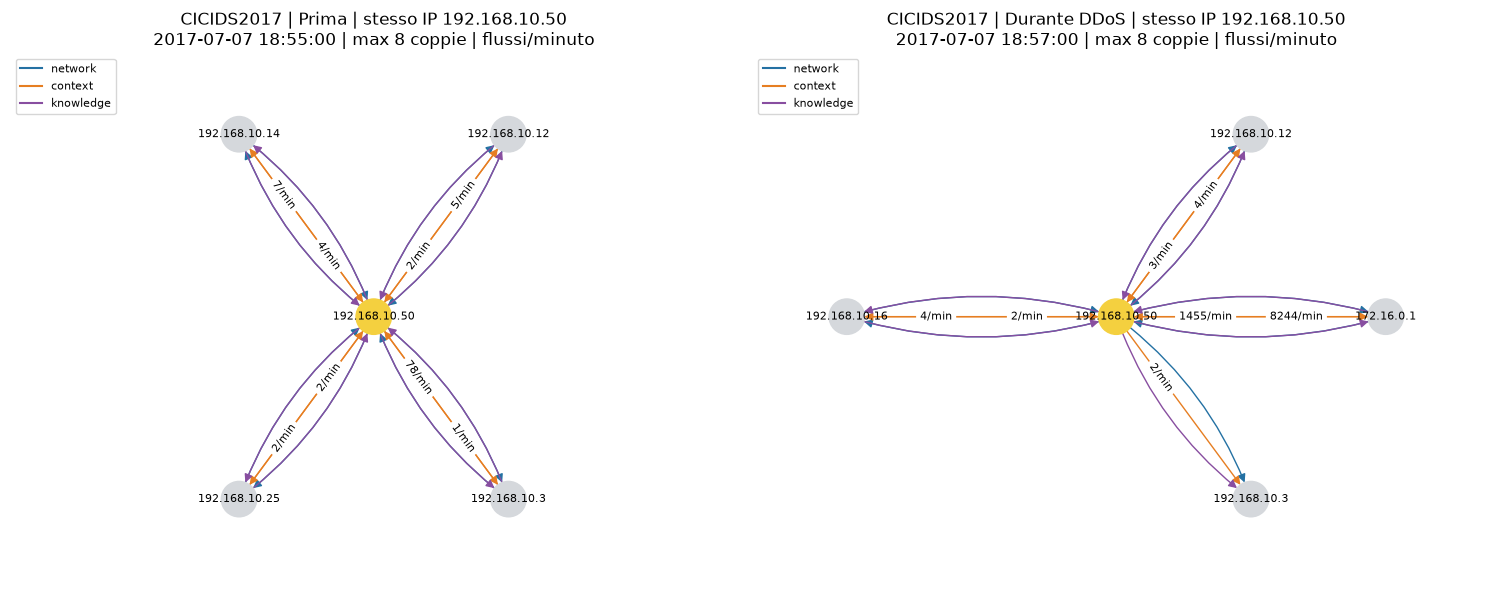

CICToNIoT


,flow,percentuale (%)
attack_type,,
BENIGN,2515236,47.0
xss,2149308,40.16
password,340208,6.36
injection,277696,5.19
scanning,36205,0.68
backdoor,27145,0.51
ransomware,5098,0.1
mitm,517,0.01
ddos,202,0.0


,scenario,IP osservato,minuto,flow benigni,flow attacco
0,prima,192.168.1.1,2019-04-29 19:45:00,9,0
1,durante attacco,192.168.1.1,2019-04-29 22:22:00,13,100


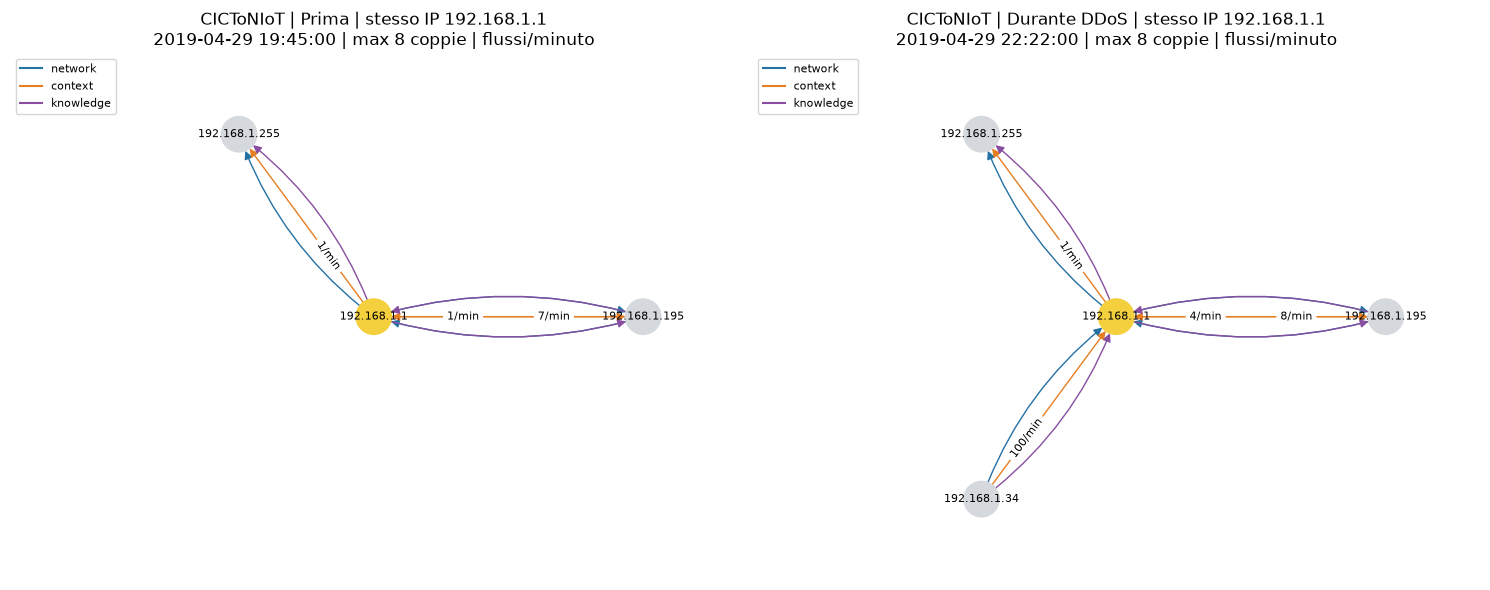

In [2]:
# V2 / 2. DIMENSIONI, CLASSI, FEATURE E STESSO HOST PRIMA/DURANTE L'ATTACCO
display(pd.DataFrame([{"dataset": name, "file": len(DATASETS[name]), "righe lette": frame.attrs["rows_read"],
    "scartate": frame.attrs["rows_read"]-len(frame), "flow validi": len(frame),
    "IP": len(set(frame["Source IP"]) | set(frame["Destination IP"])), "grafi/finestre": frame.window.nunique(),
    "benigni": int((frame.target==0).sum()), "attacchi": int(frame.target.sum()),
    "attacchi (%)": round(100*frame.target.mean(), 2)} for name, frame in datasets.items()]))
feature_summary = pd.DataFrame([
    ["network", "Source Port", "Porta del mittente", "edge_attr", "No"],
    ["network", "Destination Port", "Porta del servizio destinatario", "edge_attr", "No"],
    ["context", "Flow Duration", "Durata della comunicazione", "edge_attr", "No"],
    ["context", "Flow IAT Mean", "Intervallo medio fra pacchetti del flow", "edge_attr", "No"],
    ["knowledge", "Packet Length Std", "Variabilita delle dimensioni dei pacchetti", "edge_attr", "No"],
    ["knowledge", "SYN Flag Count", "Pacchetti con flag TCP SYN", "edge_attr", "No"],
    ["nodi", "community", "ID della comunita topologica locale", "x", "Si"],
    ["nodi", "in_degree", "Flow entranti nell'IP nella finestra", "x", "Si"],
    ["nodi", "out_degree", "Flow uscenti dall'IP nella finestra", "x", "Si"],
], columns=["famiglia", "feature", "significato", "dove si trova", "usata da V1"])
feature_summary["usata dall’ibrido"] = "Si"
display(feature_summary)

def same_host_scenarios(df):
    attacks = df[df["target"] == 1]
    ddos = attacks[attacks["attack_type"].str.contains("ddos", case=False, na=False)]
    if not ddos.empty:
        attacks = ddos
    for host in attacks["Destination IP"].value_counts().index:
        incoming = attacks[attacks["Destination IP"] == host]
        first_attack = incoming["window"].min()
        incident = df[(df["Source IP"] == host) | (df["Destination IP"] == host)]
        earlier = incident[incident["window"] < first_attack]
        benign_windows = earlier.groupby("window")["target"].sum()
        benign_windows = benign_windows[benign_windows == 0]
        if not benign_windows.empty:
            before = incident[incident["window"] == benign_windows.index.max()]
            peak = incoming.groupby("window").size().idxmax()
            during = incident[incident["window"] == peak]
            return host, before, during
    return None


for dataset_name, df in datasets.items():
    print(dataset_name)
    counts = df["attack_type"].value_counts().rename("flow").to_frame()
    counts["percentuale (%)"] = (100*counts["flow"]/len(df)).round(2)
    display(counts)
    scenario = same_host_scenarios(df)
    if scenario is None:
        print("Nessun host con traffico benigno precedente e attacco successivo nei dati selezionati.")
    else:
        host, before, during = scenario
        scenario_summary = pd.DataFrame([
            {"scenario": name, "IP osservato": host, "minuto": part["window"].iloc[0],
             "flow benigni": int((part["target"] == 0).sum()), "flow attacco": int(part["target"].sum())}
            for name, part in [("prima", before), ("durante attacco", during)]
        ])
        display(scenario_summary)
        shown_pairs = []
        for part in [before, during]:
            pairs = part.groupby(["Source IP", "Destination IP"]).size().sort_values(ascending=False)
            shown_pairs.append(pairs.head(MAX_GRAPH_PAIRS))
        union = nx.DiGraph()
        for pairs in shown_pairs:
            union.add_edges_from(pairs.index)
        peers = sorted(set(union.nodes) - {host})
        positions = {host: (0, 0)}
        positions.update({peer: (np.cos(2*np.pi*i/len(peers)), np.sin(2*np.pi*i/len(peers)))
                          for i, peer in enumerate(peers)})
        fig, axes = plt.subplots(1, 2, figsize=(15, 6))
        relation_colors = ["#2471a3", "#e67e22", "#884ea0"]
        for ax, title, part, pairs in zip(axes, ["Prima", "Durante DDoS" if during["attack_type"].str.contains("ddos", case=False, na=False).any() else "Durante attacco"], [before, during], shown_pairs):
            graph = nx.DiGraph()
            graph.add_edges_from(pairs.index)
            nx.draw_networkx_nodes(graph, positions, ax=ax, node_size=650,
                node_color=["#f4d03f" if node == host else "#d5d8dc" for node in graph.nodes])
            nx.draw_networkx_labels(graph, positions, ax=ax, font_size=8)
            for color, radius in zip(relation_colors, [-0.15, 0, 0.15]):
                nx.draw_networkx_edges(graph, positions, ax=ax, node_size=650, edge_color=color,
                    arrowsize=12, connectionstyle=f"arc3,rad={radius}")
            labels = {(u, v): f"{int(count)}/{WINDOW_MINUTES}min" for (u, v), count in pairs.items()}
            nx.draw_networkx_edge_labels(graph, positions, ax=ax, edge_labels=labels, font_size=8, label_pos=0.32)
            ax.legend(handles=[Line2D([0], [0], color=color, label=name)
                               for name, color in zip(SEMANTICS, relation_colors)], loc="upper left", fontsize=8)
            ax.set_title(f"{dataset_name} | {title} | stesso IP {host}\n{part['window'].iloc[0]} | max {MAX_GRAPH_PAIRS} coppie | flow/{WINDOW_MINUTES}min")
            ax.set(xlim=(-1.35, 1.35), ylim=(-1.25, 1.25))
            ax.axis("off")
        plt.tight_layout()
        plt.show()


In [3]:

# V2 / 3. IBRIDO DGM-HGNN, GRID E V1 CON SETTING FISSO
class MLP(nn.Module):
    def __init__(self, dims):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dims[0], dims[1]), nn.ReLU(), nn.Linear(dims[1], dims[2]))

    def forward(self, x):
        return self.net(x)

class DynamicGraphModule(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=16, k=5):
        super().__init__()
        self.embed = MLP([2*input_dim, hidden_dim, latent_dim])
        if k < 1:
            raise ValueError("dgm_k deve essere positivo")
        self.k = int(k)

    @staticmethod
    def aggregate_initial_neighbors(x, edge_index):
        src, dst = edge_index
        out, degree = torch.zeros_like(x), x.new_zeros(x.size(0))
        out.index_add_(0, src, x[dst])
        degree.index_add_(0, src, x.new_ones(src.numel()))
        return out / degree.clamp_min(1).unsqueeze(-1)

    def forward(self, x, initial_edge_index, batch=None):
        context = self.aggregate_initial_neighbors(x, initial_edge_index)
        z = self.embed(torch.cat([x, context], dim=-1))
        if batch is None:
            batch = torch.zeros(x.size(0), dtype=torch.long, device=x.device)
        links = []
        # Il top-k e discreto; il gradiente attraversa z usato nelle GCN successive.
        with torch.no_grad():
            for graph_id in batch.unique():
                nodes = torch.where(batch == graph_id)[0]
                count, k = len(nodes), min(self.k, len(nodes)-1)
                if k < 1:
                    continue
                latent = z[nodes].detach()
                for start in range(0, count, DGM_DISTANCE_CHUNK_SIZE):
                    stop = min(start+DGM_DISTANCE_CHUNK_SIZE, count)
                    distance = torch.cdist(latent[start:stop], latent, p=2,
                                           compute_mode="donot_use_mm_for_euclid_dist")
                    distance[torch.arange(stop-start, device=x.device),
                             torch.arange(start, stop, device=x.device)] = float("inf")
                    neighbors = distance.topk(k, dim=1, largest=False).indices
                    src = nodes[start:stop, None].expand_as(neighbors).reshape(-1)
                    links.append(torch.stack([src, nodes[neighbors.reshape(-1)]]))
        edges = torch.cat(links, dim=1) if links else torch.empty((2,0), dtype=torch.long, device=x.device)
        return z, edges

def safe_batch_norm(layer, x):
    if layer.training and len(x) == 1:
        return F.batch_norm(x, layer.running_mean, layer.running_var, layer.weight, layer.bias, training=False)
    return layer(x)

class HybridHeteroClassifier(nn.Module):
    def __init__(self, hidden_channels=64, out_channels=32, dropout=0.2, dgm_k=5, latent_dim=16):
        super().__init__()
        self.pre_conv = HeteroConv({r: GATv2Conv(3, hidden_channels, edge_dim=2, add_self_loops=False)
                                   for r in RELATIONS}, aggr="sum")
        self.pre_bn = nn.BatchNorm1d(hidden_channels)
        self.dgm = DynamicGraphModule(hidden_channels, hidden_channels, latent_dim, dgm_k)
        self.post_conv1 = GCNConv(latent_dim, hidden_channels)
        self.post_bn1 = nn.BatchNorm1d(hidden_channels)
        self.post_conv2 = GCNConv(hidden_channels, hidden_channels)
        self.post_bn2 = nn.BatchNorm1d(hidden_channels)
        self.lin_node = nn.Sequential(nn.Linear(hidden_channels, 2*hidden_channels), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(2*hidden_channels, out_channels), nn.ReLU())
        self.lin_edge = nn.Sequential(nn.Linear(2*out_channels, out_channels), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(out_channels, out_channels), nn.ReLU(), nn.Dropout(dropout), nn.Linear(out_channels, 2))

    def latent_graph(self, data):
        x = self.pre_conv(data.x_dict, data.edge_index_dict, edge_attr_dict=data.edge_attr_dict)["ip"]
        x = F.relu(safe_batch_norm(self.pre_bn, x))
        # Le tre adiacenze iniziali sono copie: una sola ha la stessa media dei vicini.
        return self.dgm(x, data[RELATIONS[0]].edge_index, data["ip"].get("batch", None))

    def forward(self, data):
        z, edges = self.latent_graph(data)
        z = F.relu(safe_batch_norm(self.post_bn1, self.post_conv1(z, edges)))
        z = F.relu(safe_batch_norm(self.post_bn2, self.post_conv2(z, edges)))
        return {"ip": self.lin_node(z)}

    def edge_classify(self, z_src, z_dst):
        return self.lin_edge(torch.cat([z_src, z_dst], dim=-1))

def node_values(graph):
    x = graph["ip"].x.clone()
    x[:, 1:] = torch.log1p(x[:, 1:].clamp_min(0))
    return x

def edge_values(graph, relation):
    x = graph[relation].edge_attr
    return x.sign()*torch.log1p(x.abs())

def fit_normalization(train_graphs):
    values = {"nodes": torch.cat([node_values(g) for g in train_graphs])}
    values.update({r[1]: torch.cat([edge_values(g, r) for g in train_graphs]) for r in RELATIONS})
    stats = {}
    for name, value in values.items():
        scaler = StandardScaler().fit(value.numpy())
        stats[name] = {"mean": torch.tensor(scaler.mean_, dtype=torch.float32),
                       "scale": torch.tensor(scaler.scale_, dtype=torch.float32)}
    return stats

def normalize_graph(graph, stats):
    graph["ip"].x = (node_values(graph)-stats["nodes"]["mean"])/stats["nodes"]["scale"]
    for r in RELATIONS:
        graph[r].edge_attr = (edge_values(graph,r)-stats[r[1]]["mean"])/stats[r[1]]["scale"]
    return graph

def new_model(params):
    common = {k: params[k] for k in ["hidden_channels", "out_channels", "dropout"]}
    if params["architecture"] == "hybrid":
        return HybridHeteroClassifier(**common, dgm_k=params["dgm_k"], latent_dim=params["latent_dim"])
    if params["architecture"] == "v1":
        return HeteroEdgeClassifier(**common)
    raise ValueError("Architettura sconosciuta")

def choose_model_threshold(items):
    observed = choose_threshold(items)
    below = items.loc[items.score < observed, "score"]
    lower = float(below.max()) if not below.empty else 0.
    threshold = (lower+observed)/2
    assert np.array_equal(items.score.astype("float64") >= threshold, items.score.astype("float64") >= observed)
    return float(threshold)


class HeteroEdgeClassifier(nn.Module):
    def __init__(self, hidden_channels=64, out_channels=32, num_classes=2, dropout=0.2):
        super().__init__()

        self.conv1 = HeteroConv({
            ('ip', 'network', 'ip'): GCNConv(-1, hidden_channels),
            ('ip', 'context', 'ip'): GCNConv(-1, hidden_channels),
            ('ip', 'knowledge', 'ip'): GCNConv(-1, hidden_channels),
            #selected fetures
        }, aggr='sum')

        self.bn1_ip = nn.BatchNorm1d(hidden_channels)

        self.conv2 = HeteroConv({
            ('ip', 'network', 'ip'): GCNConv(hidden_channels, hidden_channels),
            ('ip', 'context', 'ip'): GCNConv(hidden_channels, hidden_channels),
            ('ip', 'knowledge', 'ip'): GCNConv(hidden_channels, hidden_channels),
            #selected fetures
        }, aggr='sum')

        self.bn2_ip = nn.BatchNorm1d(hidden_channels)

        self.lin_node = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels * 2),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_channels * 2, out_channels),
            nn.ReLU()
        )

        self.lin_edge = nn.Sequential(
            nn.Linear(out_channels * 2, out_channels),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(out_channels, out_channels),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(out_channels, num_classes)
        )

    def forward(self, data):
        x_dict = self.conv1(data.x_dict, data.edge_index_dict)
        x_dict['ip'] = (self.bn1_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn1_ip.running_mean, self.bn1_ip.running_var,
                                      self.bn1_ip.weight, self.bn1_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict = self.conv2(x_dict, data.edge_index_dict)
        x_dict['ip'] = (self.bn2_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn2_ip.running_mean, self.bn2_ip.running_var,
                                      self.bn2_ip.weight, self.bn2_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict['ip'] = self.lin_node(x_dict['ip'])
        return x_dict

    def edge_classify(self, z_src, z_dst):
        z_cat = torch.cat([z_src, z_dst], dim=-1)
        logits = self.lin_edge(z_cat)
        return logits

def focal_loss(logits, targets):
    ce = F.cross_entropy(logits, targets, reduction="none")
    return (FOCAL_ALPHA * (1 - torch.exp(-ce)) ** FOCAL_GAMMA * ce).mean()

def graph_loss(model, graph):
    z = model(graph)["ip"]
    return sum(focal_loss(model.edge_classify(z[graph[r].edge_index[0]], z[graph[r].edge_index[1]]),
                          graph[r].edge_label) for r in RELATIONS)

@torch.no_grad()
def predict(model, items, device, batch_size=4):
    model.eval()
    rows = []
    for batch in DataLoader(items, batch_size=batch_size, shuffle=False, num_workers=LOADER_WORKERS):
        batch = batch.to(device)
        z = model(batch)["ip"]
        src, dst = batch[RELATIONS[0]].edge_index
        rows.append(pd.DataFrame({"flow_id": batch.flow_id.cpu().numpy(),
            "target": batch[RELATIONS[0]].edge_label.cpu().numpy(),
            "score": model.edge_classify(z[src], z[dst]).softmax(-1)[:, 1].cpu().numpy()}))
    return pd.concat(rows, ignore_index=True)

def choose_threshold(items):
    if items.target.nunique() != 2:
        raise ValueError("Servono benigni e attacchi per scegliere la soglia F1.")
    if not np.isfinite(items.score).all():
        raise ValueError("Score non finiti.")
    p, r, thresholds = precision_recall_curve(items.target, items.score)
    denominator = p[:-1] + r[:-1]
    f1 = np.divide(2*p[:-1]*r[:-1], denominator, out=np.zeros_like(denominator), where=denominator>0)
    return float(thresholds[np.flatnonzero(f1 == f1.max())[-1]])

def split_graphs(graphs, seed=None):
    if seed is None:
        seed = SPLIT_SEED
    if len(graphs)<3:
        raise ValueError("Servono almeno tre finestre per train, validation e test.")
    rest_size = max(2, int(np.ceil((HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION)*len(graphs))))
    if rest_size>=len(graphs):
        raise ValueError("Le frazioni holdout lasciano troppo pochi grafi nel train")
    indices = np.arange(len(graphs))
    strata = np.array([int(g[RELATIONS[0]].edge_label.max()) for g in graphs])
    classes, counts = np.unique(strata,return_counts=True)
    stratify = strata if min(counts)>=4 and min(rest_size,len(graphs)-rest_size)>=len(classes) else None
    train, rest = train_test_split(indices,test_size=rest_size,random_state=seed,stratify=stratify)
    ratio = HOLDOUT_TEST_FRACTION/(HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION)
    test_size = min(len(rest)-1,max(1,int(np.ceil(ratio*len(rest)))))
    classes, counts = np.unique(strata[rest],return_counts=True)
    stratify = strata[rest] if min(counts)>=2 and min(test_size,len(rest)-test_size)>=len(classes) else None
    val, test = train_test_split(rest,test_size=test_size,random_state=seed,stratify=stratify)
    return [[graphs[i] for i in part] for part in [train,val,test]]

def save_checkpoint(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)

def flow_counts(flows):
    return flows.groupby(["window", "Source IP", "Destination IP"]).size().rename("flow_count").reset_index()

def count_features(flows):
    result = flows[["flow_id", "window", "Source IP", "Destination IP", "target", "attack_type"]].merge(
        flow_counts(flows), on=["window", "Source IP", "Destination IP"], validate="many_to_one")
    result["source_out"] = result.groupby(["window", "Source IP"])["flow_id"].transform("size")
    result["destination_in"] = result.groupby(["window", "Destination IP"])["flow_id"].transform("size")
    return result

def fit_count_thresholds(train_flows):
    counts = flow_counts(train_flows).flow_count
    if counts.empty:
        raise ValueError("Nessuna coppia IP/minuto nel train.")
    return {f"P{q:g}": float(counts.quantile(q/100)) for q in COUNT_PERCENTILES}

def train_model(train_items, val_items, params, checkpoint_path, max_epochs, patience, min_delta, normalization):
    if max_epochs < 1 or (EARLY_STOPPING and (patience < 1 or min_delta < 0 or not np.isfinite(min_delta))):
        raise ValueError("Epoche/patience positive e min_delta non negativo.")
    seed_everything(SEED)
    model = new_model(params).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_items, batch_size=params["batch_size"], shuffle=True,
                              generator=generator, num_workers=LOADER_WORKERS)
    val_loader = DataLoader(val_items, batch_size=params["batch_size"], shuffle=False, num_workers=LOADER_WORKERS)
    history, best_loss, significant_loss, stale = [], float("inf"), float("inf"), 0
    progress = tqdm(range(1, max_epochs+1), desc=Path(checkpoint_path).stem, unit="epoca", position=0, leave=True)
    for epoch in progress:
        model.train()
        train_sum, train_count = 0., 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            loss = graph_loss(model, batch)
            if not torch.isfinite(loss):
                raise RuntimeError("Loss train non finita.")
            loss.backward()
            optimizer.step()
            count = batch[RELATIONS[0]].num_edges
            train_sum += loss.item()*count
            train_count += count
        model.eval()
        val_sum, val_count = 0., 0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(DEVICE)
                count = batch[RELATIONS[0]].num_edges
                val_sum += graph_loss(model, batch).item()*count
                val_count += count
        train_loss, val_loss = train_sum/train_count, val_sum/val_count
        if not np.isfinite(val_loss):
            raise RuntimeError("Loss validation non finita.")
        history.append({"epoca": epoch, "train": train_loss, "validation": val_loss})
        if val_loss < best_loss:
            best_loss = val_loss
            save_checkpoint({"state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "params": params, "normalization": normalization, "best_epoch": epoch, "validation_loss": val_loss, "seed": SEED}, checkpoint_path)
        if EARLY_STOPPING:
            if val_loss < significant_loss - min_delta:
                significant_loss, stale = val_loss, 0
            else:
                stale += 1
        progress.set_postfix(train=f"{train_loss:.5f}", validation=f"{val_loss:.5f}", attesa=stale if EARLY_STOPPING else "off")
        if EARLY_STOPPING and stale >= patience:
            break
    progress.close()
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model.load_state_dict(checkpoint["state_dict"])
    validation = predict(model, val_items, DEVICE, params["batch_size"])
    threshold = choose_model_threshold(validation)
    vp, vr, vf1, _ = precision_recall_fscore_support(validation.target, validation.score.astype("float64")>=threshold,
                                                   average="binary", zero_division=0)
    checkpoint.update({"threshold": threshold, "history": history,
        "validation_F1": float(vf1), "validation_AP": float(average_precision_score(validation.target, validation.score)),
        "epochs_run": len(history), "stopped_early": len(history)<max_epochs, "early_stopping": EARLY_STOPPING,
        "focal_alpha": FOCAL_ALPHA, "focal_gamma": FOCAL_GAMMA})
    save_checkpoint(checkpoint, checkpoint_path)
    return checkpoint


# Verifica anche GAT, kNN e backward sul backend selezionato.
probe_model = None
try:
    probe = HeteroData()
    probe["ip"].x = torch.ones(3,3,device=DEVICE)
    for r in RELATIONS:
        probe[r].edge_index = torch.tensor([[0,1,2,0],[1,2,0,2]], device=DEVICE)
        probe[r].edge_attr = torch.ones(4,2,device=DEVICE)
        probe[r].edge_label = torch.tensor([0,1,0,1],device=DEVICE)
    probe_model = HybridHeteroClassifier(hidden_channels=8, out_channels=4).to(DEVICE)
    probe_loss = graph_loss(probe_model, probe)
    probe_loss.backward()
    if not torch.isfinite(probe_loss):
        raise RuntimeError("Loss di prova ibrido non finita")
except (RuntimeError, NotImplementedError) as error:
    if DEVICE.type == "cpu":
        raise
    print("Backend non compatibile con l'ibrido, uso CPU:", error)
    DEVICE, DEVICE_NAME = torch.device("cpu"), "CPU (fallback operazioni ibrido)"
finally:
    del probe, probe_model


def evaluation_splits(graphs, dataset_name):
    count = N_FOLDS.get(dataset_name, 1)
    if isinstance(count, bool) or not isinstance(count, int) or not 1 <= count <= len(graphs):
        raise ValueError(f"{dataset_name}: N_FOLDS deve essere 1 oppure un intero da 2 a {len(graphs)}")
    if len({g.window for g in graphs}) != len(graphs):
        raise ValueError("Ogni minuto deve corrispondere a un solo grafo prima dei fold")
    selected = FOLDS_TO_RUN.get(dataset_name)
    if selected is not None:
        if (not isinstance(selected, (list,tuple)) or not selected
            or any(isinstance(f,bool) or not isinstance(f,int) or not 1 <= f <= count for f in selected)
            or len(set(selected)) != len(selected)):
            raise ValueError(f"{dataset_name}: FOLDS_TO_RUN deve essere None o una lista senza duplicati fra 1 e {count}")
    if count == 1:
        return [(1, *split_graphs(graphs, SPLIT_SEED))]
    strata = np.array([int(g[RELATIONS[0]].edge_label.max()) for g in graphs])
    counts = np.unique(strata, return_counts=True)[1]
    splitter = (StratifiedKFold(count, shuffle=True, random_state=SPLIT_SEED) if min(counts) >= count
                else KFold(count, shuffle=True, random_state=SPLIT_SEED))
    folds = []
    for fold, (remaining, test) in enumerate(splitter.split(np.arange(len(graphs)), strata), 1):
        if selected is not None and fold not in selected:
            continue
        if len(remaining) < 3:
            raise ValueError("Troppi pochi grafi per separare train e validation dentro ogni fold")
        labels = strata[remaining]
        classes, frequencies = np.unique(labels, return_counts=True)
        val_size = int(np.ceil(KFOLD_VAL_FRACTION*len(remaining)))
        stratify = labels if min(frequencies)>=2 and val_size>=len(classes) and len(remaining)-val_size>=len(classes) else None
        train, val = train_test_split(remaining, test_size=KFOLD_VAL_FRACTION, random_state=SPLIT_SEED, stratify=stratify)
        parts = [[graphs[i] for i in indices] for indices in [train,val,test]]
        for name, part in zip(["train","validation","test"],parts):
            labels = {int(y) for g in part for y in g[RELATIONS[0]].edge_label.unique().tolist()}
            if labels != {0,1}:
                raise ValueError(f"{dataset_name}, fold {fold}: {name} non contiene entrambe le classi; ridurre i fold o cambiare split")
        folds.append((fold,*parts))
    tested = [g.window for _,_,_,test in folds for g in test]
    assert len(tested) == len(set(tested)), "Finestre ripetute nei test esterni"
    if selected is None:
        assert set(tested) == {g.window for g in graphs}, "K-fold incompleta"
    return folds

experiments = {}
for dataset_name, df in datasets.items():
    graphs = [build_graph(part) for _,part in tqdm(df.groupby("window",sort=True), desc=f"Grafi {dataset_name}")]
    assert sum(g[RELATIONS[0]].num_edges for g in graphs) == len(df)
    n_folds = N_FOLDS.get(dataset_name,1)
    if not GRID_SEARCH and dataset_name not in MODEL_PARAMS:
        raise ValueError(f"Mancano MODEL_PARAMS per {dataset_name}")
    fold_splits = evaluation_splits(graphs,dataset_name)
    for fold, train_graphs, val_graphs, test_graphs in fold_splits:
        folder = RUN_DIR/dataset_name
        if n_folds>1:
            folder = folder/f"fold_{fold:02d}"
        folder.mkdir(parents=True,exist_ok=True)
        experiment_key = dataset_name if n_folds==1 else f"{dataset_name}/fold_{fold:02d}"
        print(f"{dataset_name} | fold {fold}/{n_folds}",flush=True)
        train_graphs = [g.clone() for g in train_graphs]
        val_graphs = [g.clone() for g in val_graphs]
        test_graphs = [g.clone() for g in test_graphs]
        parts = [train_graphs,val_graphs,test_graphs]
        windows = [{g.window for g in part} for part in parts]
        ids = [{int(i) for g in part for i in g.flow_id.tolist()} for part in parts]
        assert all(windows[i].isdisjoint(windows[j]) and ids[i].isdisjoint(ids[j]) for i in range(3) for j in range(i))
        assert all(len({int(y) for g in part for y in g[RELATIONS[0]].edge_label.unique().tolist()})==2 for part in parts)
        split_table = pd.DataFrame([{"split":name,"grafi":len(part),"flow":len(flow_ids),
            "attacchi":sum(int(g[RELATIONS[0]].edge_label.sum()) for g in part)}
            for name,part,flow_ids in zip(["train","validation","test"],parts,ids)])
        print(dataset_name,"| 0 finestre e 0 flow_id condivisi; stessi split per tutti i modelli")
        display(split_table)
        split_table.to_csv(folder/"split_summary.csv",index=False)
        pd.DataFrame([{"flow_id":i,"split":name} for name,flow_ids in zip(["train","validation","test"],ids)
                      for i in sorted(flow_ids)]).to_csv(folder/"split_flows.csv",index=False)
        normalization = fit_normalization(train_graphs)
        torch.save(normalization, folder/"normalization.pt")
        for graph in train_graphs+val_graphs+test_graphs:
            normalize_graph(graph, normalization)
        print(f"Max IP/grafo: {max(g['ip'].num_nodes for g in graphs)}; normalizzazione fit solo sul train")
        grid_rows, champion = [], None
        grid = (list(ParameterGrid(PARAM_GRID)) if GRID_SEARCH else [MODEL_PARAMS[dataset_name]])
        for trial, params in enumerate(grid,1):
            print(f"{dataset_name} | ibrido {trial}/{len(grid)} | {params}",flush=True)
            start = time.perf_counter()
            checkpoint = train_model(train_graphs,val_graphs,params,folder/"checkpoints"/f"trial_{trial:03d}.pt",
                                     MAX_EPOCHS,PATIENCE,MIN_DELTA,normalization)
            row = {"trial":trial,**params,**{k:checkpoint[k] for k in ["best_epoch","epochs_run","stopped_early",
                   "validation_loss","validation_F1","validation_AP","threshold"]},"seconds":time.perf_counter()-start}
            grid_rows.append(row)
            pd.DataFrame(grid_rows).to_csv(folder/"grid_search.csv",index=False)
            rank = (checkpoint["validation_F1"],checkpoint["validation_AP"],-checkpoint["validation_loss"])
            if champion is None or rank > (champion["validation_F1"],champion["validation_AP"],-champion["validation_loss"]):
                champion = checkpoint
                save_checkpoint(checkpoint, folder/"best_model.pt")
            print(f"F1 validation {100*checkpoint['validation_F1']:.2f}% | checkpoint epoca {checkpoint['best_epoch']}")
        print(dataset_name,"| HeteroGCN V1: un solo setting",BASELINE_PARAMS,flush=True)
        baseline = train_model(train_graphs,val_graphs,BASELINE_PARAMS,folder/"baseline_v1.pt",
                               MAX_EPOCHS,PATIENCE,MIN_DELTA,normalization)
        display(pd.DataFrame(grid_rows).sort_values(["validation_F1","validation_AP","validation_loss"],
                                                   ascending=[False,False,True]).head(5))
        print("Ibrido scelto:",champion["params"],"| soglia validation:",champion["threshold"])
        experiments[experiment_key] = {"dataset":dataset_name,"fold":fold,"n_folds":n_folds,"folder":folder,"best":champion,"baseline":baseline,"test_graphs":test_graphs,
            "train_ids": np.fromiter(ids[0], dtype=np.int64),"val_ids": np.fromiter(ids[1], dtype=np.int64),"test_ids": np.fromiter(ids[2], dtype=np.int64),"grid_rows":grid_rows}
        del train_graphs,val_graphs,parts,graph,checkpoint
        gc.collect()
    del graphs,fold_splits
    gc.collect()


Grafi CICIDS2017: 100%|██████████| 2454/2454 [00:27<00:00, 90.36it/s] 


CICIDS2017 | 0 finestre e 0 flow_id condivisi; stessi split per tutti i modelli


,split,grafi,flow,attacchi
0,train,1717,2008166,407753
1,validation,368,450896,108516
2,test,369,371681,41377


Max IP/grafo: 457; normalizzazione fit solo sul train
CICIDS2017 | ibrido 1/16 | {'architecture': 'hybrid', 'batch_size': 4, 'dgm_k': 3, 'dropout': 0.2, 'hidden_channels': 32, 'latent_dim': 16, 'lr': 0.001, 'out_channels': 32, 'weight_decay': 0.0001}


trial_001:  43%|████▎     | 43/100 [07:26<09:51, 10.38s/epoca, attesa=10, train=0.00602, validation=0.00390]


...

trial_016:  12%|█▏        | 12/100 [09:02<1:06:16, 45.19s/epoca, attesa=10, train=0.02333, validation=0.03969]


F1 validation 97.82% | checkpoint epoca 3
CICToNIoT | HeteroGCN V1: un solo setting {'architecture': 'v1', 'hidden_channels': 64, 'out_channels': 32, 'dropout': 0.2, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 4}


baseline_v1:  21%|██        | 21/100 [08:15<31:03, 23.59s/epoca, attesa=10, train=0.03273, validation=0.12359]


,trial,architecture,batch_size,dgm_k,dropout,hidden_channels,latent_dim,lr,out_channels,weight_decay,best_epoch,epochs_run,stopped_early,validation_loss,validation_F1,validation_AP,threshold,seconds
6,7,hybrid,4,3,0.2,64,16,0.0003,32,0.0001,10,20,True,0.012335,0.991950,0.993955,0.508522,838.949193
4,5,hybrid,4,3,0.2,64,16,0.0010,32,0.0001,19,29,True,0.009965,0.991802,0.989515,0.408324,1210.569884
7,8,hybrid,4,3,0.2,64,16,0.0003,32,0.0010,46,56,True,0.010251,0.990933,0.994058,0.532316,2340.783995
1,2,hybrid,4,3,0.2,32,16,0.0010,32,0.0010,14,24,True,0.011700,0.989908,0.991931,0.446501,1026.865869
3,4,hybrid,4,3,0.2,32,16,0.0003,32,0.0010,35,45,True,0.012209,0.989449,0.989004,0.551893,1865.657746


Ibrido scelto: {'architecture': 'hybrid', 'batch_size': 4, 'dgm_k': 3, 'dropout': 0.2, 'hidden_channels': 64, 'latent_dim': 16, 'lr': 0.0003, 'out_channels': 32, 'weight_decay': 0.0001} | soglia validation: 0.5085217952728271


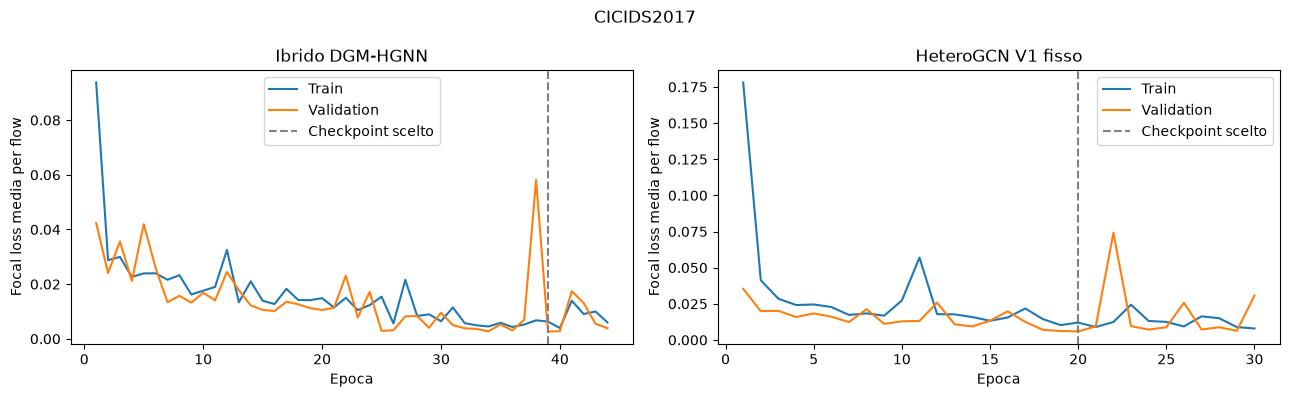

CICIDS2017 | percentili train: {'P90': 5.0, 'P95': 9.0, 'P99': 62.0} | soglia F1 train: 2048.0
Albero appreso sul train:
|--- source_out <= 3955.00
|   |--- class: 0
|--- source_out >  3955.00
|   |--- class: 1

Accuracy sempre benigno: 88.87%
CICIDS2017 | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Ibrido DGM-HGNN,96.15,97.10,95.22,99.15,99.01,99.82,97.43,0.96,1178,1979
HeteroGCN V1 fisso,93.23,99.83,87.46,98.59,98.32,99.67,93.72,0.93,63,5189
Dummy P90,27.30,15.82,99.69,40.90,90.37,96.13,66.62,0.23,219518,127
Dummy P95,29.73,17.48,99.28,47.75,90.37,96.13,70.29,0.26,193923,297
Dummy P99,36.65,22.55,97.77,62.37,90.37,96.13,77.85,0.35,138946,924
Dummy soglia train,89.71,100.00,81.34,97.92,90.37,96.13,90.67,0.89,0,7719
Albero profondita 1,81.41,88.39,75.45,96.16,69.43,87.11,87.11,0.80,4100,10156


Controllo per coppia IP/minuto: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Ibrido DGM-HGNN,74430,161,26.15,21.12,65,127
HeteroGCN V1 fisso,74430,161,12.50,7.45,19,149
Dummy P90,74430,161,1.99,45.96,7203,87
Dummy P95,74430,161,2.67,30.43,3455,112
Dummy P99,74430,161,7.07,19.88,712,129
Dummy soglia train,74430,161,6.02,3.11,0,156
Albero profondita 1,74430,161,5.59,3.11,13,156


Famiglie reali: recall attacchi / specificita BENIGN


modello,HeteroGCN V1 fisso,Ibrido DGM-HGNN
attack_type,,
BENIGN,99.98,99.64
Bot,0.00,0.00
DDoS,100.00,100.00
DoS Hulk,100.00,100.00
DoS Slowhttptest,63.45,68.34
DoS slowloris,0.00,100.00
FTP-Patator,0.00,91.73
Heartbleed,0.00,0.00
Infiltration,0.00,0.00


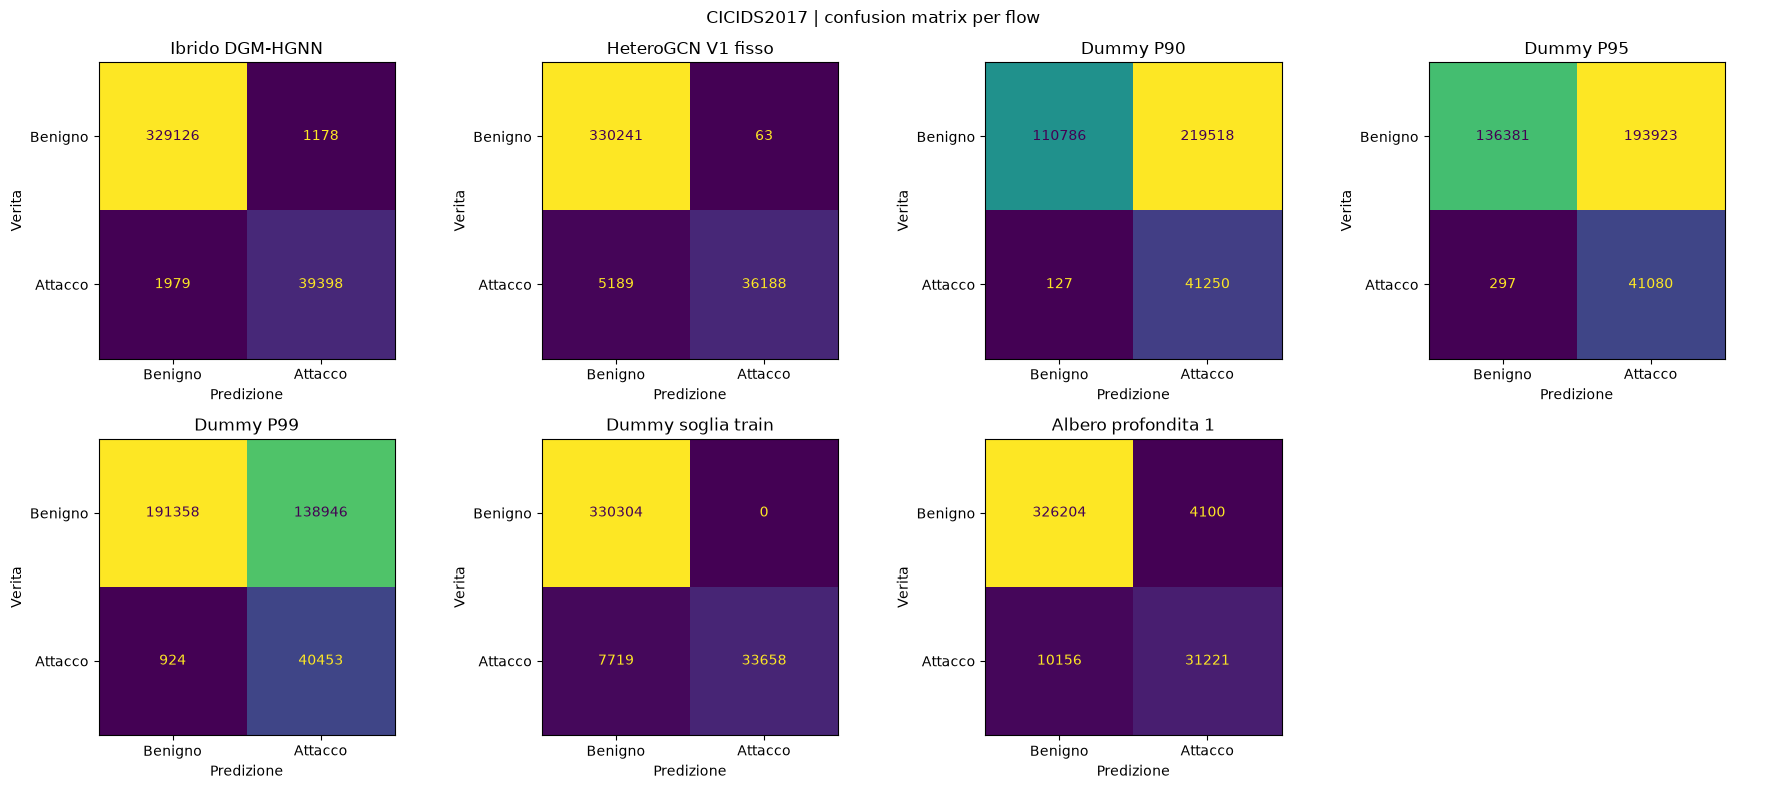

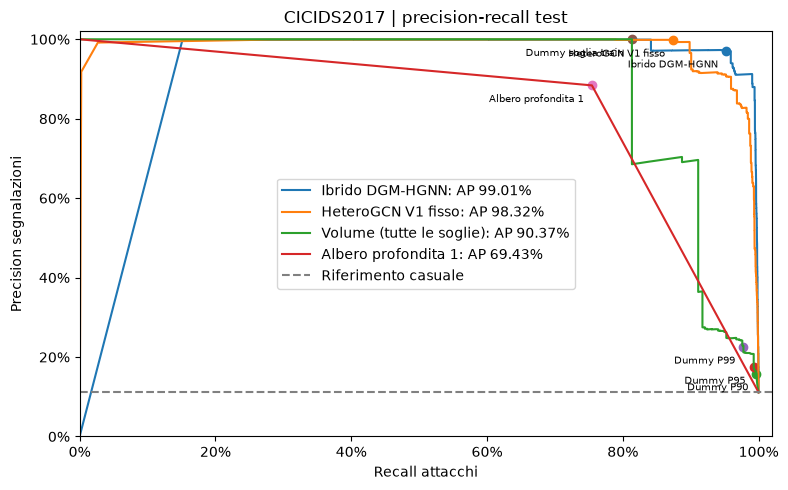

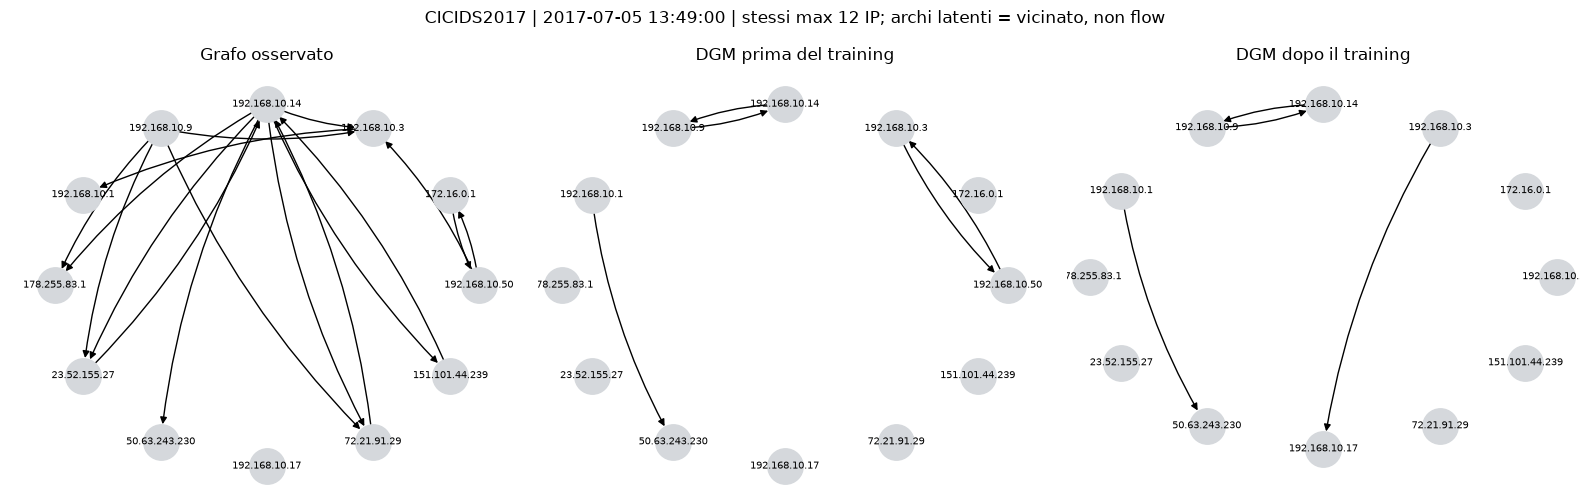

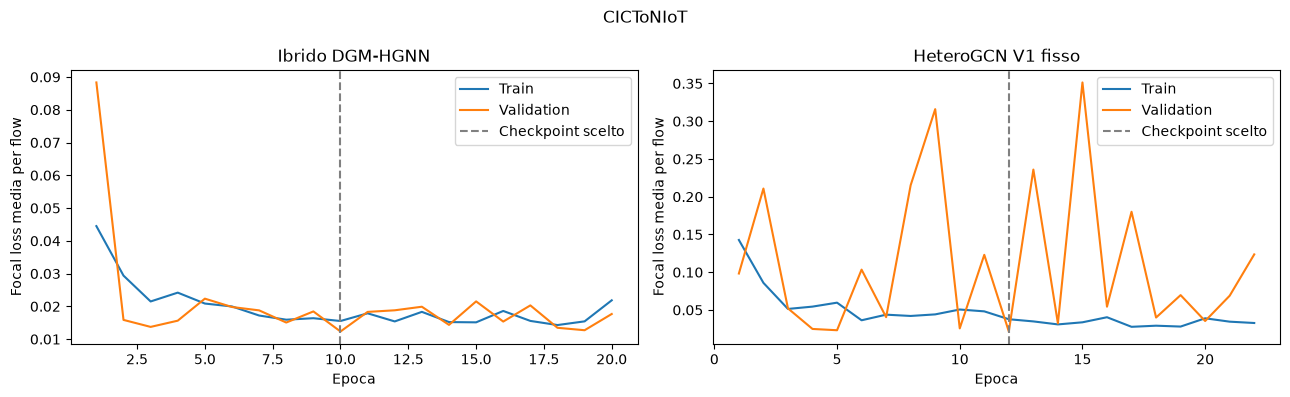

CICToNIoT | percentili train: {'P90': 1.0, 'P95': 2.0, 'P99': 272.0} | soglia F1 train: 54.0
Albero appreso sul train:
|--- source_out <= 1492.50
|   |--- class: 0
|--- source_out >  1492.50
|   |--- class: 1

Accuracy sempre benigno: 47.08%
CICToNIoT | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Ibrido DGM-HGNN,98.51,97.44,99.61,98.41,98.64,99.02,98.33,0.97,11552,1715
HeteroGCN V1 fisso,97.38,95.84,98.98,97.18,98.65,99.01,97.07,0.94,18979,4496
Dummy P90,74.20,59.00,99.96,63.22,64.21,68.34,60.94,0.36,306535,180
Dummy P95,74.36,59.21,99.92,63.53,64.21,68.34,61.27,0.36,303778,349
Dummy P99,73.36,61.22,91.50,64.83,64.21,68.34,63.17,0.32,255808,37491
Dummy soglia train,74.83,60.31,98.58,64.91,64.21,68.34,62.82,0.37,286319,6265
Albero profondita 1,88.27,82.20,95.31,86.60,80.83,86.06,86.06,0.74,91047,20714


Controllo per coppia IP/minuto: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Ibrido DGM-HGNN,91065,1555,72.69,90.87,920,142
HeteroGCN V1 fisso,91065,1555,66.35,71.32,679,446
Dummy P90,91065,1555,43.06,88.42,3457,180
Dummy P95,91065,1555,52.40,82.96,2079,265
Dummy P99,91065,1555,43.58,34.28,358,1022
Dummy soglia train,91065,1555,51.91,47.59,556,815
Albero profondita 1,91065,1555,70.10,59.04,146,637


Famiglie reali: recall attacchi / specificita BENIGN


modello,HeteroGCN V1 fisso,Ibrido DGM-HGNN
attack_type,,
BENIGN,95.17,97.06
backdoor,67.24,97.29
ddos,39.39,21.21
dos,0.00,28.12
injection,99.80,99.72
mitm,41.67,8.80
password,99.15,99.65
ransomware,8.97,43.05
scanning,94.81,99.92


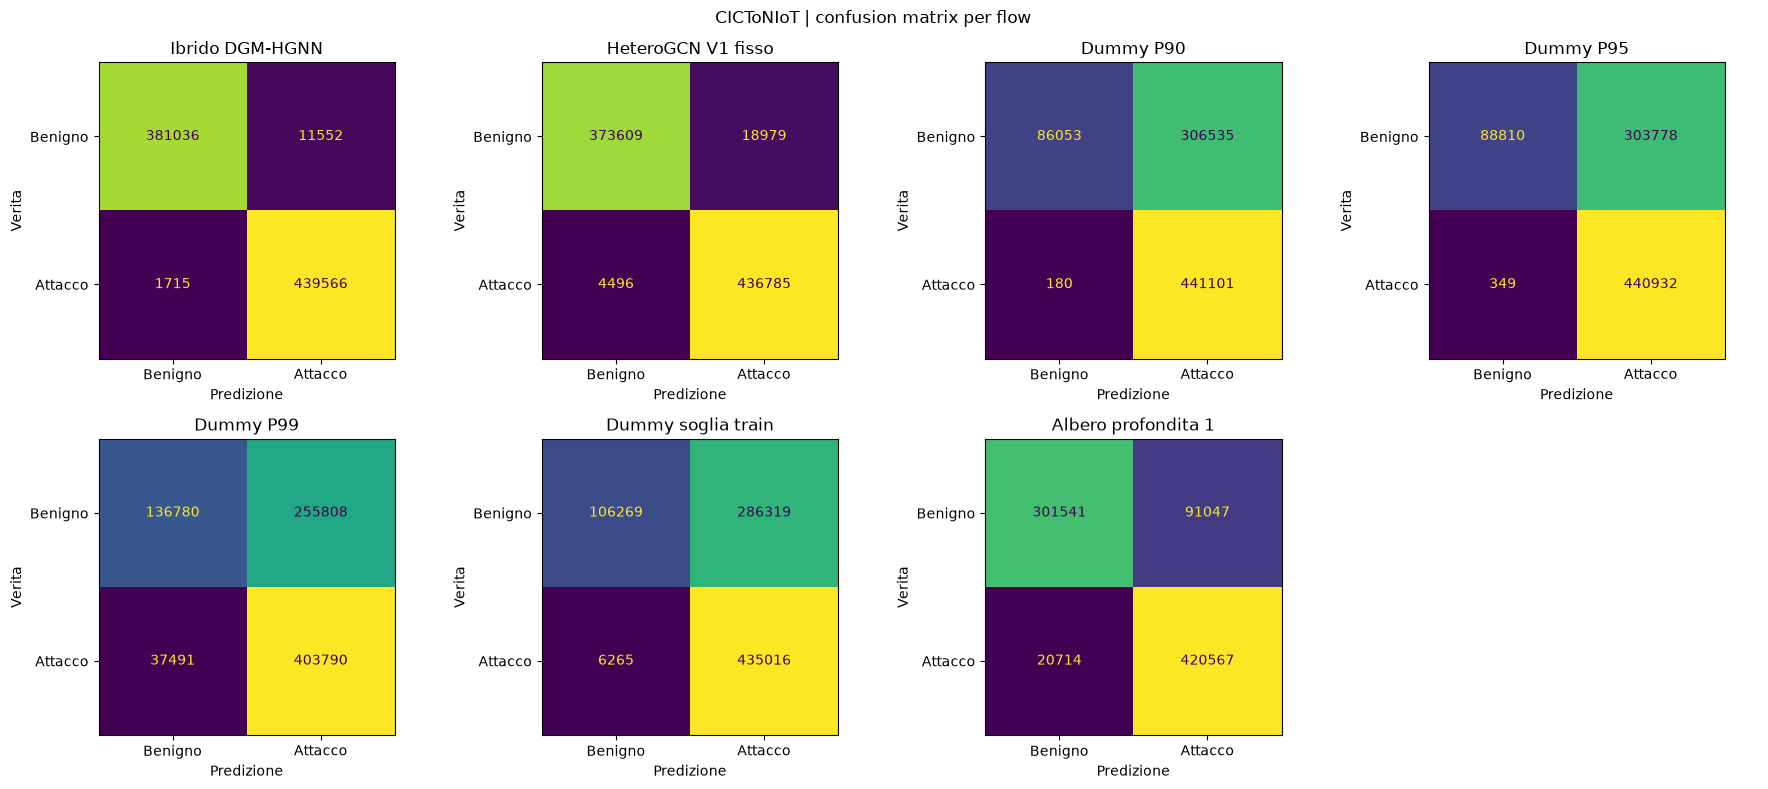

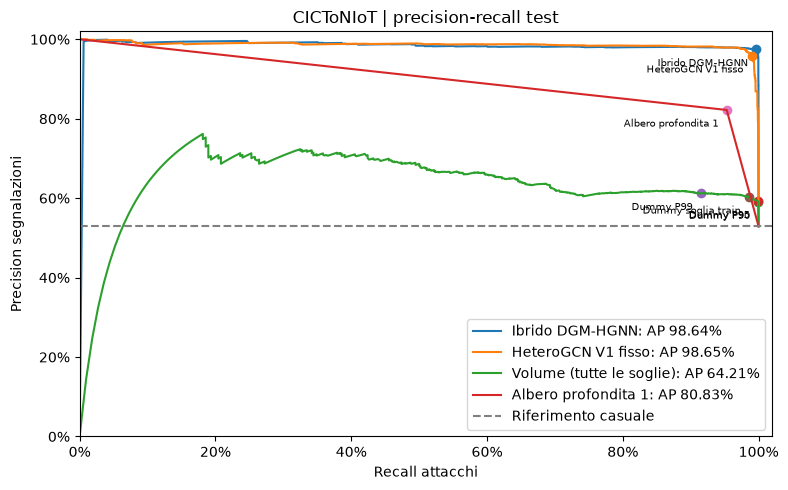

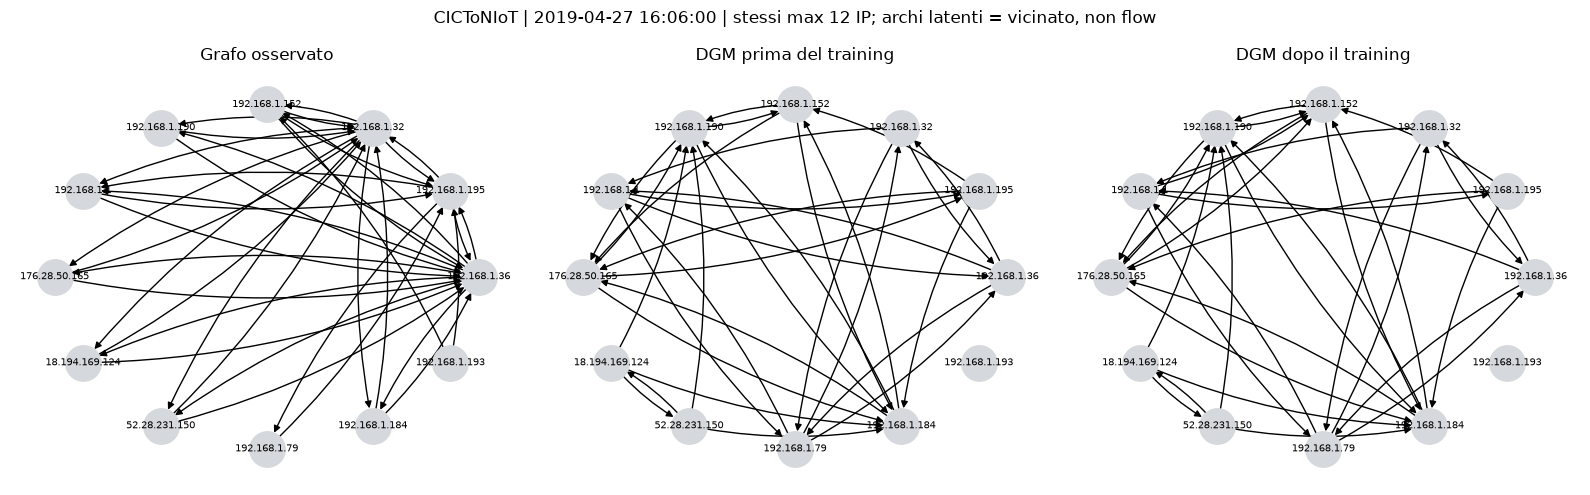

V2 completata. Risultati e checkpoint: data\marco_output_v2\20261025_125112_039856


In [ ]:
# TEST, GRAFO LATENTE E CONFRONTO CON TUTTE LE BASELINE
def evaluation_metrics(target, score, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(target, predicted, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(target, predicted, labels=[0, 1]).ravel()
    both = len(np.unique(target)) == 2
    return {"F1 (%)": 100*f1, "precision (%)": 100*precision, "recall (%)": 100*recall,
        "accuracy (%)": 100*accuracy_score(target, predicted),
        "AP (%)": 100*average_precision_score(target, score) if both else None,
        "ROC-AUC (%)": 100*roc_auc_score(target, score) if both else None,
        "balanced accuracy (%)": 100*balanced_accuracy_score(target, predicted),
        "MCC": float(matthews_corrcoef(target, predicted)),
        "veri negativi": int(tn), "falsi allarmi": int(fp), "attacchi mancati": int(fn), "veri positivi": int(tp),
        "FPR (%)": 100*fp/(fp+tn) if fp+tn else None}

@torch.no_grad()
def plot_latent_comparison(trained, untrained, graph, window_df, folder, dataset_name):
    trained.eval(); untrained.eval()
    _, initial = untrained.latent_graph(graph)
    _, learned = trained.latent_graph(graph)
    mapping = list(dict.fromkeys(value for pair in zip(window_df["Source IP"],window_df["Destination IP"]) for value in pair))
    original = graph[RELATIONS[0]].edge_index.cpu()
    focus = graph["ip"].num_nodes
    selected = torch.bincount(original.flatten(),minlength=focus).topk(min(MAX_LATENT_NODES,focus)).indices.tolist()
    positions = nx.circular_layout(selected)
    fig, axes = plt.subplots(1,3,figsize=(16,5))
    for ax,title,edge_index in zip(axes,["Grafo osservato","DGM prima del training","DGM dopo il training"],
                                 [original,initial.cpu(),learned.cpu()]):
        shown = nx.DiGraph(); shown.add_nodes_from(selected)
        shown.add_edges_from((int(u),int(v)) for u,v in edge_index.t().tolist() if int(u) in selected and int(v) in selected)
        nx.draw_networkx(shown,positions,ax=ax,labels={i:mapping[i] for i in selected},font_size=7,
                         node_size=650,node_color="#d5d8dc",arrowsize=10,connectionstyle="arc3,rad=0.1")
        ax.set_title(title);ax.axis("off")
    fig.suptitle(f"{dataset_name} | {window_df.window.iloc[0]} | stessi max {MAX_LATENT_NODES} IP; archi latenti = vicinato, non flow")
    fig.tight_layout();fig.savefig(folder/"latent_graph.png",dpi=PLOT_DPI);plt.show()


def summarize_folds(comparisons, pair_rows, experiments, datasets, run_dir):
    metrics = ["F1 (%)","precision (%)","recall (%)","accuracy (%)","AP (%)","ROC-AUC (%)",
               "balanced accuracy (%)","MCC","FPR (%)","falsi allarmi","attacchi mancati"]
    for rows, filename in [(comparisons,"summary_test.csv"),(pair_rows,"summary_pairs.csv")]:
        frame = pd.DataFrame(rows)
        grouped = frame.groupby(["dataset","modello"])
        stats = grouped[metrics].agg(["mean","std"])
        stats.columns = [f"{metric} {stat}" for metric,stat in stats.columns]
        stats.insert(0,"fold eseguiti",grouped["fold"].nunique())
        stats.to_csv(run_dir/filename)
        print(filename,"| media e deviazione standard fra i fold; std non stimabile con un solo fold")
        display(stats[["fold eseguiti","F1 (%) mean","F1 (%) std","recall (%) mean","falsi allarmi mean"]].round(2))
    coverage = []
    for name,df in datasets.items():
        runs = [e for e in experiments.values() if e["dataset"]==name]
        tested = [int(i) for e in runs for i in e["test_ids"]]
        assert len(tested)==len(set(tested)), "Flow valutati in piu test esterni"
        configured = runs[0]["n_folds"]
        if configured>1 and len(runs)==configured:
            assert set(tested)==set(df.flow_id), "La k-fold completa deve valutare tutti i flow"
        coverage.append({"dataset":name,"fold configurati":configured,"fold eseguiti":len(runs),
                         "flow test unici":len(tested),"flow dataset":len(df),"copertura (%)":100*len(tested)/len(df)})
    coverage = pd.DataFrame(coverage)
    coverage.to_csv(run_dir/"test_coverage.csv",index=False)
    display(coverage.round(2))

all_comparisons, all_pairs = [], []
for experiment in experiments.values():
    dataset_name = experiment["dataset"]
    fold, n_folds = experiment["fold"], experiment["n_folds"]
    print(f"{dataset_name} | test fold {fold}/{n_folds}")
    folder, df = experiment["folder"], datasets[dataset_name]
    best = torch.load(folder/"best_model.pt",map_location="cpu",weights_only=True)
    baseline = torch.load(folder/"baseline_v1.pt",map_location="cpu",weights_only=True)
    network_predictions = {}
    models = {}
    fig, axes = plt.subplots(1,2,figsize=(13,4))
    for ax,(name,checkpoint) in zip(axes,[("Ibrido DGM-HGNN",best),("HeteroGCN V1 fisso",baseline)]):
        model = new_model(checkpoint["params"]).to(DEVICE)
        model.load_state_dict(checkpoint["state_dict"])
        prediction = predict(model,experiment["test_graphs"],DEVICE,checkpoint["params"]["batch_size"])
        assert prediction.flow_id.is_unique and set(prediction.flow_id)==set(experiment["test_ids"])
        prediction["prediction"] = (prediction.score.astype("float64")>=checkpoint["threshold"]).astype(int)
        network_predictions[name] = prediction.set_index("flow_id")
        models[name] = model
        history = pd.DataFrame(checkpoint["history"]).set_index("epoca")
        ax.plot(history.index,history.train,label="Train")
        ax.plot(history.index,history.validation,label="Validation")
        ax.axvline(checkpoint["best_epoch"],color="gray",linestyle="--",label="Checkpoint scelto")
        ax.set(title=name,xlabel="Epoca",ylabel="Focal loss media per flow");ax.legend()
    fig.suptitle(dataset_name);fig.tight_layout();fig.savefig(folder/"loss.png",dpi=PLOT_DPI);plt.show()
    predictions = network_predictions["Ibrido DGM-HGNN"].reset_index().merge(
        df[["flow_id","window","Source IP","Destination IP","attack_type"]],on="flow_id",validate="one_to_one")
    reference = network_predictions["HeteroGCN V1 fisso"].loc[predictions.flow_id]
    assert np.array_equal(reference.target,predictions.target)
    predictions["v1_score"] = reference.score.to_numpy()
    predictions["v1_prediction"] = reference.prediction.to_numpy()
    train_flows = df[df.flow_id.isin(experiment["train_ids"])]
    test_flows = df[df.flow_id.isin(experiment["test_ids"])]
    train_counts = count_features(train_flows)
    count_predictions = count_features(test_flows).set_index("flow_id").loc[predictions.flow_id].reset_index()
    thresholds = fit_count_thresholds(train_flows)
    count_train_threshold = choose_threshold(train_counts[["target","flow_count"]].rename(columns={"flow_count":"score"}))
    stump = DecisionTreeClassifier(max_depth=TREE_MAX_DEPTH,random_state=SEED).fit(train_counts[STUMP_FEATURES],train_counts.target)
    stump_rule = export_text(stump,feature_names=STUMP_FEATURES,decimals=2)
    print(dataset_name,"| percentili train:",thresholds,"| soglia F1 train:",count_train_threshold)
    print("Albero appreso sul train:\n"+stump_rule)
    print(f"Accuracy sempre benigno: {100*(predictions.target==0).mean():.2f}%")
    specs = [("Ibrido DGM-HGNN",predictions.score.to_numpy(),predictions.prediction.to_numpy(),f"score >= {best['threshold']:.8g}"),
             ("HeteroGCN V1 fisso",predictions.v1_score.to_numpy(),predictions.v1_prediction.to_numpy(),f"score >= {baseline['threshold']:.8g}")]
    for name,threshold in thresholds.items():
        count_predictions[name] = (count_predictions.flow_count>threshold).astype(int)
        specs.append((f"Dummy {name}",count_predictions.flow_count.to_numpy(),count_predictions[name].to_numpy(),f"flow > {threshold:g}"))
    count_predictions["Soglia_train"] = (count_predictions.flow_count>=count_train_threshold).astype(int)
    count_predictions["Albero"] = stump.predict(count_predictions[STUMP_FEATURES])
    specs.extend([("Dummy soglia train",count_predictions.flow_count.to_numpy(),count_predictions.Soglia_train.to_numpy(),f"flow >= {count_train_threshold:g}"),
                  (f"Albero profondita {TREE_MAX_DEPTH}",stump.predict_proba(count_predictions[STUMP_FEATURES])[:,1],count_predictions.Albero.to_numpy(),stump_rule)])
    y = predictions.target.to_numpy()
    comparison_rows,unit_rows,reports,family_rows = [],[],{},[]
    for name,scores,guessed,rule in specs:
        comparison_rows.append({"dataset":dataset_name,"fold":fold,"modello":name,"regola":rule,**evaluation_metrics(y,scores,guessed)})
        pairs = predictions[["window","Source IP","Destination IP","target"]].assign(score=scores,prediction=guessed)
        pairs = pairs.groupby(["window","Source IP","Destination IP"]).agg(
            target=("target","max"),score=("score","max"),prediction=("prediction","max"))
        unit_rows.append({"dataset":dataset_name,"fold":fold,"modello":name,"unita":"coppia IP/finestra","totali":len(pairs),"attacchi reali":int(pairs.target.sum()),
                          **evaluation_metrics(pairs.target,pairs.score,pairs.prediction)})
        reports[name] = classification_report(y,guessed,labels=[0,1],target_names=["BENIGN","ATTACK"],output_dict=True,zero_division=0)
        if name in network_predictions:
            family = predictions.assign(guess=guessed).groupby("attack_type").apply(
                lambda part:pd.Series({"flow":len(part),"corretti (%)":100*(part.target==part.guess).mean()})).reset_index()
            family["modello"] = name; family_rows.extend(family.to_dict("records"))
    comparison = pd.DataFrame(comparison_rows).set_index("modello")
    print(dataset_name,"| test: una decisione per flow")
    display(comparison[["F1 (%)","precision (%)","recall (%)","accuracy (%)","AP (%)","ROC-AUC (%)",
                        "balanced accuracy (%)","MCC","falsi allarmi","attacchi mancati"]].round(2))
    print("Controllo per coppia IP/finestra: target = almeno un flow di attacco")
    display(pd.DataFrame(unit_rows).set_index("modello")[["totali","attacchi reali","F1 (%)","recall (%)","falsi allarmi","attacchi mancati"]].round(2))
    print("Famiglie reali: recall attacchi / specificita BENIGN")
    display(pd.DataFrame(family_rows).pivot(index="attack_type",columns="modello",values="corretti (%)").round(2))
    cols = min(4,len(specs)); rows = int(np.ceil(len(specs)/cols))
    fig,axes = plt.subplots(rows,cols,figsize=(4.5*cols,4*rows),squeeze=False)
    for ax,(name,scores,guessed,rule) in zip(axes.flat,specs):
        ConfusionMatrixDisplay(confusion_matrix(y,guessed,labels=[0,1]),display_labels=["Benigno","Attacco"]).plot(
            ax=ax,colorbar=False,values_format="d")
        ax.set(title=name,xlabel="Predizione",ylabel="Verita")
    for ax in list(axes.flat)[len(specs):]:
        ax.axis("off")
    fig.suptitle(f"{dataset_name} | fold {fold}/{n_folds} | confusion matrix per flow");fig.tight_layout()
    fig.savefig(folder/"confusion_matrices.png",dpi=PLOT_DPI);plt.show()
    fig,ax = plt.subplots(figsize=(8,5))
    for index in [0,1,2,len(specs)-1]:
        name,scores,guessed,_ = specs[index]
        precision,recall,_ = precision_recall_curve(y,scores)
        label = "Volume (tutte le soglie)" if index==2 else name
        ax.plot(recall,precision,label=f"{label}: AP {100*average_precision_score(y,scores):.2f}%")
    for name,scores,guessed,_ in specs:
        precision,recall,_,_ = precision_recall_fscore_support(y,guessed,average="binary",zero_division=0)
        ax.scatter([recall],[precision]);ax.annotate(name,(recall,precision),xytext=(-6,-12),textcoords="offset points",ha="right",fontsize=7)
    ax.axhline(y.mean(),color="gray",linestyle="--",label="Riferimento casuale")
    ax.set(title=f"{dataset_name} | fold {fold}/{n_folds} | precision-recall test",xlabel="Recall attacchi",ylabel="Precision segnalazioni",xlim=(0,1.02),ylim=(0,1.02))
    ax.xaxis.set_major_formatter(PercentFormatter(1));ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend();fig.tight_layout();fig.savefig(folder/"precision_recall.png",dpi=PLOT_DPI);plt.show()
    # Grafo completo in inferenza; si disegnano solo gli IP piu presenti.
    sample = max(experiment["test_graphs"],key=lambda g:int(g[RELATIONS[0]].edge_label.sum()))
    sample_flows = df[df.window==pd.Timestamp(sample.window)]
    seed_everything(SEED)
    untrained = new_model(best["params"]).to(DEVICE).eval()
    plot_latent_comparison(models["Ibrido DGM-HGNN"],untrained,sample.clone().to(DEVICE),sample_flows,folder,dataset_name)
    predictions.to_csv(folder/"predictions.csv",index=False)
    count_predictions.to_csv(folder/"count_baseline_predictions.csv",index=False)
    comparison.to_csv(folder/"comparison_test.csv")
    pd.DataFrame(unit_rows).to_csv(folder/"unit_comparison.csv",index=False)
    pd.DataFrame(family_rows).to_csv(folder/"attack_families.csv",index=False)
    run = {"dataset":dataset_name,"files":[str(p) for p in DATASETS[dataset_name]],"rows":len(df),"windows":int(df.window.nunique()),
        "device":DEVICE_NAME,"cpu_threads":CPU_THREADS,"seed":SEED,"params":best["params"],"baseline_params":baseline["params"],
        "max_epochs":MAX_EPOCHS,"patience":PATIENCE,"min_delta":MIN_DELTA,
        "best_epoch":best["best_epoch"],"epochs_run":best["epochs_run"],"threshold":best["threshold"],
        "baseline_best_epoch":baseline["best_epoch"],"baseline_threshold":baseline["threshold"],
        "selection":"checkpoint min validation loss; hybrid trial max validation F1, AP, then min loss; V1 fixed; model thresholds inside optimal validation score interval",
        "split":"random minute graphs 70/15/15; stratified by attack presence when possible; same for all models",
        "normalization":"shared train-only StandardScaler; log1p node degrees; signed log1p edge attrs; community ID unchanged before scaling",
        "normalization_stats":{k:{field:value.tolist() for field,value in stats.items()} for k,stats in best["normalization"].items()},
        "dgm":"hard kNN within each minute graph; embedding learns via post-GCN; no gradient through neighbor indices; no temperature",
        "test_flows":len(y),"test_attacks":int(y.sum()),"edge_features_used_by_hybrid":True,"edge_features_used_by_v1":False,
        "count_baseline_thresholds":thresholds,"count_train_threshold":count_train_threshold,"stump_rule":stump_rule,
        "loss_history":best["history"],"baseline_loss_history":baseline["history"],
        "comparison":comparison.reset_index().to_dict("records"),"classification_reports":reports,
        "accuracy_always_benign":float((y==0).mean()),"torch":str(torch.__version__),"pyg":str(torch_geometric.__version__)}
    run.update({"fold":fold,"n_folds":n_folds,
        "evaluation":"holdout" if n_folds==1 else "outer graph k-fold with inner validation",
        "grid_search":GRID_SEARCH,
        "cv_scope":"holdout" if n_folds==1 else ("grid selected on inner validation" if GRID_SEARCH else "fixed configuration; not a new cross-validated hyperparameter search"),
        "split":"disjoint minute graphs; shared by all compared models; external fold never used for checkpoint/threshold selection"})
    run.update({"grid_search":GRID_SEARCH,"early_stopping":EARLY_STOPPING,"split_seed":SPLIT_SEED,
        "holdout_test_fraction":HOLDOUT_TEST_FRACTION,"holdout_validation_fraction":HOLDOUT_VAL_FRACTION,
        "kfold_validation_fraction":KFOLD_VAL_FRACTION,"window_minutes":WINDOW_MINUTES,
        "focal_alpha":FOCAL_ALPHA,"focal_gamma":FOCAL_GAMMA,"count_percentiles":COUNT_PERCENTILES,
        "tree_max_depth":TREE_MAX_DEPTH,"loader_workers":LOADER_WORKERS,"gpu_requested":USE_GPU})
    (folder/"run.json").write_text(json.dumps(run,indent=2),encoding="utf-8")
    all_comparisons.extend(comparison_rows)
    all_pairs.extend(unit_rows)
    del models,model,untrained,train_counts,count_predictions
    gc.collect()
pd.DataFrame(all_comparisons).to_csv(RUN_DIR/"comparison_all_datasets.csv",index=False)
print("V2 completata. Risultati e checkpoint:",RUN_DIR)

summarize_folds(all_comparisons,all_pairs,experiments,datasets,RUN_DIR)


## V3 - DGM HGNN full context


In [1]:
# V3 / 1. CONFIGURAZIONE E DATI COMPLETI

from pathlib import Path

from datetime import datetime
import os

# MODIFICA QUESTO BLOCCO come fosse un configuratore: i parametri qui sotto valgono per tutti i dataset selezionati. Per cambiare il comportamento di un dataset specifico, modifica MODEL_PARAMS o PARAM_GRID.;
# Esecuzione: questi interruttori valgono sia in holdout sia in k-fold.
RESUME_RUN = None  # Path della cartella risultati esistente dopo un riavvio; None = nuovo run.
GRID_SEARCH = False
EARLY_STOPPING = True
DOWNLOAD_MISSING_DATA = True  # Primo avvio: ~0.9 GB da Internet, ~4 GB su disco; poi usa la cache.
USE_GPU = True  # GPU NVIDIA/AMD se utilizzabile; False forza la CPU.
CPU_THREADS = max(1, (os.cpu_count() or 1) - 1)
SEED = 123  # Inizializzazione, dropout e ordine dei batch.
SPLIT_SEED = 123  # Cambialo solo per cambiare la suddivisione dei dati.

# Dati: commenta una voce per eseguire solo l'altro dataset.
DATASETS = {
    "CICIDS2017": Path("data/cicids2017"),
    "CICToNIoT": Path("data/cictoniot/CIC-ToN-IoT-graph.parquet"),
}
WINDOW_MINUTES = 1

# Valutazione: 1 = holdout; >= 2 = k-fold di grafi interi.
N_FOLDS = {"CICIDS2017": 5, "CICToNIoT": 5}
FOLDS_TO_RUN = {"CICIDS2017": None, "CICToNIoT": None}  # None = tutti; [1, 3] = soltanto quei fold.
HOLDOUT_TEST_FRACTION = 0.15
HOLDOUT_VAL_FRACTION = 0.15  # Frazione dell'intero dataset.
KFOLD_VAL_FRACTION = 0.15  # Frazione dei grafi rimasti dopo il test esterno.

# Training: con EARLY_STOPPING=False si completano tutte le epoche.
MAX_EPOCHS = 100
PATIENCE = 10
MIN_DELTA = 1e-4

# GRID_SEARCH=False: un solo setting per dataset, anche in holdout.
MODEL_PARAMS = {
    name: {"architecture":"full_context","hidden_channels":64,"out_channels":32,
        "latent_dim":16,"dgm_k":2,"dropout":0.2,"lr":1e-3,"weight_decay":1e-3,"batch_size":4}
    for name in DATASETS
}

# GRID_SEARCH=True: valori da provare sul validation interno.
PARAM_GRID = {
    "architecture": ["full_context"], "hidden_channels": [32, 64], "out_channels": [32],
    "dgm_k": [2, 5], "latent_dim": [16], "dropout": [0.2],
    "lr": [1e-3, 3e-4], "weight_decay": [1e-4, 1e-3], "batch_size": [4],
}

# V1 e V2 di confronto: un solo setting ciascuna, sugli stessi split della V3.
BASELINE_PARAMS = {"architecture": "v1", "hidden_channels": 64, "out_channels": 32,
    "dropout": 0.2, "lr": 1e-3, "weight_decay": 1e-4, "batch_size": 4}

BASELINE_V2_PARAMS = {"architecture":"hybrid","hidden_channels":64,"out_channels":32,
    "latent_dim":16,"dgm_k":3,"dropout":0.2,"lr":1e-3,"weight_decay":1e-4,"batch_size":4}

# Avanzati: possono restare invariati.
CENTRALITY_SAMPLES = None  # None = esatta come la tesista; un intero (es. 256) = stima piu veloce dichiarata nei risultati.
FOCAL_ALPHA = 0.25  # Fattore comune alle classi, non un peso maggiore per gli attacchi.
FOCAL_GAMMA = 2.0
COUNT_PERCENTILES = [90, 95, 99]
TREE_MAX_DEPTH = 1
STUMP_FEATURES = ["source_out", "destination_in"]
LOADER_WORKERS = 0  # In Jupyter su Windows lascia 0; il parallelismo CPU usa CPU_THREADS.
CSV_CHUNK_ROWS = 250_000
MAX_GRAPH_PAIRS = 8
MAX_LATENT_NODES = 12
PLOT_DPI = 140
DGM_DISTANCE_CHUNK_SIZE = 256  # Riduce la memoria delle distanze, senza campionare IP.
OUTPUT_ROOT = Path("data/marco_output_v3")
SEMANTICS = {
    "network": ["Source Port", "Destination Port"],
    "context": ["Flow Duration", "Flow IAT Mean"],
    "knowledge": ["Packet Length Std", "SYN Flag Count"],
}
# FINE CONFIGURAZIONE

if isinstance(CPU_THREADS,bool) or not isinstance(CPU_THREADS,int) or CPU_THREADS<1:
    raise ValueError("CPU_THREADS: serve un intero positivo")
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = str(CPU_THREADS)
import json
import hashlib
import urllib.request
import urllib.parse
import zipfile
import random
import time
import warnings
import gc
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint as gradient_checkpoint
import torch_geometric
from torch_geometric.data import HeteroData
from torch_geometric.loader import DataLoader
from torch_geometric.nn import HeteroConv, GCNConv, GATv2Conv
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid, train_test_split, KFold, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
    confusion_matrix, precision_recall_fscore_support, roc_auc_score, balanced_accuracy_score,
    matthews_corrcoef, ConfusionMatrixDisplay, precision_recall_curve)
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from tqdm import tqdm


RUN_DIR = Path(RESUME_RUN) if RESUME_RUN is not None else OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
if RESUME_RUN is not None and not RUN_DIR.is_dir():
    raise ValueError("RESUME_RUN deve indicare una cartella risultati esistente")
FEATURES = [f for group in SEMANTICS.values() for f in group]
REQUIRED = ["Source IP", "Destination IP", "Timestamp", "Label", *FEATURES]
RELATIONS = [("ip", name, "ip") for name in SEMANTICS]
ALIASES = {"Src IP": "Source IP", "Dst IP": "Destination IP", "Src Port": "Source Port",
           "Dst Port": "Destination Port", "Pkt Len Std": "Packet Length Std", "SYN Flag Cnt": "SYN Flag Count"}


def validate_configuration():
    if CENTRALITY_SAMPLES is not None and (isinstance(CENTRALITY_SAMPLES,bool)
            or not isinstance(CENTRALITY_SAMPLES,int) or CENTRALITY_SAMPLES<1):
        raise ValueError("CENTRALITY_SAMPLES: None oppure un intero positivo")
    for name,value in [("GRID_SEARCH",GRID_SEARCH),("EARLY_STOPPING",EARLY_STOPPING),("USE_GPU",USE_GPU),("DOWNLOAD_MISSING_DATA",DOWNLOAD_MISSING_DATA)]:
        if not isinstance(value,bool):
            raise ValueError(f"{name}: usare True oppure False")
    integers = {"MAX_EPOCHS":MAX_EPOCHS,"CPU_THREADS":CPU_THREADS,"WINDOW_MINUTES":WINDOW_MINUTES,
        "CSV_CHUNK_ROWS":CSV_CHUNK_ROWS,"TREE_MAX_DEPTH":TREE_MAX_DEPTH,"MAX_GRAPH_PAIRS":MAX_GRAPH_PAIRS,
        "MAX_LATENT_NODES":MAX_LATENT_NODES,"PLOT_DPI":PLOT_DPI}
    for name,value in integers.items():
        if isinstance(value,bool) or not isinstance(value,int) or value<1:
            raise ValueError(f"{name}: serve un intero positivo")
    if isinstance(LOADER_WORKERS,bool) or not isinstance(LOADER_WORKERS,int) or LOADER_WORKERS<0:
        raise ValueError("LOADER_WORKERS deve essere un intero >= 0")
    if EARLY_STOPPING and (not isinstance(PATIENCE,int) or isinstance(PATIENCE,bool) or PATIENCE<1
                          or not isinstance(MIN_DELTA,(int,float)) or not np.isfinite(MIN_DELTA) or MIN_DELTA<0):
        raise ValueError("Early stopping: PATIENCE positiva e MIN_DELTA finito >= 0")
    if not (0<HOLDOUT_TEST_FRACTION<1 and 0<HOLDOUT_VAL_FRACTION<1
            and HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION<1 and 0<KFOLD_VAL_FRACTION<1):
        raise ValueError("Frazioni di split fra 0 e 1; test + validation holdout deve essere < 1")
    if not (np.isfinite(FOCAL_ALPHA) and FOCAL_ALPHA>0 and np.isfinite(FOCAL_GAMMA) and FOCAL_GAMMA>=0):
        raise ValueError("FOCAL_ALPHA deve essere > 0 e FOCAL_GAMMA >= 0, entrambi finiti")
    if (not COUNT_PERCENTILES or len(set(COUNT_PERCENTILES))!=len(COUNT_PERCENTILES)
        or any(not np.isfinite(q) or not 0<q<100 for q in COUNT_PERCENTILES)):
        raise ValueError("COUNT_PERCENTILES: almeno un percentile, senza duplicati, fra 0 e 100")
    if not DATASETS:
        raise ValueError("Selezionare almeno un dataset in DATASETS")
    if not GRID_SEARCH and any(name not in MODEL_PARAMS for name in DATASETS):
        raise ValueError("Serve un MODEL_PARAMS per ogni dataset selezionato")
    if isinstance(DGM_DISTANCE_CHUNK_SIZE,bool) or not isinstance(DGM_DISTANCE_CHUNK_SIZE,int) or DGM_DISTANCE_CHUNK_SIZE<1:
        raise ValueError("DGM_DISTANCE_CHUNK_SIZE deve essere un intero positivo")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def probe_device(device):
    layer = GCNConv(3, 4).to(device)
    x = torch.ones(3, 3, device=device)
    edges = torch.tensor([[0, 0, 1, 2], [1, 1, 2, 0]], device=device)
    optimizer = torch.optim.Adam(layer.parameters())
    logits = layer(x, edges)
    loss = F.cross_entropy(logits, torch.tensor([0, 1, 0], device=device))
    loss.backward()
    optimizer.step()
    if not torch.isfinite(loss).item():
        raise RuntimeError("Prova GPU: loss non finita")

def select_device():
    if not USE_GPU:
        return torch.device("cpu"), "CPU (USE_GPU=False)"
    if torch.cuda.is_available():
        for index in range(torch.cuda.device_count()):
            device = torch.device(f"cuda:{index}")
            try:
                probe_device(device)
                vendor = "AMD ROCm" if torch.version.hip else "NVIDIA CUDA"
                return device, f"{vendor}: {torch.cuda.get_device_name(index)}"
            except (RuntimeError, NotImplementedError) as error:
                print(f"GPU {index} non utilizzabile dalla GCN: {error}")
    try:
        import torch_directml
        for index in range(torch_directml.device_count()):
            name = torch_directml.device_name(index)
            if any(vendor in name.lower() for vendor in ["amd", "radeon", "nvidia"]):
                device = torch_directml.device(index)
                try:
                    probe_device(device)
                    return device, f"DirectML: {name}"
                except (RuntimeError, NotImplementedError) as error:
                    print(f"DirectML non compatibile con la GCN: {error}")
    except (ImportError, OSError, RuntimeError) as error:
        if not isinstance(error, ImportError):
            print(f"DirectML non disponibile: {error}")
    return torch.device("cpu"), "CPU: nessun backend NVIDIA/AMD utilizzabile in questo ambiente Python"

validate_configuration()
torch.set_num_threads(CPU_THREADS)
DEVICE, DEVICE_NAME = select_device()
seed_everything(SEED)
print(f"Dispositivo: {DEVICE_NAME}; thread CPU: {CPU_THREADS}")
print("Configurazioni per fold:", {name: len(ParameterGrid(PARAM_GRID)) if GRID_SEARCH else 1 for name in DATASETS})
print("Fold per dataset:", N_FOLDS, "| selezione:", FOLDS_TO_RUN, "| grid:", GRID_SEARCH, "| early stopping:", EARLY_STOPPING)
print("Output:", RUN_DIR, "| task: benigno vs QUALSIASI attacco; grafi indipendenti da 1 minuto")




############################################################################################################################################################
############################################################################################################################################################

# I percorsi locali si impostano in DATASETS, in alto. DOWNLOAD_MISSING_DATA=True scarica i file mancanti; questi URL sono le fonti, non cartelle locali.
CIC2017_BASE_URL = "https://huggingface.co/datasets/bvsam/cic-ids-2017/resolve/b7e532345512edcd530cb1770dc76636aeb52802/traffic_labels/"
CIC2017_SHA256 = {
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv.parquet": "7c5876d52189fc01af54bad6cf23afe9f7fbc0e3ca6c3595920754f0c3ba8f66",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv.parquet": "4d78cee297c27f1a9947b9384793e587a46c7a3ea89db199553dabddc9835d4a",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv.parquet": "2c00236b13a69f4b1c222b8f4a89451dc2148cb04a8cd0c45c2a87af51471774",
    "Monday-WorkingHours.pcap_ISCX.csv.parquet": "dfdcef4b8670e52af54dc4f82174834365a393473e877174cca46d17b12dfd02",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv.parquet": "5da010354f0fc1040fd1fe65967096e1063475de8dd30ae4f657c07201d728a7",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv.parquet": "d8110c04a7af91124ada1c5ad901c4210879df1af8882dc637767532e7165350",
    "Tuesday-WorkingHours.pcap_ISCX.csv.parquet": "27e83d518cb093faefd0f883cb4df3ad8b353f150934004f28d0e7962f9f31c4",
    "Wednesday-workingHours.pcap_ISCX.csv.parquet": "d23a259820b16e1ad54f9f3b58d5727c5032d383015f90bc7c07cebbdf8a7140"
}
TONIOT_DOWNLOAD_API = "https://api.rdm.uq.edu.au/datasets/127784c0-ef9d-11ed-a964-b70596e96ad5/download"
TONIOT_SOURCE = "https://rdm.uq.edu.au/files/127784c0-ef9d-11ed-a964-b70596e96ad5"
TONIOT_CSV_SHA1 = "5a1e5954512212b4511adbd60ba509bd5d19fc5c"
TONIOT_CSV_BYTES = 2_989_504_284



############################################################################################################################################################
############################################################################################################################################################







def file_digest(path, algorithm="sha256"):
    digest = hashlib.new(algorithm)
    with Path(path).open("rb") as source:
        for chunk in iter(lambda: source.read(1024*1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def write_data_stream(source, target, total=None, expected_hash=None, algorithm="sha256"):
    target = Path(target)
    target.parent.mkdir(parents=True,exist_ok=True)
    temporary = target.with_name(target.name+".part")
    digest = hashlib.new(algorithm)
    written = 0
    try:
        with temporary.open("wb") as destination, tqdm(total=total,desc=target.name,unit="B",unit_scale=True,position=0) as progress:
            for chunk in iter(lambda: source.read(1024*1024),b""):
                destination.write(chunk);digest.update(chunk);progress.update(len(chunk));written += len(chunk)
        if total is not None and written!=total:
            raise ValueError(f"Download incompleto: {target.name}")
        if expected_hash is not None and digest.hexdigest()!=expected_hash:
            raise ValueError(f"Checksum non valido: {target.name}; il file non viene usato")
        temporary.replace(target)
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise

def download_file(url, target, sha256=None):
    target = Path(target)
    if target.is_file():
        if sha256 is not None and file_digest(target)!=sha256:
            raise ValueError(f"Checksum non valido per il file locale {target}; verificarlo prima di riprovare")
        return target
    request = urllib.request.Request(url,headers={"User-Agent":"GraphIDS-Marco/1.0"})
    with urllib.request.urlopen(request,timeout=60) as response:
        length = response.headers.get("Content-Length")
        write_data_stream(response,target,int(length) if length else None,sha256)
    return target

def convert_toniot_csv(source, target):
    source,target = Path(source),Path(target)
    target.parent.mkdir(parents=True,exist_ok=True)
    temporary = target.with_name(target.name+".part")
    columns = pd.read_csv(source,nrows=0,encoding="latin1").columns
    rename = {c:ALIASES.get(c.strip(),c.strip()) for c in columns}
    if not set(REQUIRED).issubset(rename.values()):
        raise ValueError("Serve CIC-ToN-IoT originale con IP/porte/Timestamp, non il V2 Kaggle ripulito")
    usecols = [c for c in columns if rename[c] in [*REQUIRED,"Attack"]]
    writer = None
    try:
        with pd.read_csv(source,usecols=usecols,chunksize=CSV_CHUNK_ROWS,encoding="latin1") as reader, tqdm(desc="Parquet CIC-ToN-IoT",unit="flow",position=0) as progress:
            for chunk in reader:
                chunk = chunk.rename(columns=rename)
                for c in ["Source IP","Destination IP","Label","Attack"]:
                    if c in chunk:
                        chunk[c] = chunk[c].astype("string")
                chunk[FEATURES] = chunk[FEATURES].apply(pd.to_numeric,errors="coerce").astype("float64")
                chunk["Timestamp"] = pd.to_datetime(chunk["Timestamp"].astype("string").str.upper(),
                    format="%d/%m/%Y %I:%M:%S %p",errors="raise")
                table = pa.Table.from_pandas(chunk,preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(temporary,table.schema,compression="snappy")
                writer.write_table(table);progress.update(len(chunk))
        if writer is None:
            raise ValueError("CSV CIC-ToN-IoT vuoto")
        writer.close();writer = None
        temporary.replace(target)
    finally:
        if writer is not None:
            writer.close()
        temporary.unlink(missing_ok=True)
    return target

def prepare_toniot(target):
    target = Path(target)
    if target.is_file():
        return target
    csv = target.parent/"original"/"CIC-ToN-IoT.csv"
    if csv.is_file():
        if file_digest(csv,"sha1")!=TONIOT_CSV_SHA1:
            raise ValueError("Il CSV CIC-ToN-IoT locale non coincide con la versione attesa")
    else:
        archive = target.parent/"original"/"CIC-ToN-IoT.zip"
        if not archive.is_file():
            request = urllib.request.Request(TONIOT_DOWNLOAD_API,headers={"User-Agent":"GraphIDS-Marco/1.0"})
            with urllib.request.urlopen(request,timeout=60) as response:
                metadata = json.load(response)
            url = metadata.get("url","")
            if not isinstance(url,str) or not url.startswith("https://"):
                raise ValueError(f"Download UQ non disponibile: recuperare il CSV originale da {TONIOT_SOURCE}")
            download_file(url,archive)
        with zipfile.ZipFile(archive) as zipped:
            members = [i for i in zipped.infolist() if Path(i.filename).name=="CIC-ToN-IoT.csv"]
            if len(members)!=1 or members[0].file_size!=TONIOT_CSV_BYTES:
                raise ValueError("Archivio UQ inatteso: manca il CSV originale della versione usata")
            # Si copia solo il membro atteso, senza estrarre percorsi contenuti nello ZIP.
            with zipped.open(members[0]) as source:
                write_data_stream(source,csv,members[0].file_size,TONIOT_CSV_SHA1,"sha1")
    return convert_toniot_csv(csv,target)

def prepare_datasets(selection):
    resolved = {}
    for name,value in selection.items():
        if isinstance(value,(str,Path)):
            location = Path(value)
            if name=="CICIDS2017" and location.suffix=="":
                if DOWNLOAD_MISSING_DATA:
                    files = [download_file(CIC2017_BASE_URL+urllib.parse.quote(filename),location/filename,digest)
                             for filename,digest in CIC2017_SHA256.items()]
                else:
                    files = sorted([*location.glob("*.parquet"),*location.glob("*.csv")])
            elif name=="CICToNIoT" and location.name=="CIC-ToN-IoT-graph.parquet" and DOWNLOAD_MISSING_DATA:
                files = [prepare_toniot(location)]
            else:
                files = [location]
        else:
            files = [Path(p) for p in value]
        if not files or any(not p.is_file() for p in files):
            raise FileNotFoundError(f"{name}: dati mancanti. Abilita DOWNLOAD_MISSING_DATA o indica i file originali in DATASETS")
        resolved[name] = files
    return resolved

def load_flows(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Manca il dataset: {path}")
    columns = pq.ParquetFile(path).schema.names if path.suffix == ".parquet" else pd.read_csv(path, nrows=0, encoding="latin1").columns
    rename = {c: ALIASES.get(c.strip(), c.strip()) for c in columns}
    missing = set(REQUIRED) - set(rename.values())
    if missing:
        raise ValueError(f"{path.name}: campi mancanti {sorted(missing)}; servono IP, porte e Timestamp originali.")
    usecols = [c for c in columns if rename[c] in [*REQUIRED, "Attack"]]
    if path.suffix == ".parquet":
        chunks = [pd.read_parquet(path, columns=usecols)]
    else:
        chunks = pd.read_csv(path, usecols=usecols, chunksize=CSV_CHUNK_ROWS, encoding="latin1")
    parts, rows = [], 0
    for raw in chunks:
        rows += len(raw)
        raw = raw.rename(columns=rename)
        for c in ["Source IP", "Destination IP", "Label"]:
            raw[c] = raw[c].astype("string").str.strip().replace("", pd.NA)
        raw["Timestamp"] = pd.to_datetime(raw["Timestamp"], format="mixed", dayfirst=True, errors="coerce")
        raw[FEATURES] = raw[FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
        raw = raw.dropna(subset=REQUIRED).copy()
        if raw.empty:
            continue
        numeric = pd.to_numeric(raw["Label"], errors="coerce")
        if numeric.notna().any():
            if not numeric.notna().all() or not numeric.isin([0, 1]).all():
                raise ValueError("Label numeriche: sono ammessi solo 0/1, senza mescolare nomi di attacco.")
            raw["target"] = numeric.astype("int64")
        else:
            raw["target"] = (~raw["Label"].str.upper().isin(["BENIGN", "NORMAL"])).astype("int64")
        raw["attack_type"] = raw["Attack"].astype("string").fillna(raw["Label"]) if "Attack" in raw else raw["Label"]
        raw.loc[raw["target"] == 0, "attack_type"] = "BENIGN"
        raw["source_file"] = path.name
        parts.append(raw[[*REQUIRED, "target", "attack_type", "source_file"]])
    if not parts:
        raise ValueError(f"Nessun flow valido in {path}")
    result = pd.concat(parts, ignore_index=True)
    result.attrs["rows_read"] = rows
    return result

def load_dataset(paths):
    if not paths:
        raise FileNotFoundError("Nessun file selezionato per il dataset")
    parts = [load_flows(path) for path in tqdm(paths, desc="File dati", unit="file")]
    rows = sum(part.attrs["rows_read"] for part in parts)
    df = pd.concat(parts, ignore_index=True).sort_values("Timestamp", kind="stable").reset_index(drop=True)
    df["flow_id"] = np.arange(len(df))
    df["window"] = df["Timestamp"].dt.floor(f"{WINDOW_MINUTES}min")
    df.attrs["rows_read"] = rows
    print(f"Letti {rows:,}; scartati {rows-len(df):,}; flow usati {len(df):,}; finestre {df.window.nunique():,}")
    return df

def build_graph(window_df):
    graph = nx.MultiDiGraph()
    graph.add_edges_from(zip(window_df["Source IP"], window_df["Destination IP"]))
    nodes = list(graph.nodes)
    mapping = {node: i for i, node in enumerate(nodes)}
    communities = list(nx.community.label_propagation_communities(nx.Graph(graph)))
    community_id = {node: c for c, members in enumerate(communities) for node in members}

    community_size = {node: len(members) for members in communities for node in members}
    simple = nx.DiGraph(graph)
    sample_count = None if CENTRALITY_SAMPLES is None else min(CENTRALITY_SAMPLES,len(nodes))
    centrality = nx.betweenness_centrality(simple,k=sample_count,seed=SPLIT_SEED)
    data = HeteroData()
    data["ip"].num_nodes = len(nodes)
    data["ip"].baseline_x = torch.tensor([
        [community_id[node], graph.in_degree(node), graph.out_degree(node)] for node in nodes
    ], dtype=torch.float32)
    data["ip"].x = torch.tensor([
        [community_size[node],graph.in_degree(node),graph.out_degree(node),centrality[node]] for node in nodes
    ],dtype=torch.float32)
    edge_index = torch.tensor([
        window_df["Source IP"].map(mapping).tolist(),
        window_df["Destination IP"].map(mapping).tolist(),
    ], dtype=torch.long)
    for relation, features in SEMANTICS.items():
        store = data["ip", relation, "ip"]
        store.edge_index = edge_index.clone()
        store.edge_attr = torch.tensor(window_df[features].to_numpy(dtype=np.float32))
        store.edge_label = torch.tensor(window_df["target"].to_numpy(), dtype=torch.long)
    data.flow_id = torch.tensor(window_df["flow_id"].to_numpy(), dtype=torch.long)
    data.window = str(window_df["window"].iloc[0])
    data.validate(raise_on_error=True)
    return data


DATASETS = prepare_datasets(DATASETS)
datasets = {name: load_dataset(paths) for name, paths in DATASETS.items()}


c:\Users\marco\Desktop\Università\graph_ad\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: AMD ROCm: AMD Radeon RX 7900 XTX; thread CPU: 15
Configurazioni per fold: {'CICIDS2017': 1, 'CICToNIoT': 1}
Fold per dataset: {'CICIDS2017': 5, 'CICToNIoT': 5} | selezione: {'CICIDS2017': None, 'CICToNIoT': None} | grid: False | early stopping: True
Output: data\marco_output_v3\20261026_094912_086837 | task: benigno vs QUALSIASI attacco; grafi indipendenti da 1 minuto


File dati: 100%|██████████| 8/8 [00:01<00:00,  4.33file/s]


Letti 3,119,345; scartati 288,602; flow usati 2,830,743; finestre 2,454


File dati: 100%|██████████| 1/1 [00:01<00:00,  1.99s/file]


Letti 5,351,760; scartati 0; flow usati 5,351,760; finestre 7,206


,dataset,file,righe lette,scartate,flow validi,IP,grafi/finestre,benigni,attacchi,attacchi (%)
0,CICIDS2017,8,3119345,288602,2830743,19129,2454,2273097,557646,19.7
1,CICToNIoT,1,5351760,0,5351760,143809,7206,2515236,2836524,53.0


Betweenness: esatta


,famiglia,feature,significato,dove si trova,usata da V1,usata da V2,usata da V3
0,network,Source Port,Porta del mittente,edge_attr,No,True,True
1,network,Destination Port,Porta del servizio destinatario,edge_attr,No,True,True
2,context,Flow Duration,Durata della comunicazione,edge_attr,No,True,True
3,context,Flow IAT Mean,Intervallo medio fra pacchetti del flow,edge_attr,No,True,True
4,knowledge,Packet Length Std,Variabilita delle dimensioni dei pacchetti,edge_attr,No,True,True
5,knowledge,SYN Flag Count,Pacchetti con flag TCP SYN,edge_attr,No,True,True
6,nodi V1/V2,community,ID locale arbitrario; solo comparatori storici,baseline_x,Si,True,False
7,nodi V3,community_size,Numero di IP nella comunita locale,x,No,False,True
8,nodi V3,centrality,Quota di cammini minimi che attraversano l’IP ...,x,No,False,True
9,nodi,in_degree,Flow entranti nell'IP nella finestra,x,Si,True,True


CICIDS2017


,flow,percentuale (%)
attack_type,,
BENIGN,2273097,80.3
DoS Hulk,231073,8.16
PortScan,158930,5.61
DDoS,128027,4.52
DoS GoldenEye,10293,0.36
FTP-Patator,7938,0.28
SSH-Patator,5897,0.21
DoS slowloris,5796,0.2
DoS Slowhttptest,5499,0.19


,scenario,IP osservato,minuto,flow benigni,flow attacco
0,prima,192.168.10.50,2017-07-07 18:55:00,102,0
1,durante attacco,192.168.10.50,2017-07-07 18:57:00,1470,8244


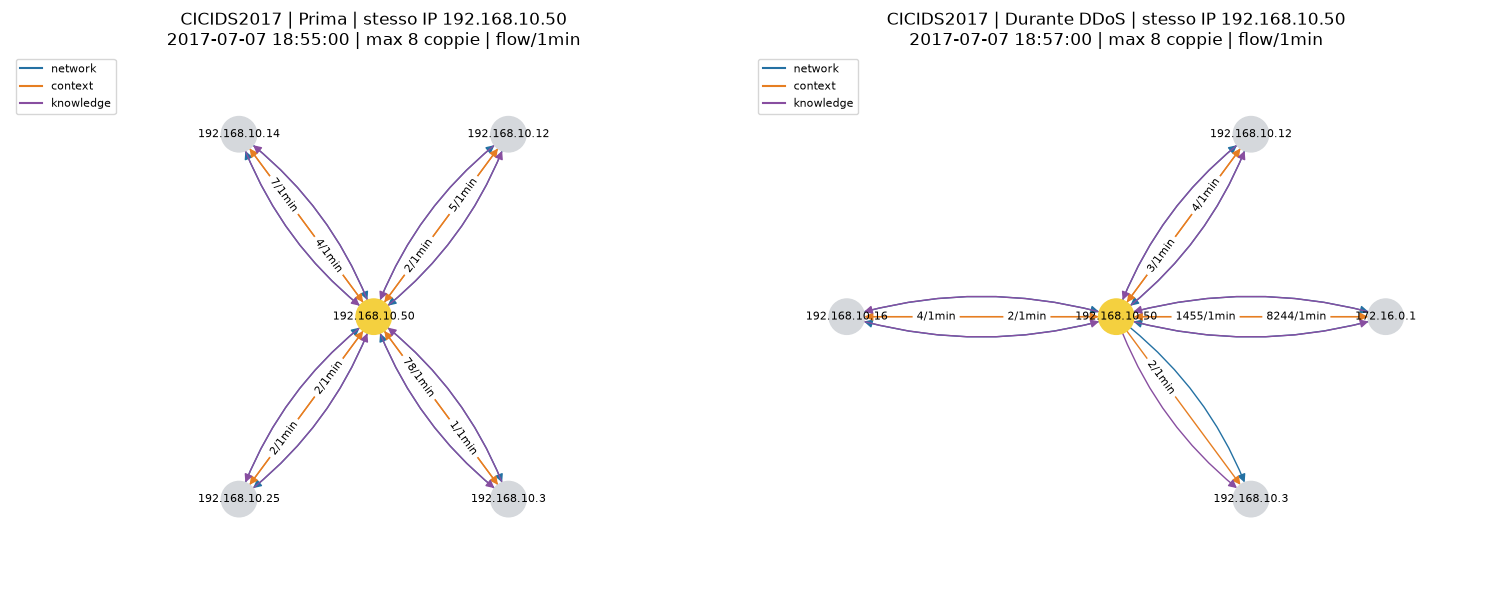

CICToNIoT


,flow,percentuale (%)
attack_type,,
BENIGN,2515236,47.0
xss,2149308,40.16
password,340208,6.36
injection,277696,5.19
scanning,36205,0.68
backdoor,27145,0.51
ransomware,5098,0.1
mitm,517,0.01
ddos,202,0.0


,scenario,IP osservato,minuto,flow benigni,flow attacco
0,prima,192.168.1.1,2019-04-29 19:45:00,9,0
1,durante attacco,192.168.1.1,2019-04-29 22:22:00,13,100


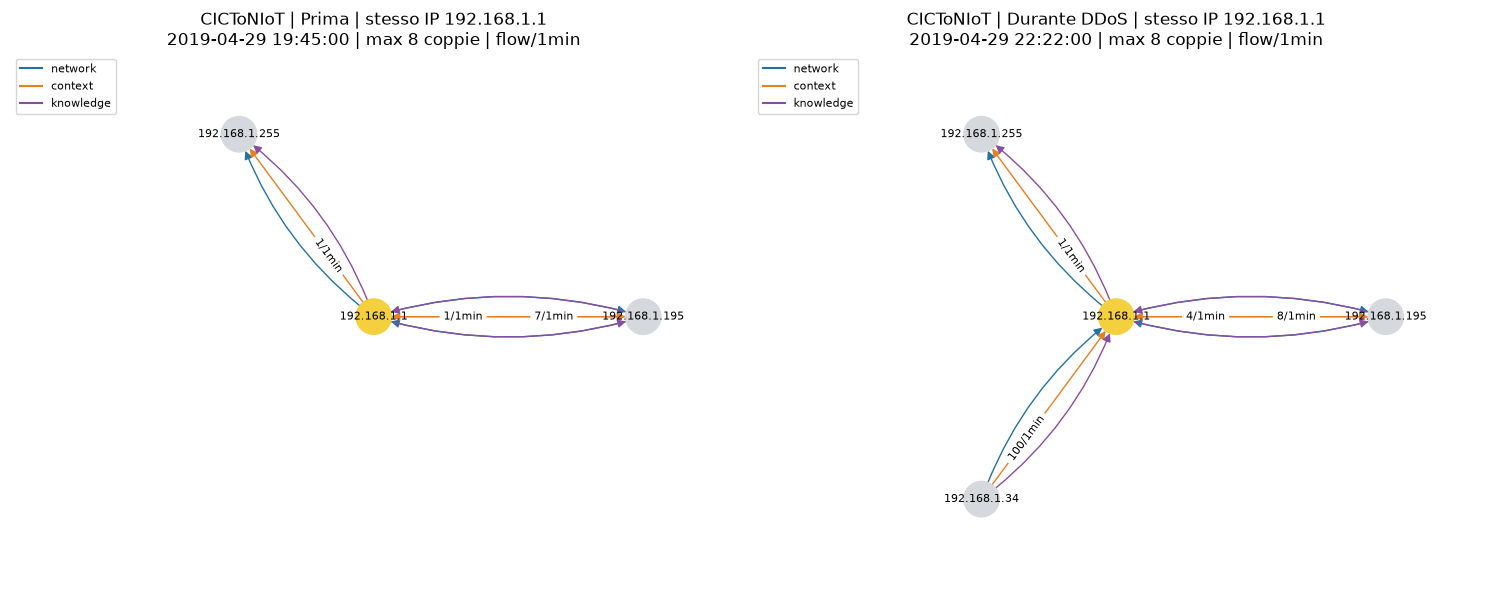

In [2]:
# V3 / 2. DIMENSIONI, CLASSI, FEATURE E STESSO HOST PRIMA/DURANTE L'ATTACCO
display(pd.DataFrame([{"dataset": name, "file": len(DATASETS[name]), "righe lette": frame.attrs["rows_read"],
    "scartate": frame.attrs["rows_read"]-len(frame), "flow validi": len(frame),
    "IP": len(set(frame["Source IP"]) | set(frame["Destination IP"])), "grafi/finestre": frame.window.nunique(),
    "benigni": int((frame.target==0).sum()), "attacchi": int(frame.target.sum()),
    "attacchi (%)": round(100*frame.target.mean(), 2)} for name, frame in datasets.items()]))
feature_summary = pd.DataFrame([
    ["network", "Source Port", "Porta del mittente", "edge_attr", "No"],
    ["network", "Destination Port", "Porta del servizio destinatario", "edge_attr", "No"],
    ["context", "Flow Duration", "Durata della comunicazione", "edge_attr", "No"],
    ["context", "Flow IAT Mean", "Intervallo medio fra pacchetti del flow", "edge_attr", "No"],
    ["knowledge", "Packet Length Std", "Variabilita delle dimensioni dei pacchetti", "edge_attr", "No"],
    ["knowledge", "SYN Flag Count", "Pacchetti con flag TCP SYN", "edge_attr", "No"],
    ["nodi V1/V2", "community", "ID locale arbitrario; solo comparatori storici", "baseline_x", "Si"],
    ["nodi V3", "community_size", "Numero di IP nella comunita locale", "x", "No"],
    ["nodi V3", "centrality", "Quota di cammini minimi che attraversano l’IP (betweenness)", "x", "No"],
    ["nodi", "in_degree", "Flow entranti nell'IP nella finestra", "x", "Si"],
    ["nodi", "out_degree", "Flow uscenti dall'IP nella finestra", "x", "Si"],
], columns=["famiglia", "feature", "significato", "dove si trova", "usata da V1"])
feature_summary["usata da V2"] = ~feature_summary.feature.isin(["community_size","centrality"])
feature_summary["usata da V3"] = feature_summary.feature != "community"
print("Betweenness:","esatta" if CENTRALITY_SAMPLES is None else f"stimata da max {CENTRALITY_SAMPLES} sorgenti/grafo")
display(feature_summary)

def same_host_scenarios(df):
    attacks = df[df["target"] == 1]
    ddos = attacks[attacks["attack_type"].str.contains("ddos", case=False, na=False)]
    if not ddos.empty:
        attacks = ddos
    for host in attacks["Destination IP"].value_counts().index:
        incoming = attacks[attacks["Destination IP"] == host]
        first_attack = incoming["window"].min()
        incident = df[(df["Source IP"] == host) | (df["Destination IP"] == host)]
        earlier = incident[incident["window"] < first_attack]
        benign_windows = earlier.groupby("window")["target"].sum()
        benign_windows = benign_windows[benign_windows == 0]
        if not benign_windows.empty:
            before = incident[incident["window"] == benign_windows.index.max()]
            peak = incoming.groupby("window").size().idxmax()
            during = incident[incident["window"] == peak]
            return host, before, during
    return None


for dataset_name, df in datasets.items():
    print(dataset_name)
    counts = df["attack_type"].value_counts().rename("flow").to_frame()
    counts["percentuale (%)"] = (100*counts["flow"]/len(df)).round(2)
    display(counts)
    scenario = same_host_scenarios(df)
    if scenario is None:
        print("Nessun host con traffico benigno precedente e attacco successivo nei dati selezionati.")
    else:
        host, before, during = scenario
        scenario_summary = pd.DataFrame([
            {"scenario": name, "IP osservato": host, "minuto": part["window"].iloc[0],
             "flow benigni": int((part["target"] == 0).sum()), "flow attacco": int(part["target"].sum())}
            for name, part in [("prima", before), ("durante attacco", during)]
        ])
        display(scenario_summary)
        shown_pairs = []
        for part in [before, during]:
            pairs = part.groupby(["Source IP", "Destination IP"]).size().sort_values(ascending=False)
            shown_pairs.append(pairs.head(MAX_GRAPH_PAIRS))
        union = nx.DiGraph()
        for pairs in shown_pairs:
            union.add_edges_from(pairs.index)
        peers = sorted(set(union.nodes) - {host})
        positions = {host: (0, 0)}
        positions.update({peer: (np.cos(2*np.pi*i/len(peers)), np.sin(2*np.pi*i/len(peers)))
                          for i, peer in enumerate(peers)})
        fig, axes = plt.subplots(1, 2, figsize=(15, 6))
        relation_colors = ["#2471a3", "#e67e22", "#884ea0"]
        for ax, title, part, pairs in zip(axes, ["Prima", "Durante DDoS" if during["attack_type"].str.contains("ddos", case=False, na=False).any() else "Durante attacco"], [before, during], shown_pairs):
            graph = nx.DiGraph()
            graph.add_edges_from(pairs.index)
            nx.draw_networkx_nodes(graph, positions, ax=ax, node_size=650,
                node_color=["#f4d03f" if node == host else "#d5d8dc" for node in graph.nodes])
            nx.draw_networkx_labels(graph, positions, ax=ax, font_size=8)
            for color, radius in zip(relation_colors, [-0.15, 0, 0.15]):
                nx.draw_networkx_edges(graph, positions, ax=ax, node_size=650, edge_color=color,
                    arrowsize=12, connectionstyle=f"arc3,rad={radius}")
            labels = {(u, v): f"{int(count)}/{WINDOW_MINUTES}min" for (u, v), count in pairs.items()}
            nx.draw_networkx_edge_labels(graph, positions, ax=ax, edge_labels=labels, font_size=8, label_pos=0.32)
            ax.legend(handles=[Line2D([0], [0], color=color, label=name)
                               for name, color in zip(SEMANTICS, relation_colors)], loc="upper left", fontsize=8)
            ax.set_title(f"{dataset_name} | {title} | stesso IP {host}\n{part['window'].iloc[0]} | max {MAX_GRAPH_PAIRS} coppie | flow/{WINDOW_MINUTES}min")
            ax.set(xlim=(-1.35, 1.35), ylim=(-1.25, 1.25))
            ax.axis("off")
        plt.tight_layout()
        plt.show()


In [3]:

# V3 / 3. FULL CONTEXT, GRID E V1/V2 CON SETTING FISSO
class MLP(nn.Module):
    def __init__(self, dims):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dims[0], dims[1]), nn.ReLU(), nn.Linear(dims[1], dims[2]))

    def forward(self, x):
        return self.net(x)

class DynamicGraphModule(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=16, k=5):
        super().__init__()
        self.embed = MLP([2*input_dim, hidden_dim, latent_dim])
        if k < 1:
            raise ValueError("dgm_k deve essere positivo")
        self.k = int(k)

    @staticmethod
    def aggregate_initial_neighbors(x, edge_index):
        src, dst = edge_index
        out, degree = torch.zeros_like(x), x.new_zeros(x.size(0))
        out.index_add_(0, src, x[dst])
        degree.index_add_(0, src, x.new_ones(src.numel()))
        return out / degree.clamp_min(1).unsqueeze(-1)

    def forward(self, x, initial_edge_index, batch=None):
        context = self.aggregate_initial_neighbors(x, initial_edge_index)
        z = self.embed(torch.cat([x, context], dim=-1))
        if batch is None:
            batch = torch.zeros(x.size(0), dtype=torch.long, device=x.device)
        links = []
        # Il top-k e discreto; il gradiente attraversa z usato nelle GCN successive.
        with torch.no_grad():
            for graph_id in batch.unique():
                nodes = torch.where(batch == graph_id)[0]
                count, k = len(nodes), min(self.k, len(nodes)-1)
                if k < 1:
                    continue
                latent = z[nodes].detach()
                for start in range(0, count, DGM_DISTANCE_CHUNK_SIZE):
                    stop = min(start+DGM_DISTANCE_CHUNK_SIZE, count)
                    distance = torch.cdist(latent[start:stop], latent, p=2,
                                           compute_mode="donot_use_mm_for_euclid_dist")
                    distance[torch.arange(stop-start, device=x.device),
                             torch.arange(start, stop, device=x.device)] = float("inf")
                    neighbors = distance.topk(k, dim=1, largest=False).indices
                    src = nodes[start:stop, None].expand_as(neighbors).reshape(-1)
                    links.append(torch.stack([src, nodes[neighbors.reshape(-1)]]))
        edges = torch.cat(links, dim=1) if links else torch.empty((2,0), dtype=torch.long, device=x.device)
        return z, edges

def safe_batch_norm(layer, x):
    if layer.training and len(x) == 1:
        return F.batch_norm(x, layer.running_mean, layer.running_var, layer.weight, layer.bias, training=False)
    return layer(x)

class HybridHeteroClassifier(nn.Module):
    def __init__(self, hidden_channels=64, out_channels=32, dropout=0.2, dgm_k=5, latent_dim=16):
        super().__init__()
        self.pre_conv = HeteroConv({r: GATv2Conv(3, hidden_channels, edge_dim=2, add_self_loops=False)
                                   for r in RELATIONS}, aggr="sum")
        self.pre_bn = nn.BatchNorm1d(hidden_channels)
        self.dgm = DynamicGraphModule(hidden_channels, hidden_channels, latent_dim, dgm_k)
        self.post_conv1 = GCNConv(latent_dim, hidden_channels)
        self.post_bn1 = nn.BatchNorm1d(hidden_channels)
        self.post_conv2 = GCNConv(hidden_channels, hidden_channels)
        self.post_bn2 = nn.BatchNorm1d(hidden_channels)
        self.lin_node = nn.Sequential(nn.Linear(hidden_channels, 2*hidden_channels), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(2*hidden_channels, out_channels), nn.ReLU())
        self.lin_edge = nn.Sequential(nn.Linear(2*out_channels, out_channels), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(out_channels, out_channels), nn.ReLU(), nn.Dropout(dropout), nn.Linear(out_channels, 2))

    def latent_graph(self, data):
        x = self.pre_conv({"ip":data["ip"].baseline_x}, data.edge_index_dict, edge_attr_dict=data.edge_attr_dict)["ip"]
        x = F.relu(safe_batch_norm(self.pre_bn, x))
        # Le tre adiacenze iniziali sono copie: una sola ha la stessa media dei vicini.
        return self.dgm(x, data[RELATIONS[0]].edge_index, data["ip"].get("batch", None))

    def forward(self, data):
        z, edges = self.latent_graph(data)
        z = F.relu(safe_batch_norm(self.post_bn1, self.post_conv1(z, edges)))
        z = F.relu(safe_batch_norm(self.post_bn2, self.post_conv2(z, edges)))
        return {"ip": self.lin_node(z)}

    def edge_classify(self, z_src, z_dst):
        return self.lin_edge(torch.cat([z_src, z_dst], dim=-1))

def node_values(graph):
    return torch.log1p(graph["ip"].x.abs())


def baseline_node_values(graph):
    x = graph["ip"].baseline_x.clone()
    x[:,1:] = torch.log1p(x[:,1:].clamp_min(0))
    return x

def edge_values(graph, relation):
    x = graph[relation].edge_attr
    return x.sign()*torch.log1p(x.abs())

def fit_normalization(train_graphs):
    values = {"nodes": torch.cat([node_values(g) for g in train_graphs]),
              "nodes_v12": torch.cat([baseline_node_values(g) for g in train_graphs])}
    values.update({r[1]: torch.cat([edge_values(g, r) for g in train_graphs]) for r in RELATIONS})
    stats = {}
    for name, value in values.items():
        scaler = StandardScaler().fit(value.numpy())
        stats[name] = {"mean": torch.tensor(scaler.mean_, dtype=torch.float32),
                       "scale": torch.tensor(scaler.scale_, dtype=torch.float32)}
    return stats

def normalize_graph(graph, stats):
    graph["ip"].x = (node_values(graph)-stats["nodes"]["mean"])/stats["nodes"]["scale"]
    graph["ip"].baseline_x = (baseline_node_values(graph)-stats["nodes_v12"]["mean"])/stats["nodes_v12"]["scale"]
    for r in RELATIONS:
        graph[r].edge_attr = (edge_values(graph,r)-stats[r[1]]["mean"])/stats[r[1]]["scale"]
    return graph

def new_model(params):
    common = {k: params[k] for k in ["hidden_channels", "out_channels", "dropout"]}
    if params["architecture"] == "full_context":
        return FullContextHeteroClassifier(**common,dgm_k=params["dgm_k"],latent_dim=params["latent_dim"])
    if params["architecture"] == "hybrid":
        return HybridHeteroClassifier(**common, dgm_k=params["dgm_k"], latent_dim=params["latent_dim"])
    if params["architecture"] == "v1":
        return HeteroEdgeClassifier(**common)
    raise ValueError("Architettura sconosciuta")

def choose_model_threshold(items):
    observed = choose_threshold(items)
    below = items.loc[items.score < observed, "score"]
    lower = float(below.max()) if not below.empty else 0.
    threshold = (lower+observed)/2
    assert np.array_equal(items.score.astype("float64") >= threshold, items.score.astype("float64") >= observed)
    return float(threshold)


class HeteroEdgeClassifier(nn.Module):
    def __init__(self, hidden_channels=64, out_channels=32, num_classes=2, dropout=0.2):
        super().__init__()

        self.conv1 = HeteroConv({
            ('ip', 'network', 'ip'): GCNConv(-1, hidden_channels),
            ('ip', 'context', 'ip'): GCNConv(-1, hidden_channels),
            ('ip', 'knowledge', 'ip'): GCNConv(-1, hidden_channels),
            #selected fetures
        }, aggr='sum')

        self.bn1_ip = nn.BatchNorm1d(hidden_channels)

        self.conv2 = HeteroConv({
            ('ip', 'network', 'ip'): GCNConv(hidden_channels, hidden_channels),
            ('ip', 'context', 'ip'): GCNConv(hidden_channels, hidden_channels),
            ('ip', 'knowledge', 'ip'): GCNConv(hidden_channels, hidden_channels),
            #selected fetures
        }, aggr='sum')

        self.bn2_ip = nn.BatchNorm1d(hidden_channels)

        self.lin_node = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels * 2),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_channels * 2, out_channels),
            nn.ReLU()
        )

        self.lin_edge = nn.Sequential(
            nn.Linear(out_channels * 2, out_channels),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(out_channels, out_channels),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(out_channels, num_classes)
        )

    def forward(self, data):
        x_dict = self.conv1({"ip":data["ip"].baseline_x}, data.edge_index_dict)
        x_dict['ip'] = (self.bn1_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn1_ip.running_mean, self.bn1_ip.running_var,
                                      self.bn1_ip.weight, self.bn1_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict = self.conv2(x_dict, data.edge_index_dict)
        x_dict['ip'] = (self.bn2_ip(x_dict['ip']) if x_dict['ip'].size(0) > 1 or not self.training else
                         F.batch_norm(x_dict['ip'], self.bn2_ip.running_mean, self.bn2_ip.running_var,
                                      self.bn2_ip.weight, self.bn2_ip.bias, training=False))
        x_dict['ip'] = F.relu(x_dict['ip'])

        x_dict['ip'] = self.lin_node(x_dict['ip'])
        return x_dict

    def edge_classify(self, z_src, z_dst):
        z_cat = torch.cat([z_src, z_dst], dim=-1)
        logits = self.lin_edge(z_cat)
        return logits

class WeightedDynamicGraphModule(DynamicGraphModule):
    def __init__(self,input_dim,hidden_dim=32,latent_dim=16,k=2):
        super().__init__(input_dim,hidden_dim,latent_dim,k)
        self.temperature = nn.Parameter(torch.tensor(1.0))

    def forward(self,x,initial_edge_index,batch=None):
        context = self.aggregate_initial_neighbors(x,initial_edge_index)
        z = self.embed(torch.cat([x,context],dim=-1))
        if batch is None:
            batch = torch.zeros(len(x),dtype=torch.long,device=x.device)
        links,weights = [],[]
        scale = self.temperature.clamp(-5.,5.).exp()
        for graph_id in batch.unique():
            nodes = torch.where(batch==graph_id)[0]
            count = len(nodes)
            k = min(self.k,count-1)
            if k<1:
                continue
            local = z[nodes]
            for start in range(0,count,DGM_DISTANCE_CHUNK_SIZE):
                stop = min(start+DGM_DISTANCE_CHUNK_SIZE,count)
                def select(latent,temperature_scale,start=start,stop=stop,k=k):
                    distance = torch.cdist(latent[start:stop],latent,p=2,
                                          compute_mode="donot_use_mm_for_euclid_dist").square()
                    diagonal = (torch.arange(start,stop,device=x.device)[:,None]
                                ==torch.arange(len(latent),device=x.device)[None,:])
                    logits = (-distance*temperature_scale).masked_fill(diagonal,float("-inf"))
                    # Denominatore su TUTTI gli altri IP del minuto, non solo sui k selezionati.
                    probabilities = logits.softmax(dim=1)
                    return probabilities.topk(k,dim=1)
                # Ricomputa le distanze nel backward: non conserva tutti i blocchi NxN in memoria.
                if torch.is_grad_enabled():
                    weight,neighbors = gradient_checkpoint(select,local,scale,use_reentrant=False)
                else:
                    weight,neighbors = select(local,scale)
                src = nodes[start:stop,None].expand_as(neighbors).reshape(-1)
                links.append(torch.stack([src,nodes[neighbors.reshape(-1)]]))
                weights.append(weight.reshape(-1))
        edges = torch.cat(links,dim=1) if links else torch.empty((2,0),dtype=torch.long,device=x.device)
        weight = torch.cat(weights) if weights else z.new_empty(0)
        return z,edges,weight


class FiniteGCNConv(GCNConv):
    def __init__(self,in_channels,out_channels):
        super().__init__(in_channels,out_channels,normalize=False,add_self_loops=False)

    def forward(self,x,edge_index,edge_weight=None):
        from torch_geometric.utils import add_remaining_self_loops
        if edge_weight is None:
            edge_weight = x.new_ones(edge_index.size(1))
        edge_index,edge_weight = add_remaining_self_loops(edge_index,edge_weight,fill_value=1.,num_nodes=x.size(0))
        src,dst = edge_index
        degree = x.new_zeros(x.size(0)).scatter_add_(0,dst,edge_weight)
        zero = degree==0
        # Stesso forward della GCN; evita la derivata infinita di 0**(-0.5) prima di mascherarla.
        inverse = degree.masked_fill(zero,1.).pow(-0.5).masked_fill(zero,0.)
        normalized = inverse[src]*edge_weight*inverse[dst]
        return super().forward(x,edge_index,normalized)


class FullContextHeteroClassifier(HeteroEdgeClassifier):
    def __init__(self,hidden_channels=64,out_channels=32,dropout=0.2,dgm_k=2,latent_dim=16):
        super().__init__(hidden_channels=hidden_channels,out_channels=out_channels,dropout=dropout)
        self.dgm = WeightedDynamicGraphModule(4,hidden_channels,latent_dim,dgm_k)
        self.latent_relation = ("ip","latent","ip")
        def convolutions(input_dim):
            layers = {r:GATv2Conv(input_dim,hidden_channels,edge_dim=2,add_self_loops=False) for r in RELATIONS}
            layers[self.latent_relation] = FiniteGCNConv(input_dim,hidden_channels)
            return HeteroConv(layers,aggr="sum")
        self.conv1 = convolutions(4)
        self.conv2 = convolutions(hidden_channels)

    def latent_graph(self,data):
        # Le tre topologie sono identiche; la media dei vicini coincide con la loro unione ripetuta.
        _,edges,weights = self.dgm(data["ip"].x,data[RELATIONS[0]].edge_index,data["ip"].get("batch",None))
        return weights,edges

    def forward(self,data):
        weights,edges = self.latent_graph(data)
        edge_index_dict = dict(data.edge_index_dict)
        edge_index_dict[self.latent_relation] = edges
        edge_weight_dict = {self.latent_relation:weights}
        attrs = {r:data[r].edge_attr for r in RELATIONS}
        x = self.conv1(data.x_dict,edge_index_dict,edge_attr_dict=attrs,edge_weight_dict=edge_weight_dict)["ip"]
        x = F.relu(safe_batch_norm(self.bn1_ip,x))
        x = self.conv2({"ip":x},edge_index_dict,edge_attr_dict=attrs,edge_weight_dict=edge_weight_dict)["ip"]
        x = F.relu(safe_batch_norm(self.bn2_ip,x))
        return {"ip":self.lin_node(x)}


def focal_loss(logits, targets):
    ce = F.cross_entropy(logits, targets, reduction="none")
    return (FOCAL_ALPHA * (1 - torch.exp(-ce)) ** FOCAL_GAMMA * ce).mean()

def graph_loss(model, graph):
    z = model(graph)["ip"]
    return sum(focal_loss(model.edge_classify(z[graph[r].edge_index[0]], z[graph[r].edge_index[1]]),
                          graph[r].edge_label) for r in RELATIONS)

@torch.no_grad()
def predict(model, items, device, batch_size=4):
    model.eval()
    rows = []
    for batch in DataLoader(items, batch_size=batch_size, shuffle=False, num_workers=LOADER_WORKERS):
        batch = batch.to(device)
        z = model(batch)["ip"]
        src, dst = batch[RELATIONS[0]].edge_index
        rows.append(pd.DataFrame({"flow_id": batch.flow_id.cpu().numpy(),
            "target": batch[RELATIONS[0]].edge_label.cpu().numpy(),
            "score": model.edge_classify(z[src], z[dst]).softmax(-1)[:, 1].cpu().numpy()}))
    return pd.concat(rows, ignore_index=True)

def choose_threshold(items):
    if items.target.nunique() != 2:
        raise ValueError("Servono benigni e attacchi per scegliere la soglia F1.")
    if not np.isfinite(items.score).all():
        raise ValueError("Score non finiti.")
    p, r, thresholds = precision_recall_curve(items.target, items.score)
    denominator = p[:-1] + r[:-1]
    f1 = np.divide(2*p[:-1]*r[:-1], denominator, out=np.zeros_like(denominator), where=denominator>0)
    return float(thresholds[np.flatnonzero(f1 == f1.max())[-1]])

def split_graphs(graphs, seed=None):
    if seed is None:
        seed = SPLIT_SEED
    if len(graphs)<3:
        raise ValueError("Servono almeno tre finestre per train, validation e test.")
    rest_size = max(2, int(np.ceil((HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION)*len(graphs))))
    if rest_size>=len(graphs):
        raise ValueError("Le frazioni holdout lasciano troppo pochi grafi nel train")
    indices = np.arange(len(graphs))
    strata = np.array([int(g[RELATIONS[0]].edge_label.max()) for g in graphs])
    classes, counts = np.unique(strata,return_counts=True)
    stratify = strata if min(counts)>=4 and min(rest_size,len(graphs)-rest_size)>=len(classes) else None
    train, rest = train_test_split(indices,test_size=rest_size,random_state=seed,stratify=stratify)
    ratio = HOLDOUT_TEST_FRACTION/(HOLDOUT_TEST_FRACTION+HOLDOUT_VAL_FRACTION)
    test_size = min(len(rest)-1,max(1,int(np.ceil(ratio*len(rest)))))
    classes, counts = np.unique(strata[rest],return_counts=True)
    stratify = strata[rest] if min(counts)>=2 and min(test_size,len(rest)-test_size)>=len(classes) else None
    val, test = train_test_split(rest,test_size=test_size,random_state=seed,stratify=stratify)
    return [[graphs[i] for i in part] for part in [train,val,test]]

def save_checkpoint(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)

def flow_counts(flows):
    return flows.groupby(["window", "Source IP", "Destination IP"]).size().rename("flow_count").reset_index()

def count_features(flows):
    result = flows[["flow_id", "window", "Source IP", "Destination IP", "target", "attack_type"]].merge(
        flow_counts(flows), on=["window", "Source IP", "Destination IP"], validate="many_to_one")
    result["source_out"] = result.groupby(["window", "Source IP"])["flow_id"].transform("size")
    result["destination_in"] = result.groupby(["window", "Destination IP"])["flow_id"].transform("size")
    return result

def fit_count_thresholds(train_flows):
    counts = flow_counts(train_flows).flow_count
    if counts.empty:
        raise ValueError("Nessuna coppia IP/minuto nel train.")
    return {f"P{q:g}": float(counts.quantile(q/100)) for q in COUNT_PERCENTILES}

def record_training_failure(model,batch,params,path,epoch,batch_index,reason):
    failure = Path(path).with_suffix(".failure.pt")
    save_checkpoint({"state_dict":{k:v.detach().cpu() for k,v in model.state_dict().items()},
        "batch":batch.cpu(),"params":params,"epoch":epoch,"batch_index":batch_index,"reason":reason,
        "seed":SEED,"focal_alpha":FOCAL_ALPHA,"focal_gamma":FOCAL_GAMMA},failure)
    raise RuntimeError(f"{reason}; epoca {epoch}, batch {batch_index}. Diagnostica: {failure}")


def resume_configuration():
    values = {name:globals()[name] for name in ["SEED","SPLIT_SEED","WINDOW_MINUTES","N_FOLDS",
        "FOLDS_TO_RUN","HOLDOUT_TEST_FRACTION","HOLDOUT_VAL_FRACTION","KFOLD_VAL_FRACTION",
        "GRID_SEARCH","MODEL_PARAMS","PARAM_GRID","BASELINE_PARAMS","BASELINE_V2_PARAMS",
        "MAX_EPOCHS","EARLY_STOPPING","PATIENCE","MIN_DELTA","FOCAL_ALPHA","FOCAL_GAMMA",
        "CENTRALITY_SAMPLES","DGM_DISTANCE_CHUNK_SIZE","SEMANTICS"]}
    values["files"] = {name:[{"path":str(Path(p).resolve()),"bytes":Path(p).stat().st_size,
        "mtime_ns":Path(p).stat().st_mtime_ns} for p in paths] for name,paths in DATASETS.items()}
    return json.loads(json.dumps(values))


def ensure_resume_configuration():
    RUN_DIR.mkdir(parents=True,exist_ok=True)
    path = RUN_DIR/"resume_config.json"
    current = resume_configuration()
    if path.exists():
        if json.loads(path.read_text(encoding="utf-8")) != current:
            raise ValueError("Configurazione o dati cambiati: usare un nuovo RUN_DIR per evitare di mescolare esperimenti")
    else:
        temporary = path.with_suffix(".json.tmp")
        temporary.write_text(json.dumps(current,indent=2),encoding="utf-8")
        temporary.replace(path)


def graph_cache_metadata(dataset_name,df):
    return {"schema":"marco_v3_graphs_1","rows":len(df),"windows":int(df.window.nunique()),
        "window_minutes":WINDOW_MINUTES,"centrality_samples":CENTRALITY_SAMPLES,"split_seed":SPLIT_SEED,
        "semantics":SEMANTICS,"files":resume_configuration()["files"][dataset_name]}


def cached_graphs(dataset_name,df):
    path = RUN_DIR/"graph_cache"/f"{dataset_name}.pt"
    metadata = graph_cache_metadata(dataset_name,df)
    if path.exists():
        # Cache locale creata da questo notebook; contiene oggetti PyG oltre ai tensori.
        cached = torch.load(path,map_location="cpu",weights_only=False)
        if cached["metadata"] != metadata:
            raise ValueError(f"Cache grafi incompatibile: {path}; usare un nuovo RUN_DIR")
        result = cached["graphs"]
        print(dataset_name,"| riuso",len(result),"grafi dalla cache:",path,flush=True)
    else:
        result = [build_graph(part) for _,part in tqdm(df.groupby("window",sort=True),desc=f"Grafi {dataset_name}")]
        save_checkpoint({"metadata":metadata,"graphs":result},path)
    assert len(result)==metadata["windows"] and sum(g[RELATIONS[0]].num_edges for g in result)==len(df)
    return result


def train_or_reuse(train_items,val_items,params,path,max_epochs,patience,min_delta,normalization):
    if Path(path).exists():
        checkpoint = torch.load(path,map_location="cpu",weights_only=True)
        if all(key in checkpoint for key in ["history","threshold","epochs_run","validation_F1","validation_AP"]):
            if (checkpoint["params"]!=params or checkpoint["seed"]!=SEED
                or any(not torch.equal(v,checkpoint["normalization"][key][field])
                    for key,payload in normalization.items() for field,v in payload.items())):
                raise ValueError(f"Checkpoint incompatibile: {path}")
            print("Training gia completato, riuso:",path,flush=True)
            return checkpoint
    # Un best checkpoint intermedio non contiene optimizer/RNG: il modello incompleto riparte dall'epoca 1.
    return train_model(train_items,val_items,params,path,max_epochs,patience,min_delta,normalization)


def train_model(train_items, val_items, params, checkpoint_path, max_epochs, patience, min_delta, normalization):
    if max_epochs < 1 or (EARLY_STOPPING and (patience < 1 or min_delta < 0 or not np.isfinite(min_delta))):
        raise ValueError("Epoche/patience positive e min_delta non negativo.")
    seed_everything(SEED)
    model = new_model(params).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_items, batch_size=params["batch_size"], shuffle=True,
                              generator=generator, num_workers=LOADER_WORKERS)
    val_loader = DataLoader(val_items, batch_size=params["batch_size"], shuffle=False, num_workers=LOADER_WORKERS)
    history, best_loss, significant_loss, stale = [], float("inf"), float("inf"), 0
    progress = tqdm(range(1, max_epochs+1), desc=Path(checkpoint_path).stem, unit="epoca", position=0, leave=True)
    for epoch in progress:
        model.train()
        train_sum, train_count = 0., 0
        for batch_index,batch in enumerate(train_loader,1):
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            loss = graph_loss(model, batch)
            if not torch.isfinite(loss):
                record_training_failure(model,batch,params,checkpoint_path,epoch,batch_index,"Loss train non finita")
            loss.backward()
            finite_gradients = [torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None]
            if finite_gradients and not torch.stack(finite_gradients).all():
                record_training_failure(model,batch,params,checkpoint_path,epoch,batch_index,"Gradienti train non finiti")
            optimizer.step()
            count = batch[RELATIONS[0]].num_edges
            train_sum += loss.item()*count
            train_count += count
        model.eval()
        val_sum, val_count = 0., 0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(DEVICE)
                count = batch[RELATIONS[0]].num_edges
                val_sum += graph_loss(model, batch).item()*count
                val_count += count
        train_loss, val_loss = train_sum/train_count, val_sum/val_count
        if not np.isfinite(val_loss):
            raise RuntimeError("Loss validation non finita.")
        history.append({"epoca": epoch, "train": train_loss, "validation": val_loss})
        if val_loss < best_loss:
            best_loss = val_loss
            save_checkpoint({"state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "params": params, "normalization": normalization, "best_epoch": epoch, "validation_loss": val_loss, "seed": SEED}, checkpoint_path)
        if EARLY_STOPPING:
            if val_loss < significant_loss - min_delta:
                significant_loss, stale = val_loss, 0
            else:
                stale += 1
        progress.set_postfix(train=f"{train_loss:.5f}", validation=f"{val_loss:.5f}", attesa=stale if EARLY_STOPPING else "off")
        if EARLY_STOPPING and stale >= patience:
            break
    progress.close()
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model.load_state_dict(checkpoint["state_dict"])
    validation = predict(model, val_items, DEVICE, params["batch_size"])
    threshold = choose_model_threshold(validation)
    vp, vr, vf1, _ = precision_recall_fscore_support(validation.target, validation.score.astype("float64")>=threshold,
                                                   average="binary", zero_division=0)
    checkpoint.update({"threshold": threshold, "history": history,
        "validation_F1": float(vf1), "validation_AP": float(average_precision_score(validation.target, validation.score)),
        "epochs_run": len(history), "stopped_early": len(history)<max_epochs, "early_stopping": EARLY_STOPPING,
        "focal_alpha": FOCAL_ALPHA, "focal_gamma": FOCAL_GAMMA})
    save_checkpoint(checkpoint, checkpoint_path)
    return checkpoint


# Verifica anche GAT, kNN e backward sul backend selezionato.
probe_model = None
try:
    probe = HeteroData()
    probe["ip"].x = torch.ones(3,4,device=DEVICE)
    for r in RELATIONS:
        probe[r].edge_index = torch.tensor([[0,1,2,0],[1,2,0,2]], device=DEVICE)
        probe[r].edge_attr = torch.ones(4,2,device=DEVICE)
        probe[r].edge_label = torch.tensor([0,1,0,1],device=DEVICE)
    probe_model = FullContextHeteroClassifier(hidden_channels=8, out_channels=4).to(DEVICE)
    probe_loss = graph_loss(probe_model, probe)
    probe_loss.backward()
    if not torch.isfinite(probe_loss):
        raise RuntimeError("Loss di prova ibrido non finita")
except (RuntimeError, NotImplementedError) as error:
    if DEVICE.type == "cpu":
        raise
    print("Backend non compatibile con l'ibrido, uso CPU:", error)
    DEVICE, DEVICE_NAME = torch.device("cpu"), "CPU (fallback operazioni ibrido)"
finally:
    del probe, probe_model


def evaluation_splits(graphs, dataset_name):
    count = N_FOLDS.get(dataset_name, 1)
    if isinstance(count, bool) or not isinstance(count, int) or not 1 <= count <= len(graphs):
        raise ValueError(f"{dataset_name}: N_FOLDS deve essere 1 oppure un intero da 2 a {len(graphs)}")
    if len({g.window for g in graphs}) != len(graphs):
        raise ValueError("Ogni minuto deve corrispondere a un solo grafo prima dei fold")
    selected = FOLDS_TO_RUN.get(dataset_name)
    if selected is not None:
        if (not isinstance(selected, (list,tuple)) or not selected
            or any(isinstance(f,bool) or not isinstance(f,int) or not 1 <= f <= count for f in selected)
            or len(set(selected)) != len(selected)):
            raise ValueError(f"{dataset_name}: FOLDS_TO_RUN deve essere None o una lista senza duplicati fra 1 e {count}")
    if count == 1:
        return [(1, *split_graphs(graphs, SPLIT_SEED))]
    strata = np.array([int(g[RELATIONS[0]].edge_label.max()) for g in graphs])
    counts = np.unique(strata, return_counts=True)[1]
    splitter = (StratifiedKFold(count, shuffle=True, random_state=SPLIT_SEED) if min(counts) >= count
                else KFold(count, shuffle=True, random_state=SPLIT_SEED))
    folds = []
    for fold, (remaining, test) in enumerate(splitter.split(np.arange(len(graphs)), strata), 1):
        if selected is not None and fold not in selected:
            continue
        if len(remaining) < 3:
            raise ValueError("Troppi pochi grafi per separare train e validation dentro ogni fold")
        labels = strata[remaining]
        classes, frequencies = np.unique(labels, return_counts=True)
        val_size = int(np.ceil(KFOLD_VAL_FRACTION*len(remaining)))
        stratify = labels if min(frequencies)>=2 and val_size>=len(classes) and len(remaining)-val_size>=len(classes) else None
        train, val = train_test_split(remaining, test_size=KFOLD_VAL_FRACTION, random_state=SPLIT_SEED, stratify=stratify)
        parts = [[graphs[i] for i in indices] for indices in [train,val,test]]
        for name, part in zip(["train","validation","test"],parts):
            labels = {int(y) for g in part for y in g[RELATIONS[0]].edge_label.unique().tolist()}
            if labels != {0,1}:
                raise ValueError(f"{dataset_name}, fold {fold}: {name} non contiene entrambe le classi; ridurre i fold o cambiare split")
        folds.append((fold,*parts))
    tested = [g.window for _,_,_,test in folds for g in test]
    assert len(tested) == len(set(tested)), "Finestre ripetute nei test esterni"
    if selected is None:
        assert set(tested) == {g.window for g in graphs}, "K-fold incompleta"
    return folds

ensure_resume_configuration()
if globals().get("_V3_ACTIVE_RUN") != str(RUN_DIR.resolve()):
    experiments = {}
    _V3_ACTIVE_RUN = str(RUN_DIR.resolve())
for dataset_name, df in datasets.items():
    count = N_FOLDS.get(dataset_name,1)
    if isinstance(count,bool) or not isinstance(count,int) or count<1:
        raise ValueError("N_FOLDS deve essere un intero positivo")
    requested = FOLDS_TO_RUN.get(dataset_name) or list(range(1,count+1))
    completed = [dataset_name if count==1 else f"{dataset_name}/fold_{i:02d}" for i in requested]
    if all(key in experiments for key in completed):
        print(dataset_name,"| fold gia completati in questo kernel:",requested,flush=True)
        continue
    graphs = cached_graphs(dataset_name,df)
    assert sum(g[RELATIONS[0]].num_edges for g in graphs) == len(df)
    n_folds = N_FOLDS.get(dataset_name,1)
    if not GRID_SEARCH and dataset_name not in MODEL_PARAMS:
        raise ValueError(f"Mancano MODEL_PARAMS per {dataset_name}")
    fold_splits = evaluation_splits(graphs,dataset_name)
    for fold, train_graphs, val_graphs, test_graphs in fold_splits:
        folder = RUN_DIR/dataset_name
        if n_folds>1:
            folder = folder/f"fold_{fold:02d}"
        folder.mkdir(parents=True,exist_ok=True)
        experiment_key = dataset_name if n_folds==1 else f"{dataset_name}/fold_{fold:02d}"
        if experiment_key in experiments:
            print(experiment_key,"| gia completato, continuo con il successivo",flush=True)
            continue
        print(f"{dataset_name} | fold {fold}/{n_folds}",flush=True)
        train_graphs = [g.clone() for g in train_graphs]
        val_graphs = [g.clone() for g in val_graphs]
        test_graphs = [g.clone() for g in test_graphs]
        parts = [train_graphs,val_graphs,test_graphs]
        windows = [{g.window for g in part} for part in parts]
        ids = [{int(i) for g in part for i in g.flow_id.tolist()} for part in parts]
        assert all(windows[i].isdisjoint(windows[j]) and ids[i].isdisjoint(ids[j]) for i in range(3) for j in range(i))
        assert all(len({int(y) for g in part for y in g[RELATIONS[0]].edge_label.unique().tolist()})==2 for part in parts)
        split_table = pd.DataFrame([{"split":name,"grafi":len(part),"flow":len(flow_ids),
            "attacchi":sum(int(g[RELATIONS[0]].edge_label.sum()) for g in part)}
            for name,part,flow_ids in zip(["train","validation","test"],parts,ids)])
        print(dataset_name,"| 0 finestre e 0 flow_id condivisi; stessi split per tutti i modelli")
        display(split_table)
        split_table.to_csv(folder/"split_summary.csv",index=False)
        pd.DataFrame([{"flow_id":i,"split":name} for name,flow_ids in zip(["train","validation","test"],ids)
                      for i in sorted(flow_ids)]).to_csv(folder/"split_flows.csv",index=False)
        normalization = fit_normalization(train_graphs)
        torch.save(normalization, folder/"normalization.pt")
        for graph in train_graphs+val_graphs+test_graphs:
            normalize_graph(graph, normalization)
        print(f"Max IP/grafo: {max(g['ip'].num_nodes for g in graphs)}; normalizzazione fit solo sul train")
        grid_rows, champion = [], None
        grid = (list(ParameterGrid(PARAM_GRID)) if GRID_SEARCH else [MODEL_PARAMS[dataset_name]])
        for trial, params in enumerate(grid,1):
            print(f"{dataset_name} | ibrido {trial}/{len(grid)} | {params}",flush=True)
            start = time.perf_counter()
            checkpoint = train_or_reuse(train_graphs,val_graphs,params,folder/"checkpoints"/f"trial_{trial:03d}.pt",
                                     MAX_EPOCHS,PATIENCE,MIN_DELTA,normalization)
            row = {"trial":trial,**params,**{k:checkpoint[k] for k in ["best_epoch","epochs_run","stopped_early",
                   "validation_loss","validation_F1","validation_AP","threshold"]},"seconds":time.perf_counter()-start}
            grid_rows.append(row)
            pd.DataFrame(grid_rows).to_csv(folder/"grid_search.csv",index=False)
            rank = (checkpoint["validation_F1"],checkpoint["validation_AP"],-checkpoint["validation_loss"])
            if champion is None or rank > (champion["validation_F1"],champion["validation_AP"],-champion["validation_loss"]):
                champion = checkpoint
                save_checkpoint(checkpoint, folder/"best_model.pt")
            print(f"F1 validation {100*checkpoint['validation_F1']:.2f}% | checkpoint epoca {checkpoint['best_epoch']}")
        print(dataset_name,"| HeteroGCN V1: un solo setting",BASELINE_PARAMS,flush=True)
        baseline = train_or_reuse(train_graphs,val_graphs,BASELINE_PARAMS,folder/"baseline_v1.pt",
                               MAX_EPOCHS,PATIENCE,MIN_DELTA,normalization)
        print(dataset_name,"| Ibrido V2: un solo setting",BASELINE_V2_PARAMS,flush=True)
        baseline_v2 = train_or_reuse(train_graphs,val_graphs,BASELINE_V2_PARAMS,folder/"baseline_v2.pt",
                                  MAX_EPOCHS,PATIENCE,MIN_DELTA,normalization)
        display(pd.DataFrame(grid_rows).sort_values(["validation_F1","validation_AP","validation_loss"],
                                                   ascending=[False,False,True]).head(5))
        print("Ibrido scelto:",champion["params"],"| soglia validation:",champion["threshold"])
        experiments[experiment_key] = {"dataset":dataset_name,"fold":fold,"n_folds":n_folds,"folder":folder,"best":champion,"baseline":baseline,"test_graphs":test_graphs,
            "train_ids": np.fromiter(ids[0], dtype=np.int64),"val_ids": np.fromiter(ids[1], dtype=np.int64),"test_ids": np.fromiter(ids[2], dtype=np.int64),"grid_rows":grid_rows}
        del train_graphs,val_graphs,parts,graph,checkpoint
        gc.collect()
    del graphs,fold_splits
    gc.collect()


CICIDS2017 | fold gia completati in questo kernel: [1, 2, 3, 4, 5]


CICToNIoT | riuso 7206 grafi dalla cache: data\marco_output_v3\20261026_094912_086837\graph_cache\CICToNIoT.pt


CICToNIoT | fold 1/5


CICToNIoT | 0 finestre e 0 flow_id condivisi; stessi split per tutti i modelli


,split,grafi,flow,attacchi
0,train,4899,3716390,1947430
1,validation,865,480643,258886
2,test,1442,1154727,630208


...

baseline_v2:  35%|███▌      | 35/100 [21:03<39:04, 36.06s/epoca, attesa=9, train=0.02331, validation=0.02067]

baseline_v2:  35%|███▌      | 35/100 [21:39<39:04, 36.06s/epoca, attesa=10, train=0.02156, validation=0.01901]

baseline_v2:  35%|███▌      | 35/100 [21:39<40:13, 37.13s/epoca, attesa=10, train=0.02156, validation=0.01901]

,trial,architecture,hidden_channels,out_channels,latent_dim,dgm_k,dropout,lr,weight_decay,batch_size,best_epoch,epochs_run,stopped_early,validation_loss,validation_F1,validation_AP,threshold,seconds
0,1,full_context,64,32,16,2,0.2,0.001,0.001,4,21,21,True,0.014563,0.990378,0.972348,0.455043,1485.002925


Ibrido scelto: {'architecture': 'full_context', 'hidden_channels': 64, 'out_channels': 32, 'latent_dim': 16, 'dgm_k': 2, 'dropout': 0.2, 'lr': 0.001, 'weight_decay': 0.001, 'batch_size': 4} | soglia validation: 0.4550431966781616


CICIDS2017 | test fold 1/5


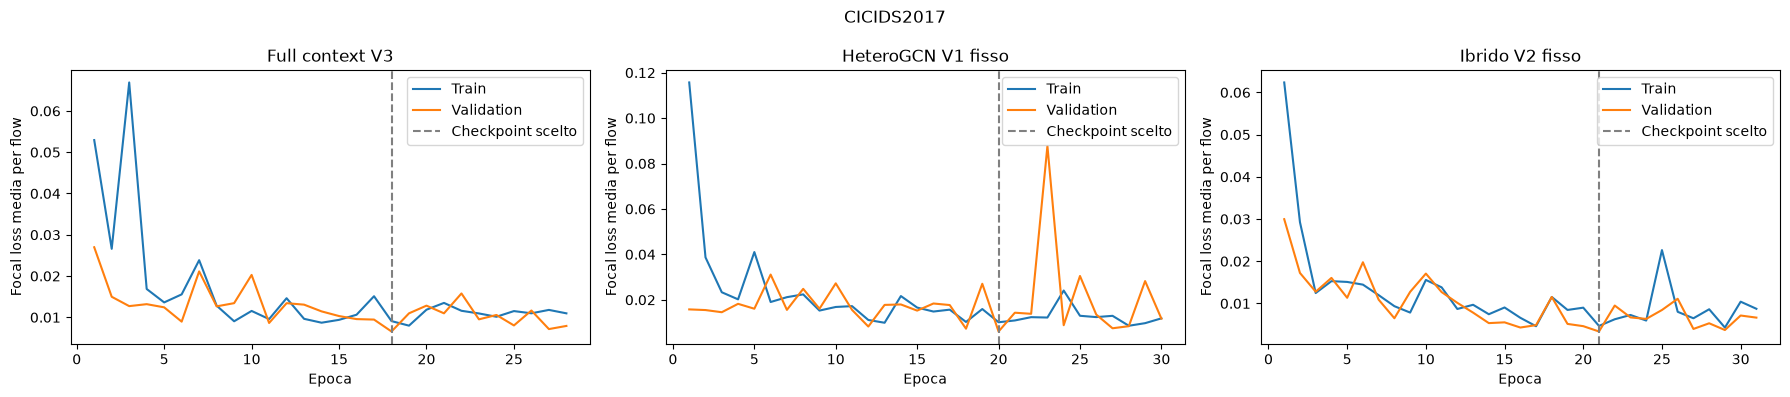

CICIDS2017 | percentili train: {'P90': 5.0, 'P95': 9.0, 'P99': 62.0} | soglia F1 train: 2438.0
Albero appreso sul train:
|--- destination_in <= 2281.50
|   |--- class: 0
|--- destination_in >  2281.50
|   |--- class: 1

Accuracy sempre benigno: 83.85%


CICIDS2017 | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,95.60,93.43,97.88,98.54,99.32,99.77,98.28,0.95,5852,1803
HeteroGCN V1 fisso,95.30,93.52,97.14,98.45,93.95,99.29,97.92,0.94,5720,2428
Ibrido V2 fisso,97.80,97.03,98.59,99.28,99.47,99.82,99.01,0.97,2568,1196
Dummy P90,36.69,22.48,99.70,44.44,96.31,98.02,66.75,0.27,292047,252
Dummy P95,39.64,24.75,99.47,51.08,96.31,98.02,70.61,0.32,256923,447
Dummy P99,47.94,31.64,98.85,65.33,96.31,98.02,78.86,0.42,181417,975
Dummy soglia train,96.31,100.00,92.88,98.85,96.31,98.02,96.44,0.96,0,6053
Albero profondita 1,96.26,99.89,92.88,98.83,93.92,96.43,96.43,0.96,86,6053


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,100401,247,16.76,12.55,92,216
HeteroGCN V1 fisso,100401,247,16.34,10.12,34,222
Ibrido V2 fisso,100401,247,19.89,14.57,79,211
Dummy P90,100401,247,1.62,33.20,9776,165
Dummy P95,100401,247,2.13,21.46,4669,194
Dummy P99,100401,247,6.03,14.98,943,210
Dummy soglia train,100401,247,7.03,3.64,0,238
Albero profondita 1,100401,247,6.45,3.64,23,238


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,98.67,98.70,99.42
Bot,0.00,0.00,0.00
DDoS,100.00,100.00,100.00
DoS Hulk,100.00,100.00,100.00
DoS Slowhttptest,93.95,0.00,67.43
DoS slowloris,75.13,99.80,99.80
FTP-Patator,85.11,72.80,96.76
Heartbleed,0.00,0.00,0.00
Infiltration,8.33,0.00,8.33


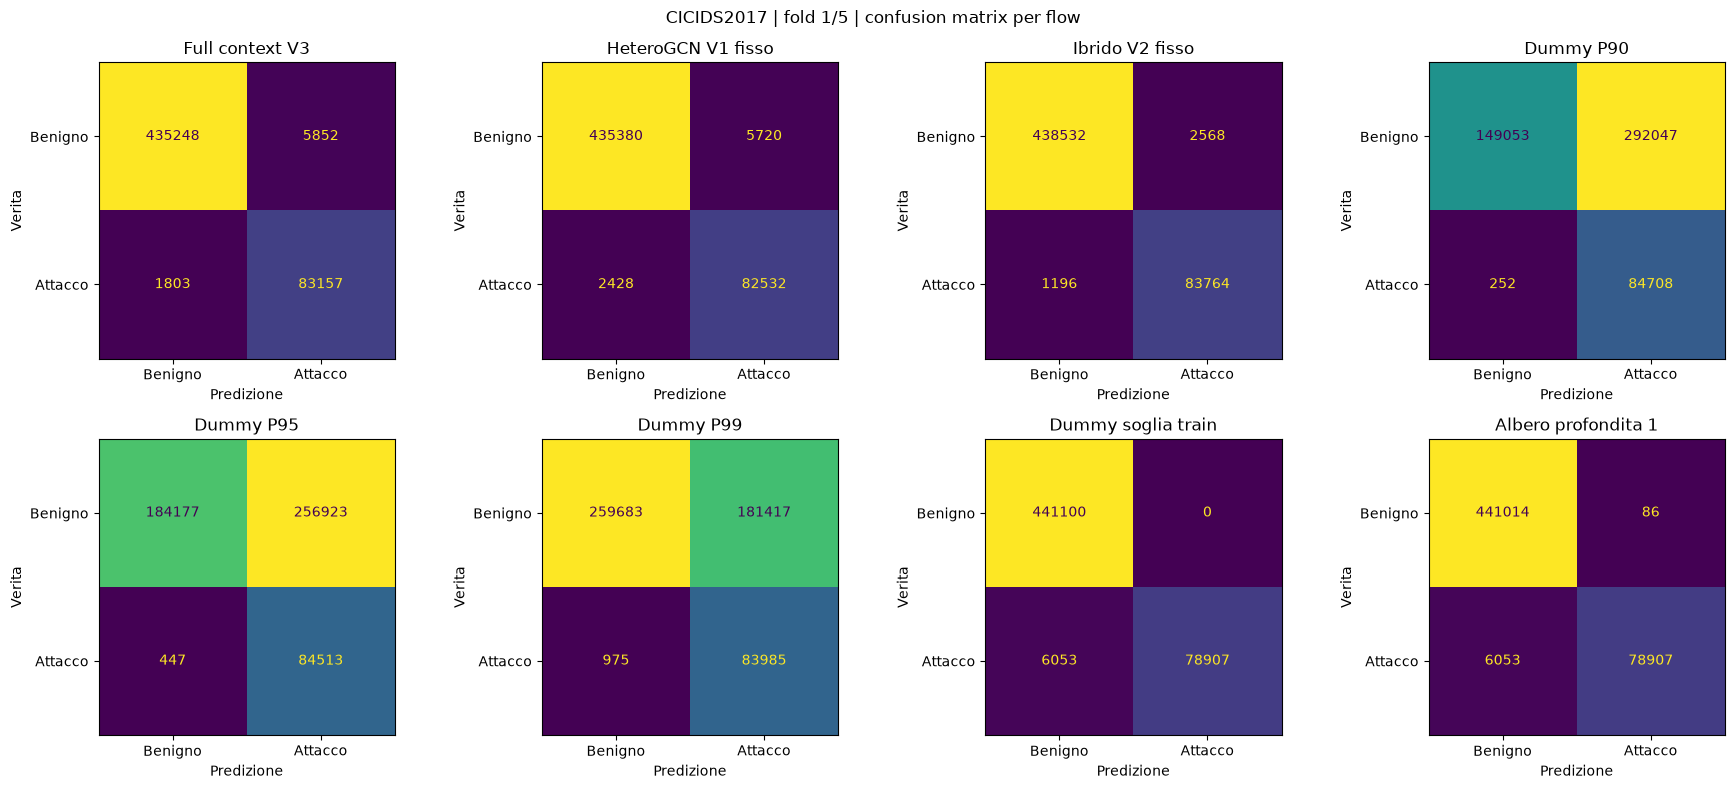

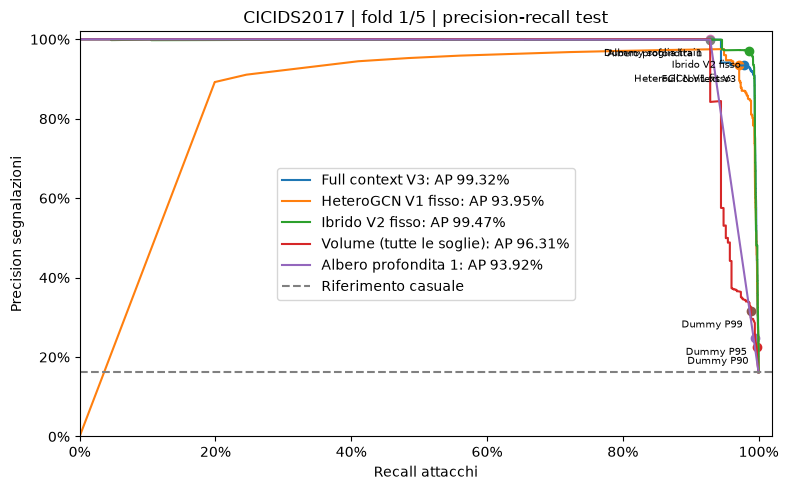

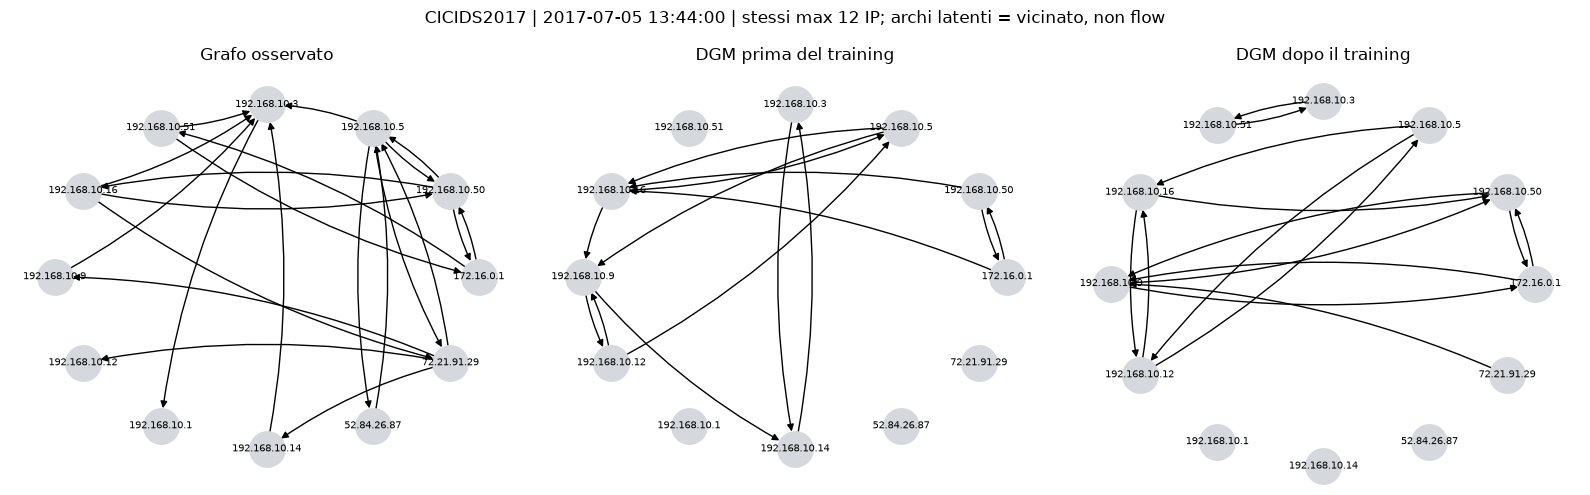

CICIDS2017 | test fold 2/5


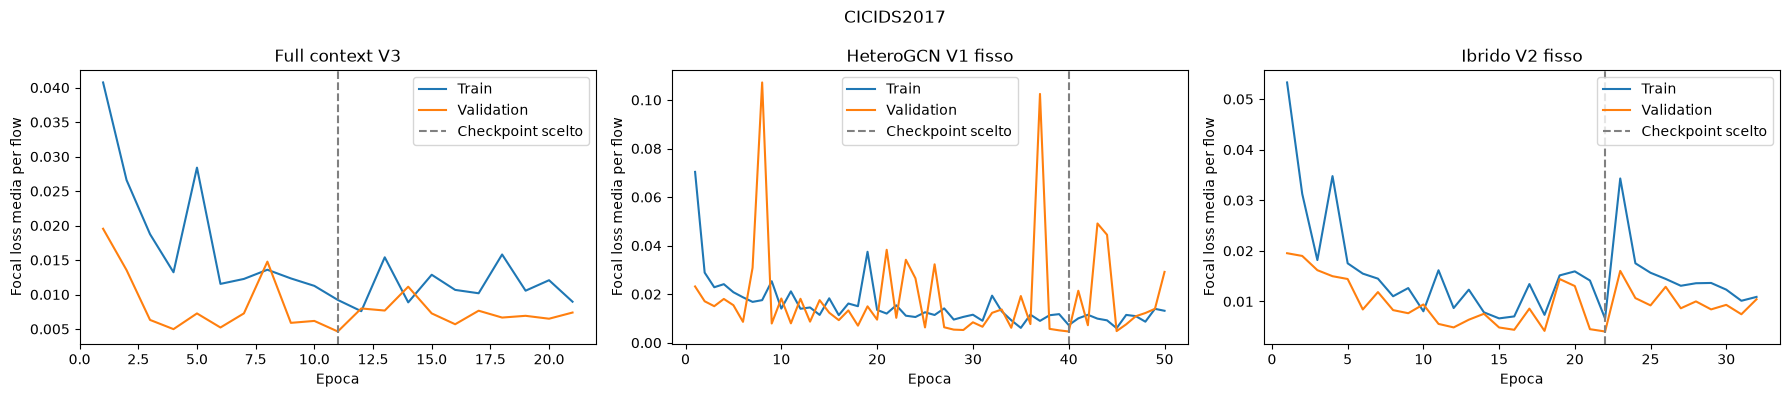

CICIDS2017 | percentili train: {'P90': 5.0, 'P95': 9.0, 'P99': 62.0} | soglia F1 train: 2438.0
Albero appreso sul train:
|--- destination_in <= 2281.50
|   |--- class: 0
|--- destination_in >  2281.50
|   |--- class: 1

Accuracy sempre benigno: 81.40%


CICIDS2017 | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,96.40,95.77,97.03,98.65,99.42,99.79,98.03,0.96,4440,3076
HeteroGCN V1 fisso,95.17,92.51,97.99,98.15,99.50,99.82,98.09,0.94,8223,2083
Ibrido V2 fisso,98.58,98.73,98.43,99.47,99.63,99.83,99.07,0.98,1310,1624
Dummy P90,40.89,25.72,99.80,46.35,96.55,98.13,66.97,0.29,298832,207
Dummy P95,43.82,28.08,99.61,52.49,96.55,98.13,70.67,0.34,264414,400
Dummy P99,52.08,35.33,99.08,66.09,96.55,98.13,78.82,0.45,188043,952
Dummy soglia train,94.74,100.00,90.01,98.14,96.55,98.13,95.01,0.94,0,10354
Albero profondita 1,94.70,99.91,90.01,98.13,91.79,95.00,95.00,0.94,83,10354


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,103816,216,15.15,18.52,272,176
HeteroGCN V1 fisso,103816,216,20.28,20.37,174,172
Ibrido V2 fisso,103816,216,22.94,18.06,85,177
Dummy P90,103816,216,1.70,40.28,9907,129
Dummy P95,103816,216,2.29,27.31,4883,157
Dummy P99,103816,216,6.89,19.91,990,173
Dummy soglia train,103816,216,5.41,2.78,0,210
Albero profondita 1,103816,216,4.94,2.78,21,210


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,99.02,98.19,99.71
Bot,0.00,0.00,0.00
DDoS,100.00,100.00,100.00
DoS GoldenEye,75.26,100.00,100.00
DoS Hulk,100.00,100.00,100.00
DoS Slowhttptest,12.11,94.39,94.39
DoS slowloris,89.21,89.21,89.21
FTP-Patator,100.00,100.00,82.47
Heartbleed,0.00,0.00,0.00


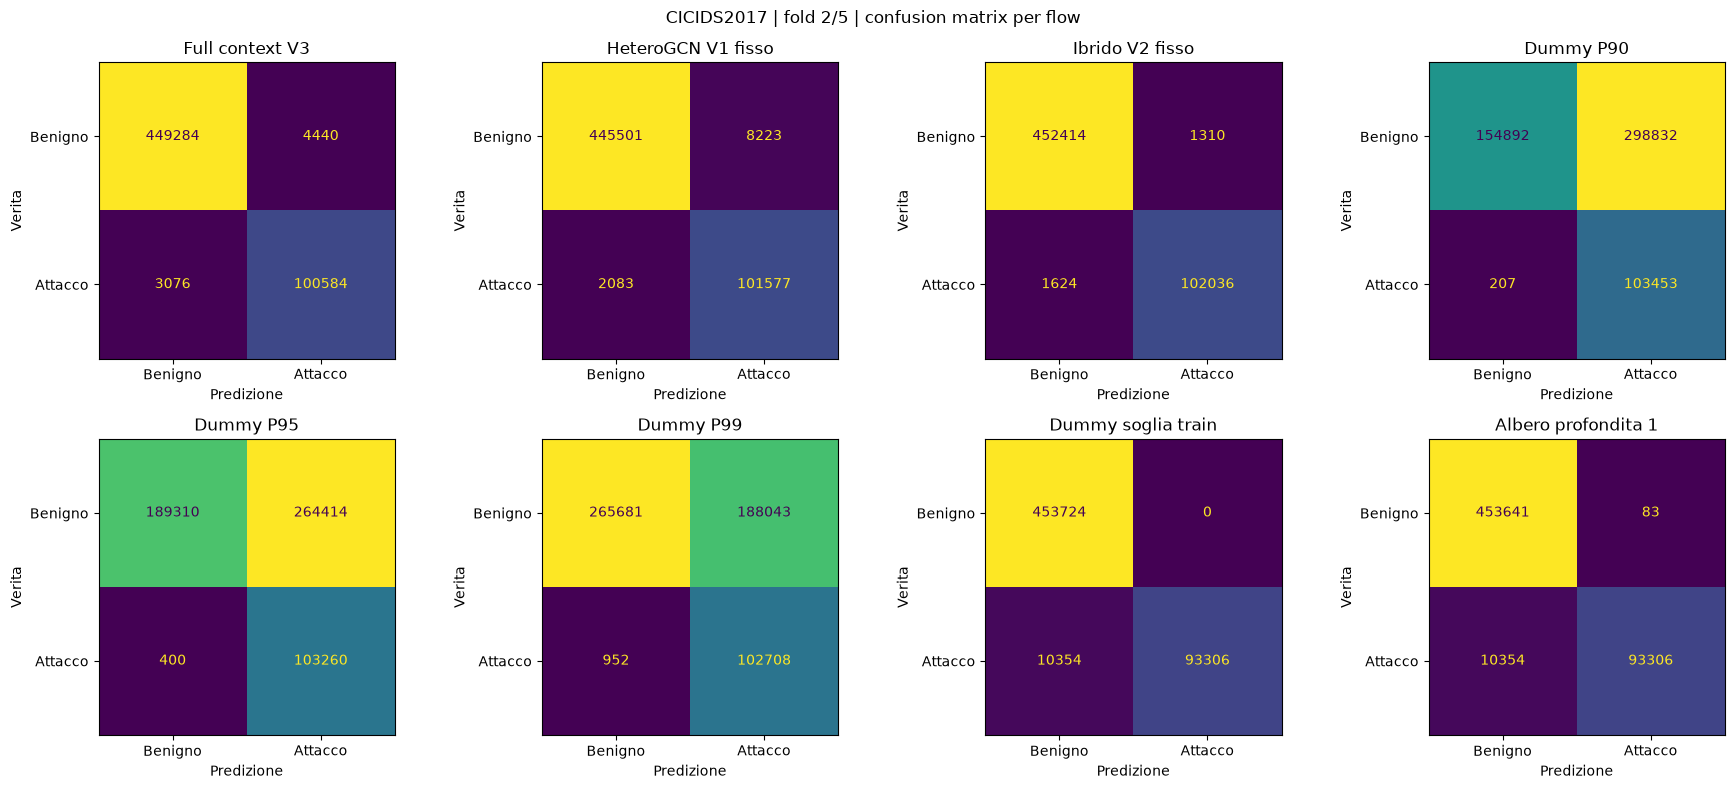

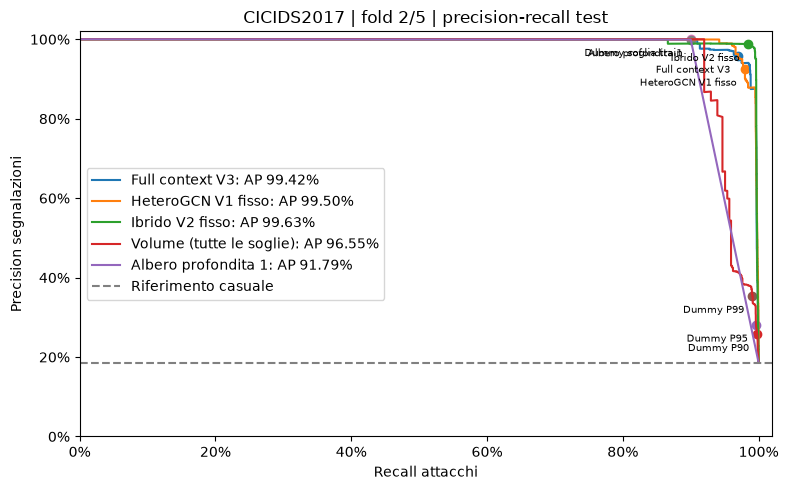

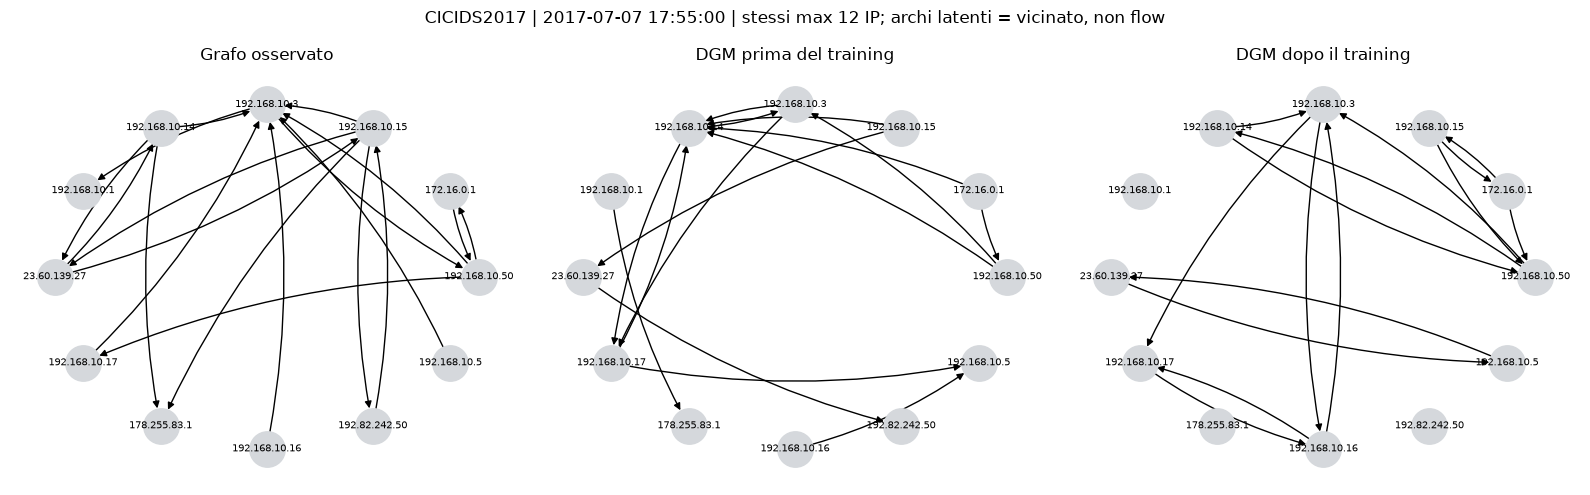

CICIDS2017 | test fold 3/5


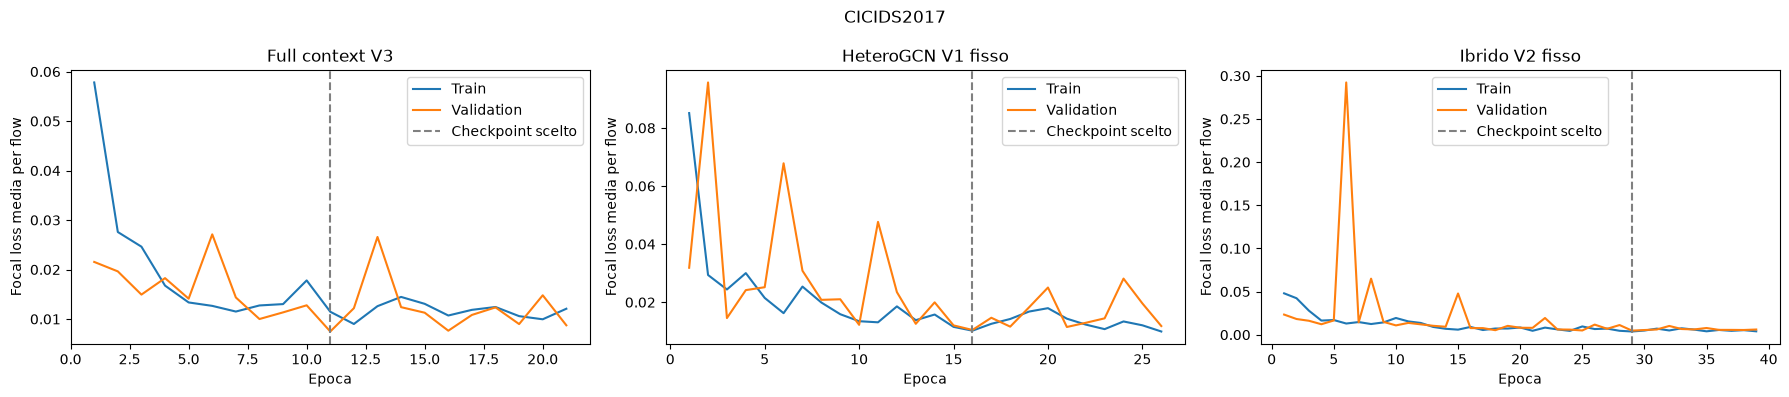

CICIDS2017 | percentili train: {'P90': 5.0, 'P95': 9.0, 'P99': 62.0} | soglia F1 train: 2048.0
Albero appreso sul train:
|--- destination_in <= 2278.50
|   |--- class: 0
|--- destination_in >  2278.50
|   |--- class: 1

Accuracy sempre benigno: 85.78%


CICIDS2017 | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,97.58,98.16,97.00,99.31,99.53,99.86,98.35,0.97,1394,2298
HeteroGCN V1 fisso,87.24,99.90,77.43,96.78,99.08,99.77,88.71,0.86,59,17285
Ibrido V2 fisso,97.97,98.64,97.30,99.43,99.61,99.86,98.54,0.98,1027,2068
Dummy P90,33.21,19.92,99.71,42.96,94.53,97.31,66.63,0.26,306927,225
Dummy P95,35.88,21.89,99.44,49.46,94.53,97.31,70.31,0.30,271713,427
Dummy P99,43.32,27.76,98.57,63.32,94.53,97.31,78.02,0.39,196405,1096
Dummy soglia train,93.74,100.00,88.21,98.32,94.53,97.31,94.11,0.93,0,9027
Albero profondita 1,93.68,99.88,88.21,98.31,89.78,94.10,94.10,0.93,81,9027


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,103425,227,17.29,13.22,90,197
HeteroGCN V1 fisso,103425,227,11.58,6.61,17,212
Ibrido V2 fisso,103425,227,21.79,22.47,190,176
Dummy P90,103425,227,1.77,40.09,9954,136
Dummy P95,103425,227,2.43,27.31,4813,165
Dummy P99,103425,227,6.67,18.50,991,185
Dummy soglia train,103425,227,5.98,3.08,0,220
Albero profondita 1,103425,227,5.47,3.08,22,220


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,99.70,99.99,99.78
Bot,0.00,0.00,6.40
DDoS,100.00,100.00,100.00
DoS GoldenEye,100.00,0.00,100.00
DoS Hulk,99.95,71.69,99.95
DoS Slowhttptest,94.22,94.22,3.45
DoS slowloris,100.00,72.97,100.00
FTP-Patator,92.37,0.00,77.47
Heartbleed,0.00,0.00,0.00


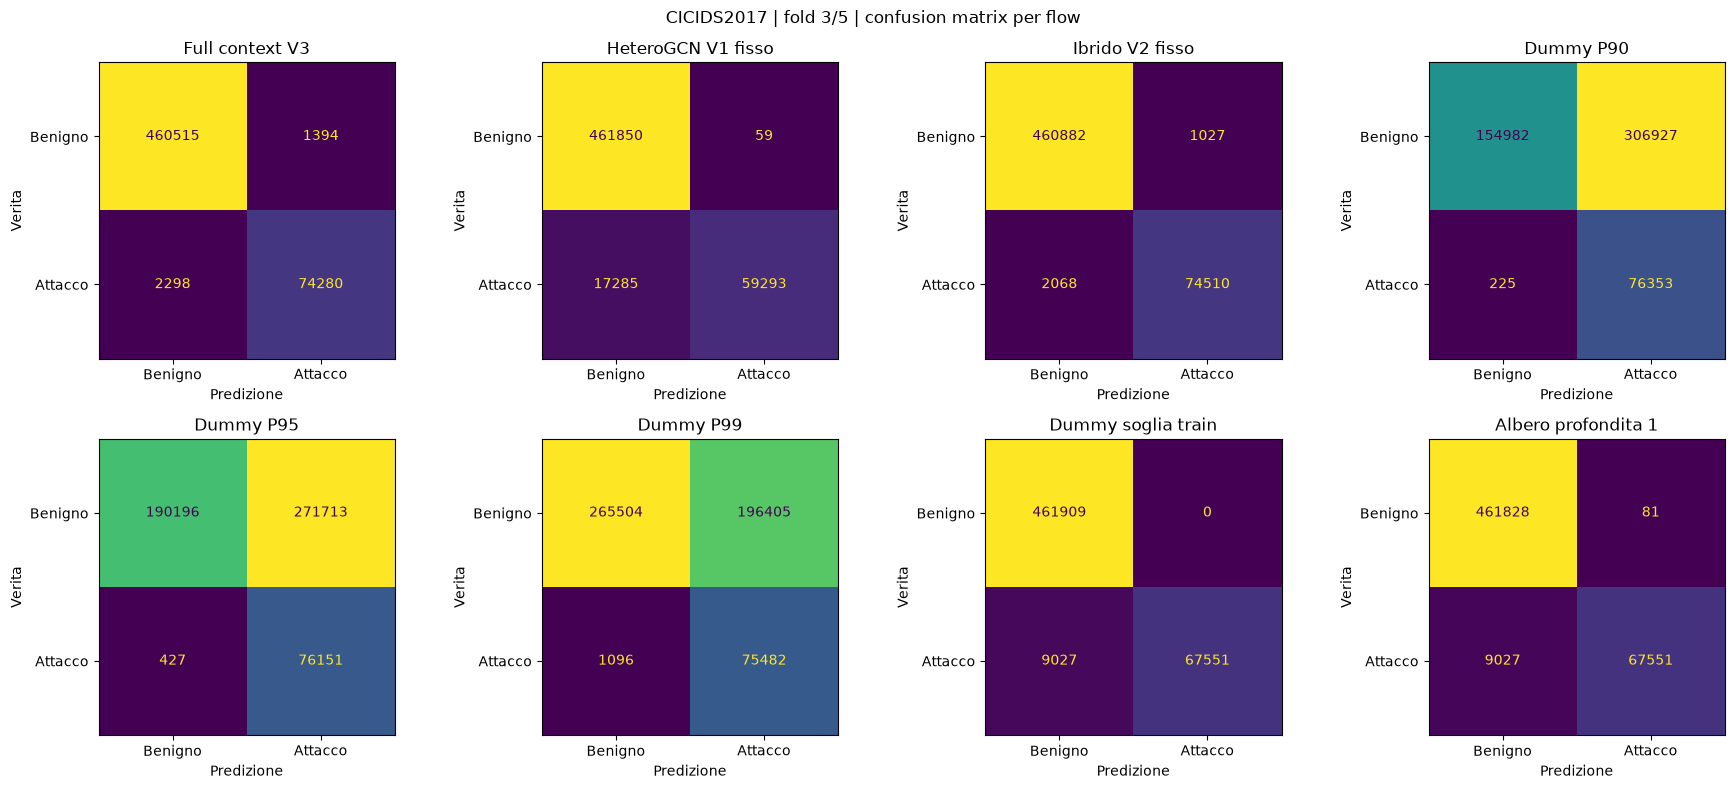

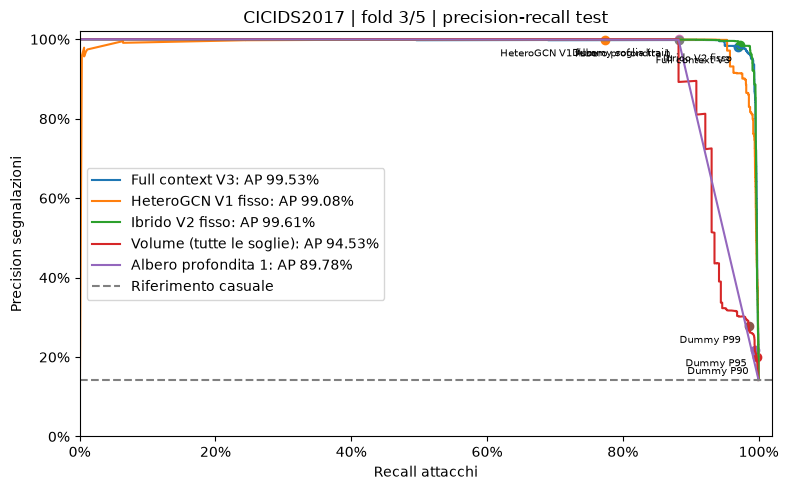

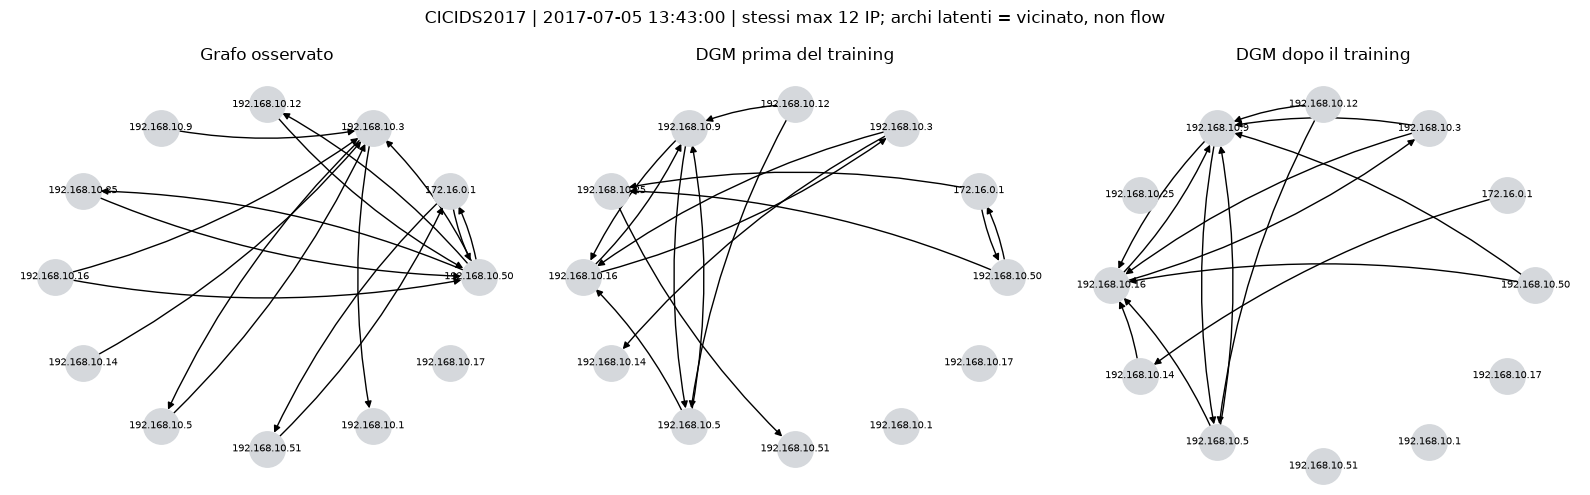

CICIDS2017 | test fold 4/5


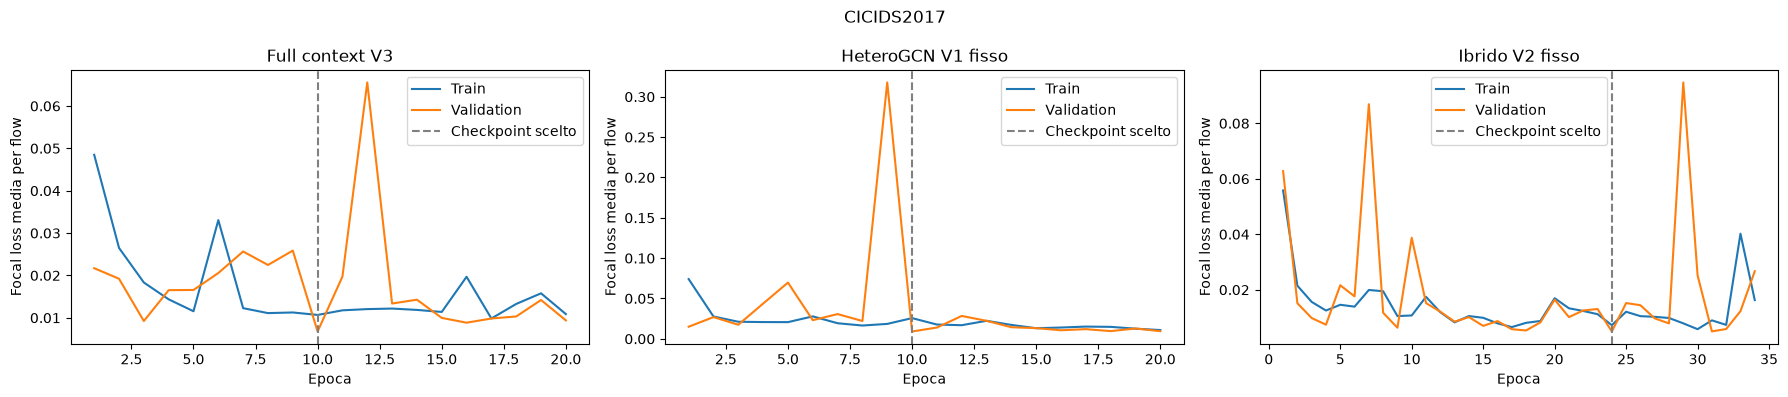

CICIDS2017 | percentili train: {'P90': 5.0, 'P95': 9.0, 'P99': 61.0} | soglia F1 train: 2438.0
Albero appreso sul train:
|--- destination_in <= 2246.00
|   |--- class: 0
|--- destination_in >  2246.00
|   |--- class: 1

Accuracy sempre benigno: 73.09%


CICIDS2017 | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,98.25,97.20,99.32,99.05,99.85,99.93,99.14,0.98,4840,1142
HeteroGCN V1 fisso,96.33,94.85,97.85,97.99,98.72,99.52,97.95,0.95,8991,3634
Ibrido V2 fisso,98.07,97.01,99.15,98.95,99.86,99.93,99.01,0.97,5172,1444
Dummy P90,52.41,35.53,99.88,51.19,98.49,98.92,66.57,0.34,306488,202
Dummy P95,55.34,38.28,99.81,56.64,98.49,98.92,70.27,0.39,272133,325
Dummy P99,62.75,45.83,99.46,68.21,98.49,98.92,78.08,0.51,198831,905
Dummy soglia train,97.97,100.00,96.03,98.93,98.49,98.92,98.02,0.97,0,6713
Albero profondita 1,97.94,99.92,96.03,98.91,97.02,98.00,98.00,0.97,127,6713


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,101833,220,16.73,20.45,273,175
HeteroGCN V1 fisso,101833,220,18.92,12.73,48,192
Ibrido V2 fisso,101833,220,15.48,23.64,400,168
Dummy P90,101833,220,1.60,36.82,9820,139
Dummy P95,101833,220,2.49,28.64,4771,157
Dummy P99,101833,220,7.15,20.91,1020,174
Dummy soglia train,101833,220,12.77,6.82,0,205
Albero profondita 1,101833,220,11.19,6.82,33,205


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,98.95,98.04,98.87
Bot,0.00,0.00,8.88
DDoS,99.99,99.99,99.99
DoS GoldenEye,100.00,100.00,100.00
DoS Hulk,100.00,100.00,100.00
DoS Slowhttptest,0.00,0.00,98.70
DoS slowloris,92.25,23.58,74.53
FTP-Patator,92.44,57.74,84.21
Heartbleed,0.00,0.00,0.00


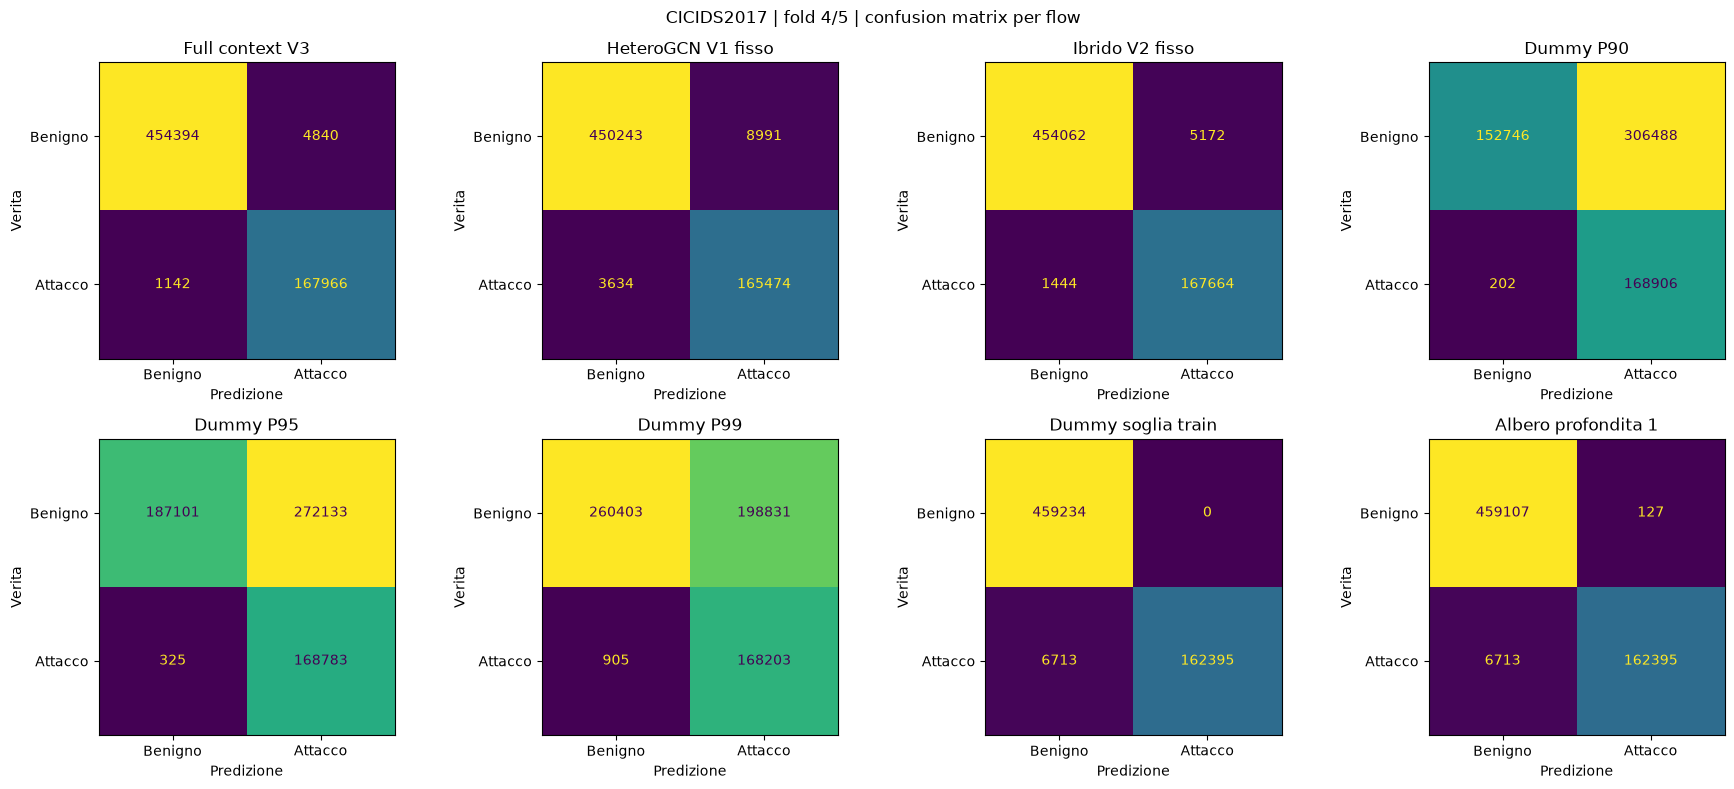

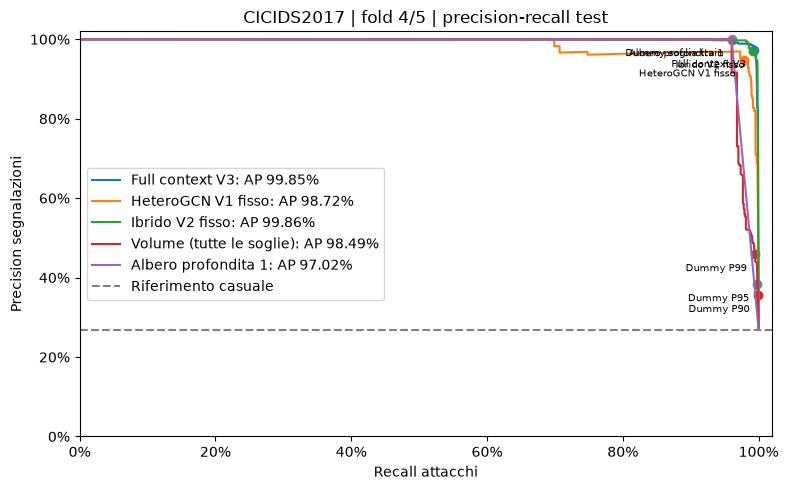

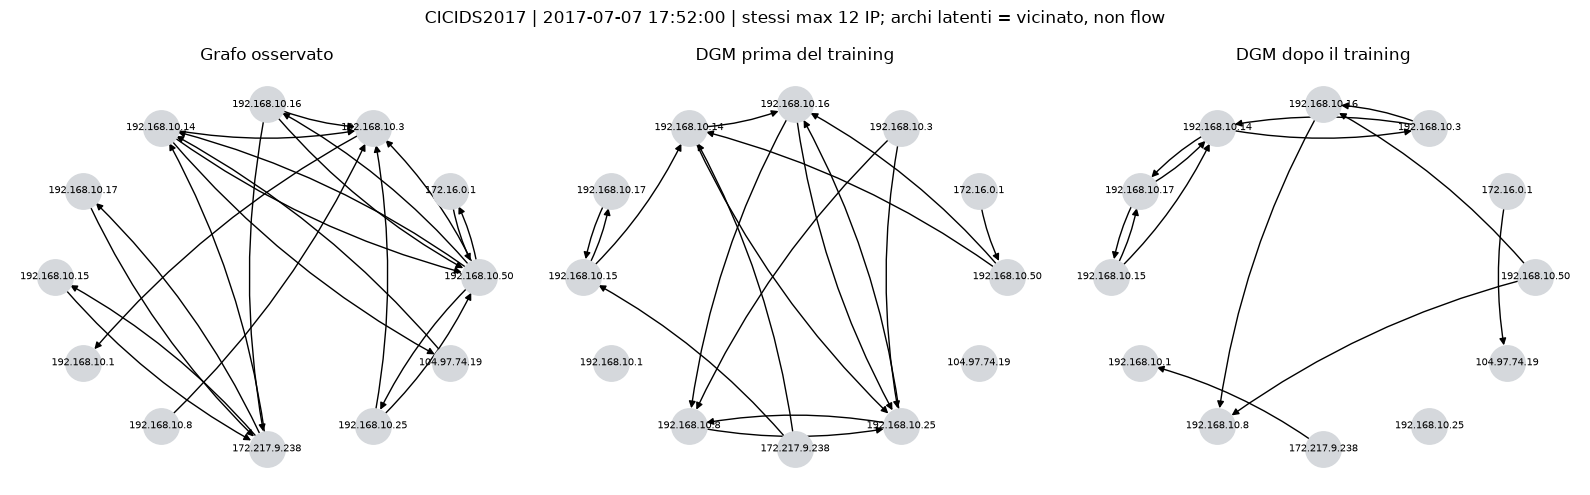

CICIDS2017 | test fold 5/5


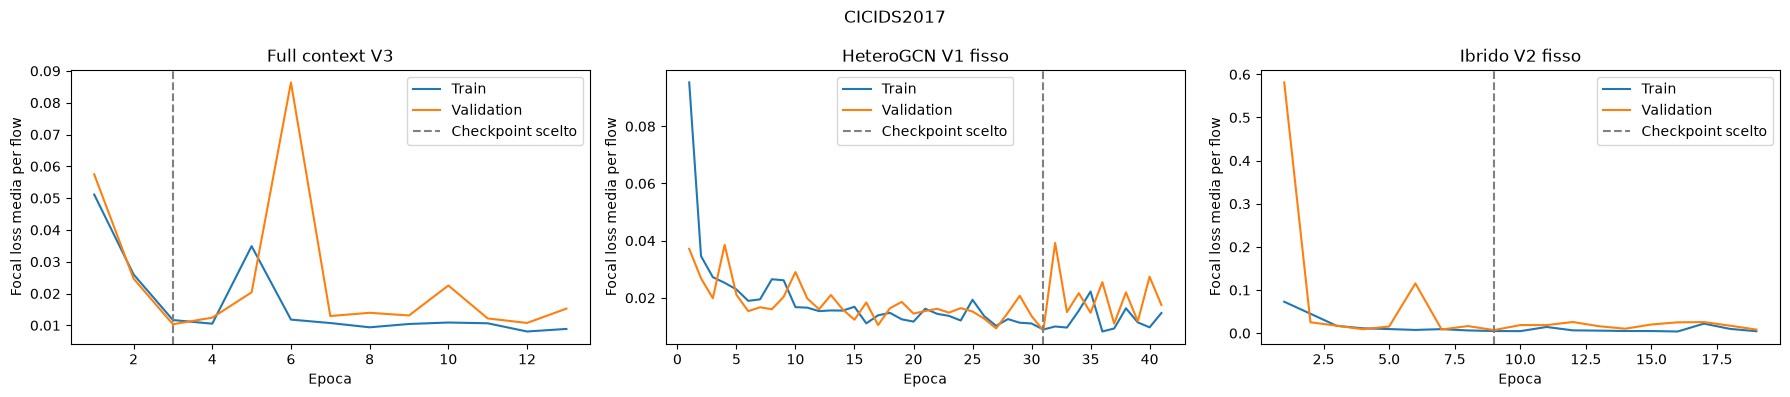

CICIDS2017 | percentili train: {'P90': 5.0, 'P95': 9.0, 'P99': 63.0} | soglia F1 train: 3957.0
Albero appreso sul train:
|--- destination_in <= 3040.00
|   |--- class: 0
|--- destination_in >  3040.00
|   |--- class: 1

Accuracy sempre benigno: 78.75%


CICIDS2017 | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,96.51,96.91,96.11,98.52,99.36,99.74,97.64,0.96,3782,4797
HeteroGCN V1 fisso,97.99,99.57,96.46,99.16,99.59,99.85,98.17,0.97,516,4368
Ibrido V2 fisso,96.84,96.90,96.79,98.66,99.51,99.85,97.98,0.96,3823,3961
Dummy P90,44.94,28.99,99.86,48.01,97.14,98.35,66.94,0.31,301621,177
Dummy P95,48.06,31.66,99.69,54.22,97.14,98.35,70.82,0.36,265356,386
Dummy P99,56.82,39.80,99.23,67.95,97.14,98.35,79.37,0.48,185113,944
Dummy soglia train,93.54,100.00,87.86,97.42,97.14,98.35,93.93,0.92,0,14978
Albero profondita 1,93.49,99.90,87.86,97.40,90.35,93.92,93.92,0.92,104,14978


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,104234,214,16.72,11.68,60,189
HeteroGCN V1 fisso,104234,214,15.18,10.75,66,191
Ibrido V2 fisso,104234,214,21.93,19.16,119,173
Dummy P90,104234,214,1.87,45.79,10166,116
Dummy P95,104234,214,2.60,31.31,4870,147
Dummy P99,104234,214,8.26,23.36,947,164
Dummy soglia train,104234,214,8.07,4.21,0,205
Albero profondita 1,104234,214,7.23,4.21,26,205


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,99.17,99.89,99.16
Bot,0.00,0.00,1.55
DDoS,100.00,100.00,100.00
DoS GoldenEye,77.66,100.00,61.77
DoS Hulk,100.00,99.35,99.75
DoS Slowhttptest,91.35,91.35,93.94
DoS slowloris,0.00,0.00,100.00
FTP-Patator,50.26,0.00,68.63
Infiltration,0.00,0.00,0.00


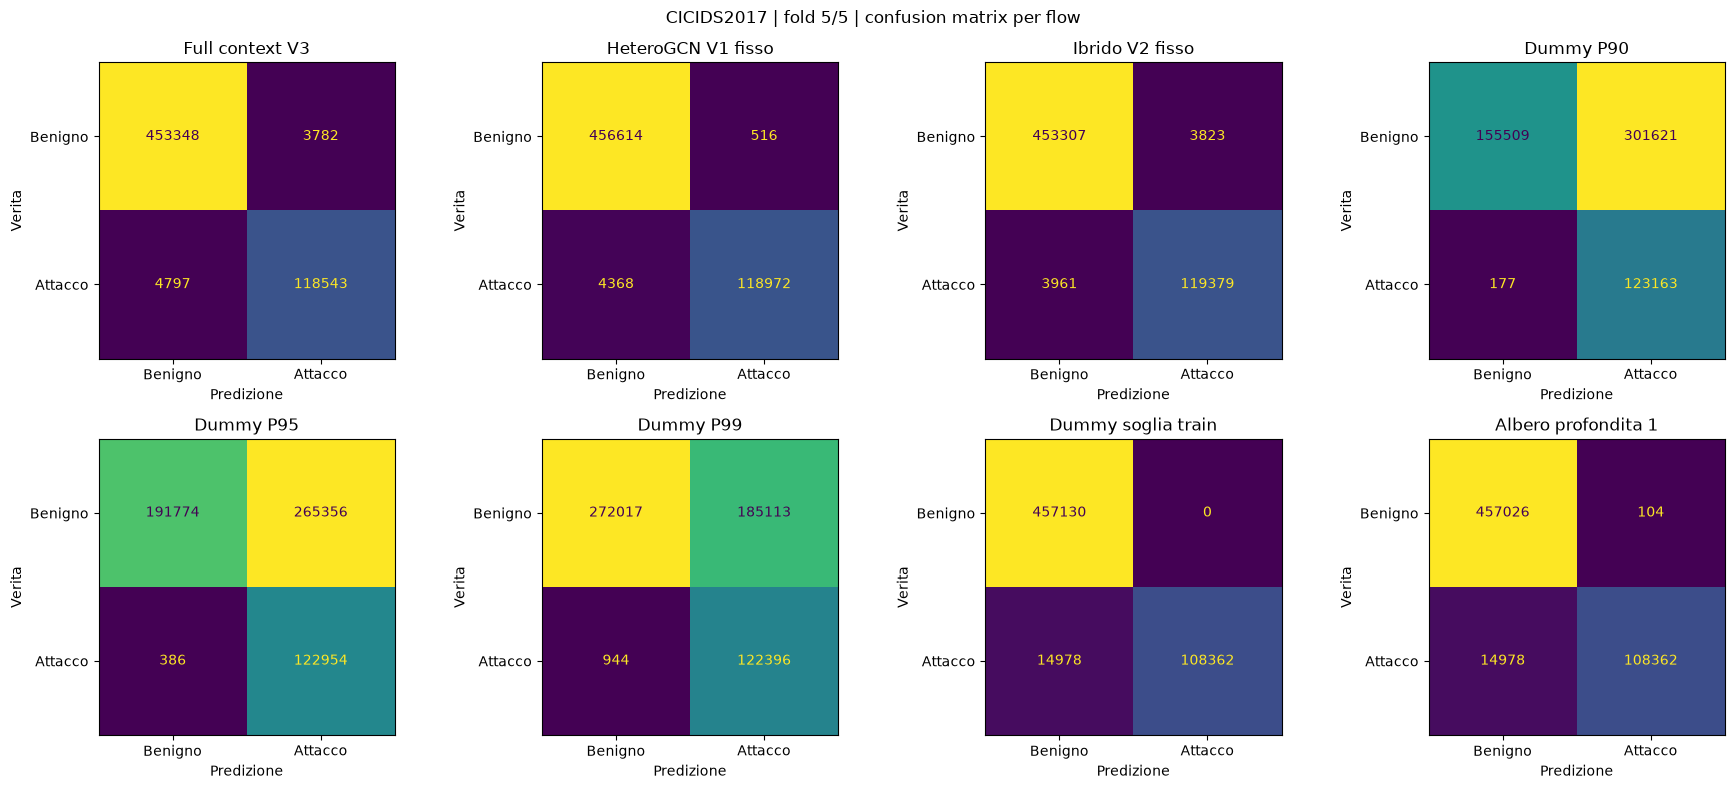

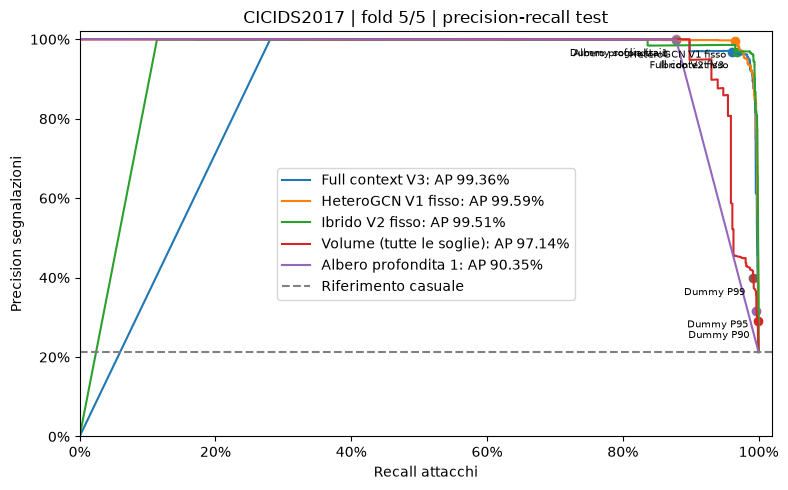

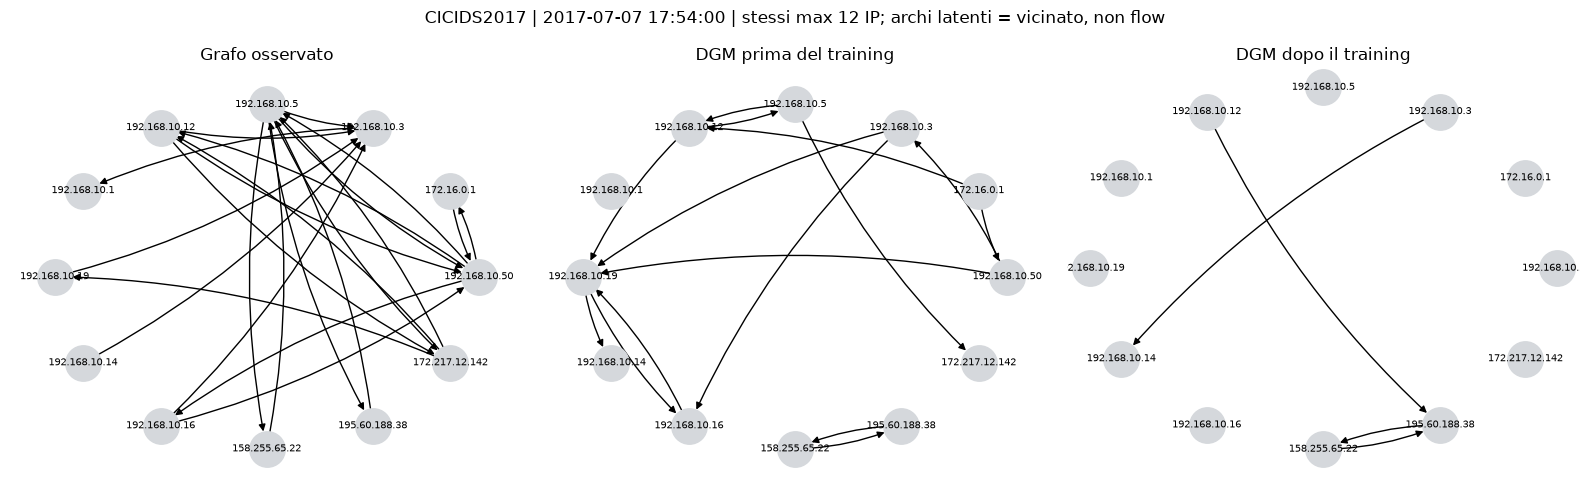

CICToNIoT | test fold 1/5


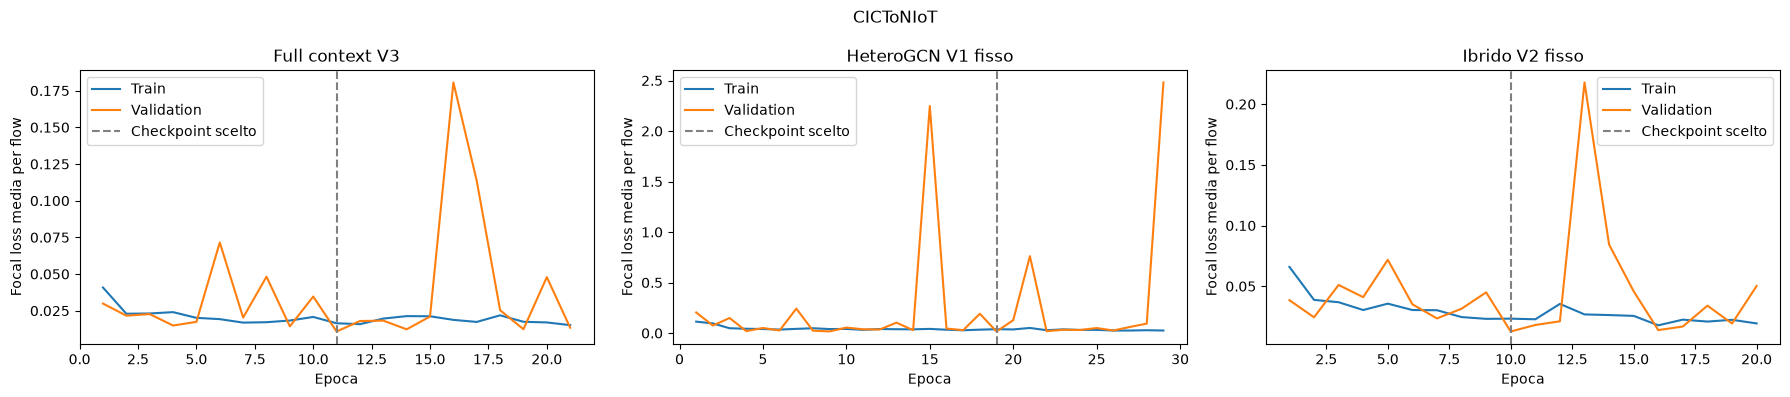

CICToNIoT | percentili train: {'P90': 1.0, 'P95': 2.0, 'P99': 249.0} | soglia F1 train: 54.0
Albero appreso sul train:
|--- source_out <= 1510.00
|   |--- class: 0
|--- source_out >  1510.00
|   |--- class: 1

Accuracy sempre benigno: 45.42%


CICToNIoT | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,98.74,97.98,99.51,98.61,98.40,98.94,98.52,0.97,12925,3099
HeteroGCN V1 fisso,98.57,97.96,99.18,98.43,98.03,98.83,98.35,0.97,12987,5137
Ibrido V2 fisso,98.20,97.91,98.50,98.03,98.13,98.97,97.98,0.96,13262,9481
Dummy P90,76.55,62.02,99.97,66.57,79.65,75.32,63.21,0.40,385806,219
Dummy P95,76.70,62.22,99.94,66.85,79.65,75.32,63.52,0.41,382334,409
Dummy P99,75.62,64.43,91.51,67.79,79.65,75.32,65.40,0.37,318436,53496
Dummy soglia train,77.23,63.44,98.67,68.25,79.65,75.32,65.18,0.42,358272,8398
Albero profondita 1,91.29,86.98,96.06,90.00,85.70,89.39,89.39,0.80,90623,24841


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,145321,2081,75.00,90.68,1064,194
HeteroGCN V1 fisso,145321,2081,77.11,80.87,601,398
Ibrido V2 fisso,145321,2081,74.51,92.50,1161,156
Dummy P90,145321,2081,43.97,89.48,4527,219
Dummy P95,145321,2081,53.23,84.91,2791,314
Dummy P99,145321,2081,43.78,34.60,488,1361
Dummy soglia train,145321,2081,53.55,49.83,755,1044
Albero profondita 1,145321,2081,72.56,61.36,162,804


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,97.54,97.52,97.47
backdoor,94.61,91.88,95.81
ddos,30.00,30.00,0.00
dos,26.09,26.09,0.00
injection,99.79,99.34,97.32
mitm,25.00,20.45,11.36
password,99.42,99.23,98.23
ransomware,2.62,6.27,0.00
scanning,98.84,99.81,99.31


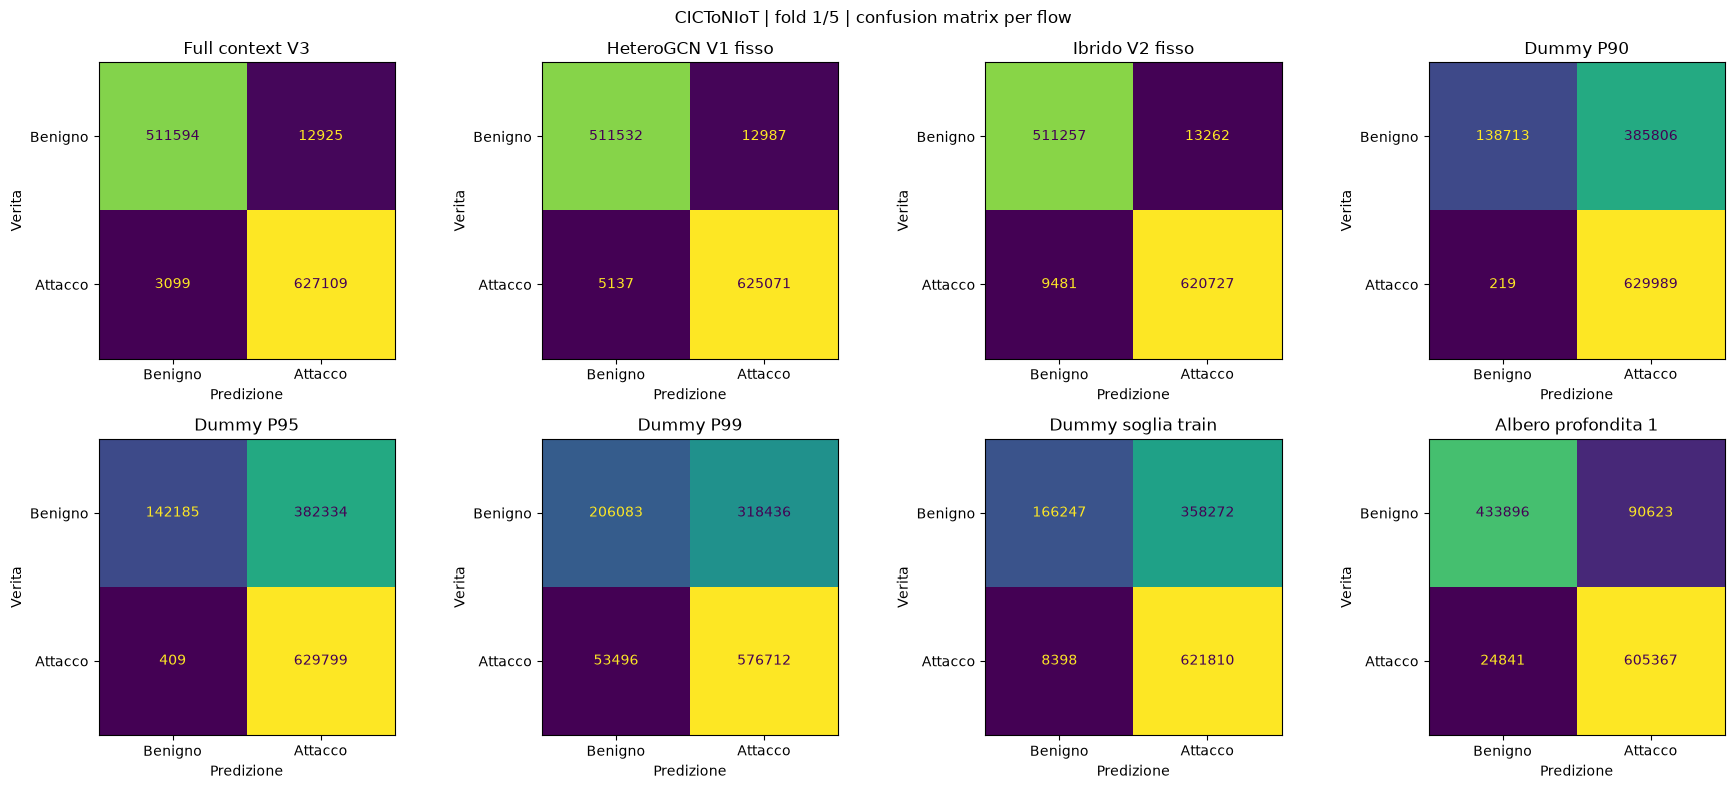

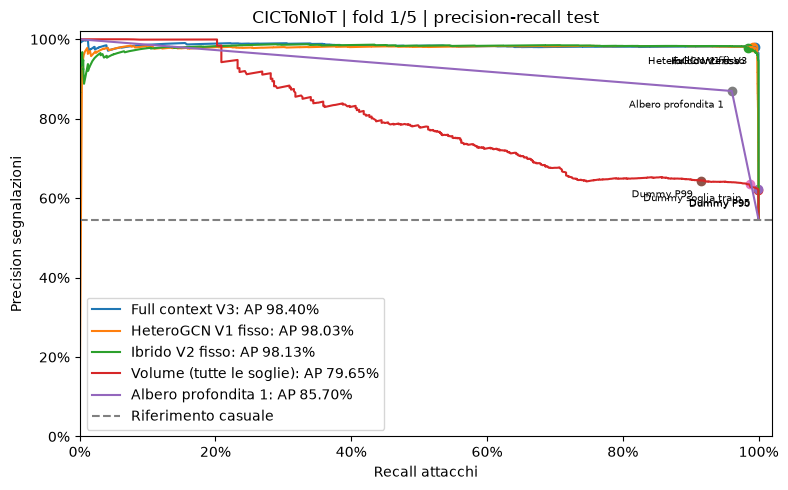

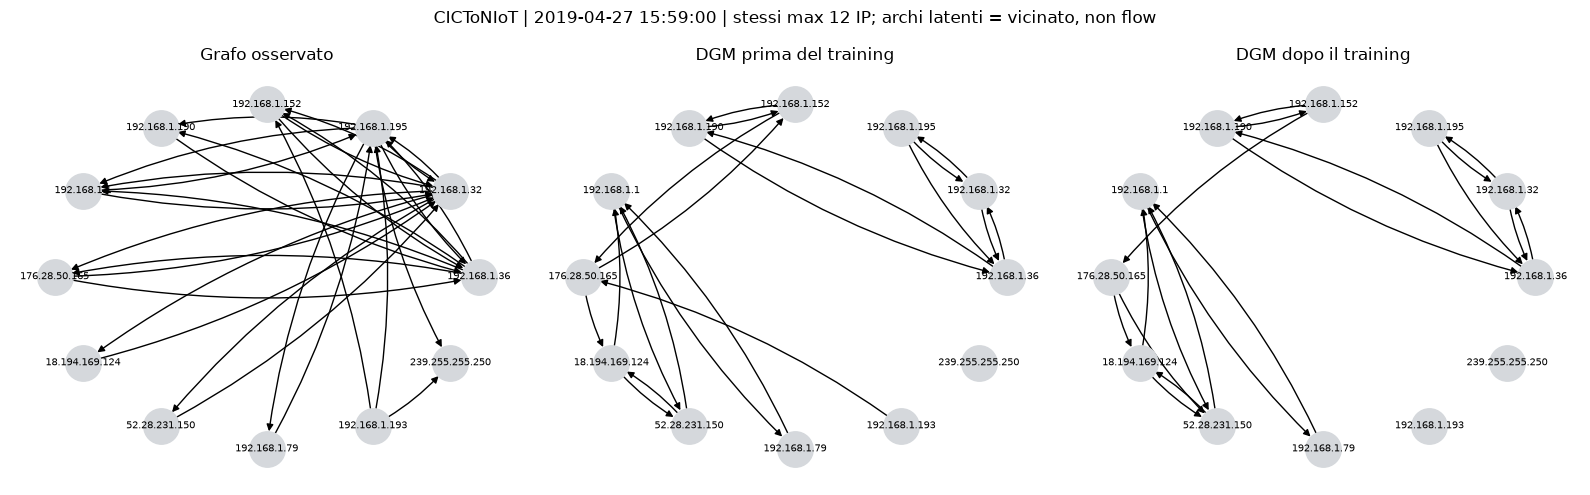

CICToNIoT | test fold 2/5


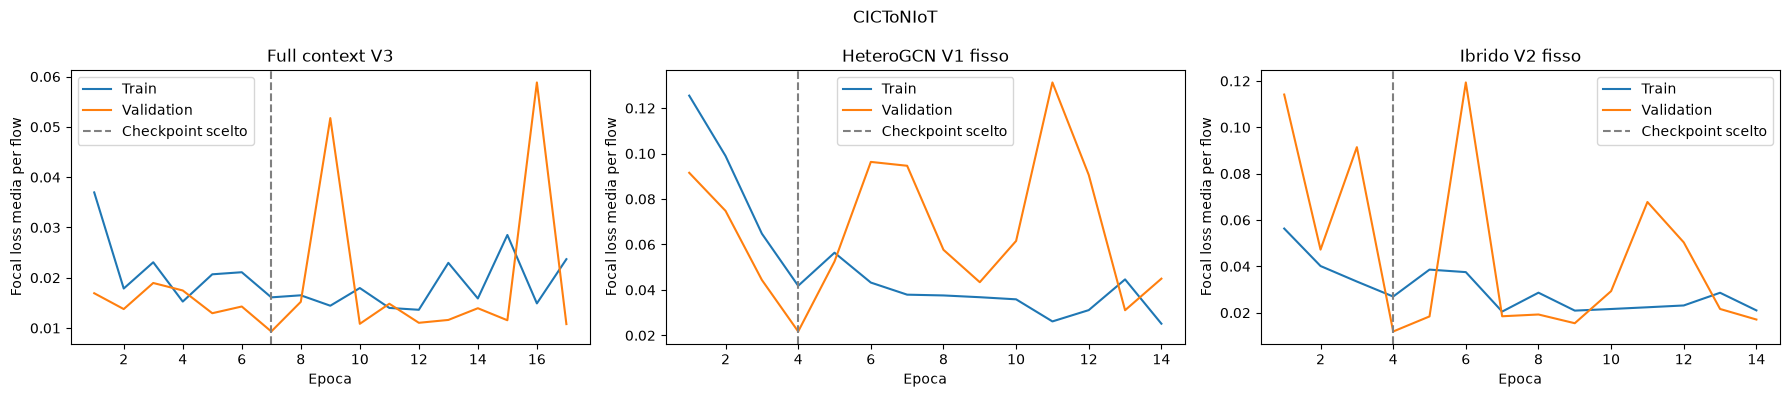

CICToNIoT | percentili train: {'P90': 1.0, 'P95': 2.0, 'P99': 232.0} | soglia F1 train: 54.0
Albero appreso sul train:
|--- source_out <= 1515.00
|   |--- class: 0
|--- source_out >  1515.00
|   |--- class: 1

Accuracy sempre benigno: 48.45%


CICToNIoT | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,98.34,96.93,99.78,98.26,98.57,99.03,98.21,0.97,16862,1148
HeteroGCN V1 fisso,97.50,96.51,98.51,97.40,98.28,98.67,97.36,0.95,18961,7934
Ibrido V2 fisso,94.50,89.70,99.84,94.01,96.65,97.54,93.82,0.89,61120,859
Dummy P90,72.70,57.12,99.96,61.31,61.46,67.04,60.07,0.34,399912,196
Dummy P95,72.87,57.34,99.93,61.64,61.46,67.04,60.42,0.34,396270,354
Dummy P99,72.01,58.95,92.53,62.93,61.46,67.04,61.99,0.30,343443,39841
Dummy soglia train,73.25,58.33,98.40,62.94,61.46,67.04,61.81,0.35,374641,8515
Albero profondita 1,87.79,81.11,95.68,86.29,79.83,85.99,85.99,0.74,118772,23042


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,107490,1932,84.23,89.29,439,207
HeteroGCN V1 fisso,107490,1932,76.02,78.67,547,412
Ibrido V2 fisso,107490,1932,81.01,91.61,668,162
Dummy P90,107490,1932,42.79,89.86,4446,196
Dummy P95,107490,1932,53.33,85.77,2625,275
Dummy P99,107490,1932,42.83,33.85,468,1278
Dummy soglia train,107490,1932,50.97,46.33,685,1037
Albero profondita 1,107490,1932,70.10,57.71,134,817


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,96.63,96.22,87.80
backdoor,87.30,90.81,92.71
ddos,0.00,0.00,22.22
dos,0.00,0.00,23.08
injection,99.97,99.05,99.96
mitm,5.36,0.00,23.21
password,99.96,99.68,99.96
ransomware,0.00,1.85,0.00
scanning,99.86,99.76,99.83


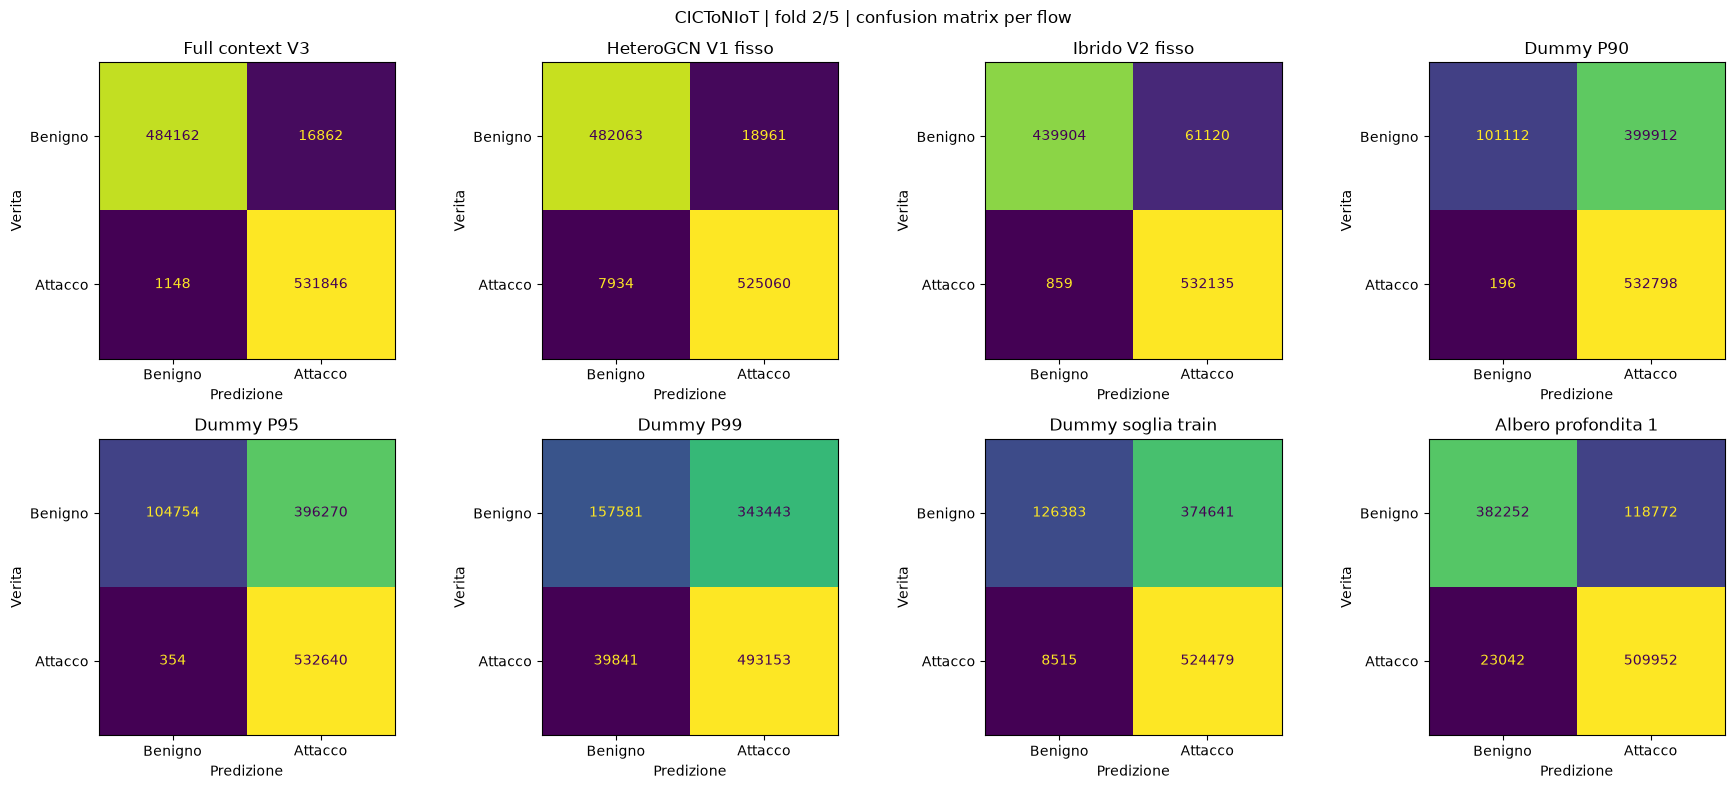

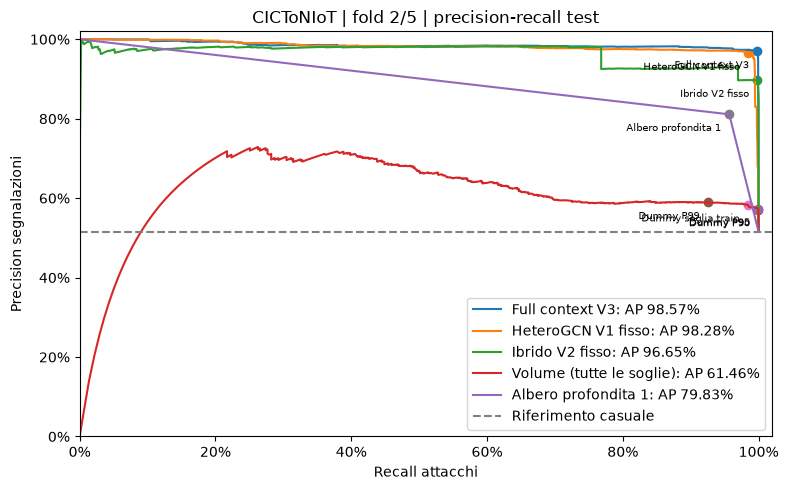

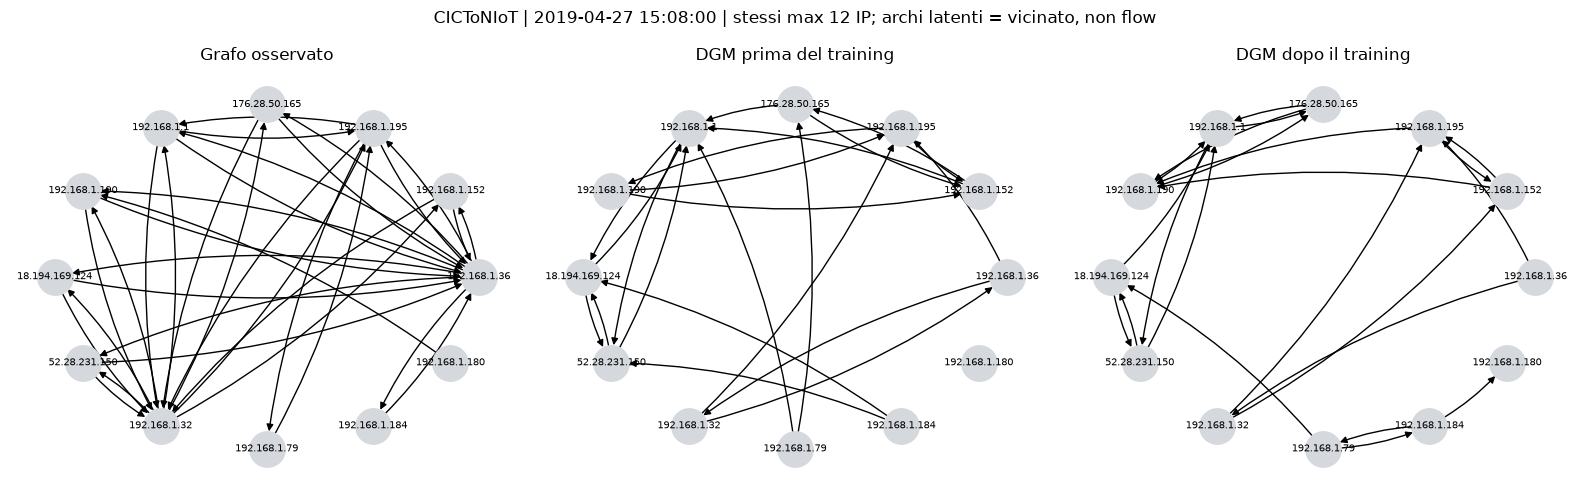

CICToNIoT | test fold 3/5


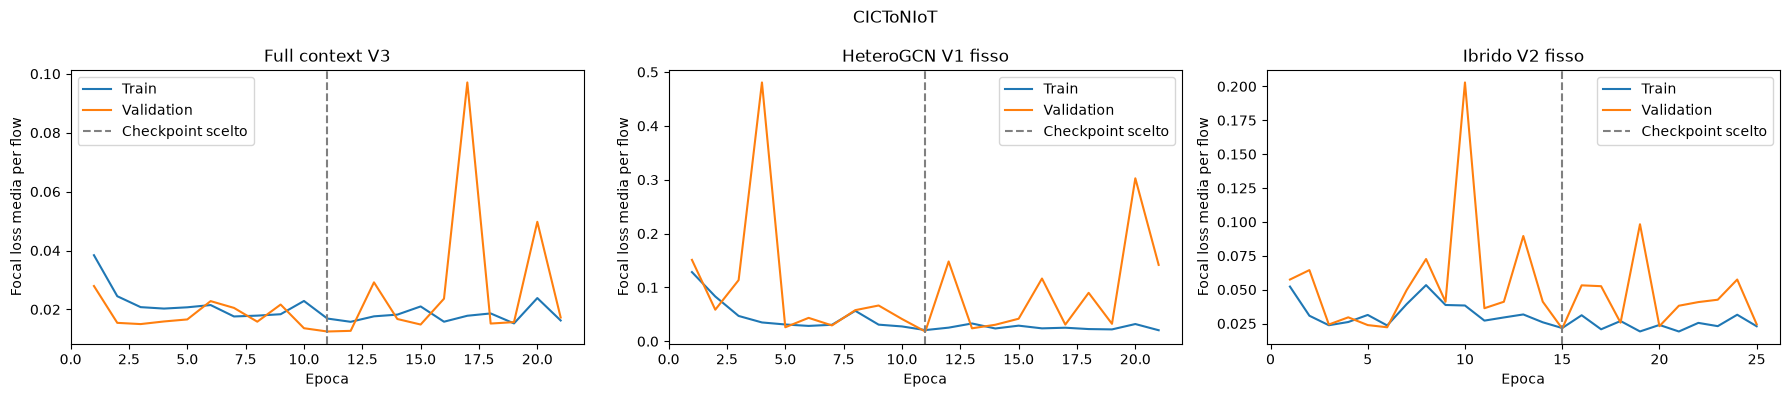

CICToNIoT | percentili train: {'P90': 1.0, 'P95': 1.0, 'P99': 185.0} | soglia F1 train: 54.0
Albero appreso sul train:
|--- source_out <= 1511.50
|   |--- class: 0
|--- source_out >  1511.50
|   |--- class: 1

Accuracy sempre benigno: 46.41%


CICToNIoT | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,95.69,92.49,99.12,95.22,98.38,98.63,94.92,0.91,52128,5673
HeteroGCN V1 fisso,94.97,91.23,99.03,94.38,95.78,97.32,94.02,0.89,61688,6257
Ibrido V2 fisso,91.99,85.79,99.16,90.74,75.27,86.15,90.09,0.82,106429,5465
Dummy P90,72.32,56.65,99.96,58.99,56.08,59.45,55.82,0.26,495542,235
Dummy P95,72.32,56.65,99.96,58.99,56.08,59.45,55.82,0.26,495542,235
Dummy P99,72.34,58.31,95.27,60.96,56.08,59.45,58.31,0.25,441353,30613
Dummy soglia train,72.89,57.79,98.65,60.67,56.08,59.45,57.74,0.28,466674,8740
Albero profondita 1,84.78,75.93,95.97,81.54,75.03,80.42,80.42,0.65,197055,26121


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,72582,2123,81.18,84.83,513,322
HeteroGCN V1 fisso,72582,2123,57.55,89.50,2580,223
Ibrido V2 fisso,72582,2123,71.06,92.23,1430,165
Dummy P90,72582,2123,42.42,88.93,4890,235
Dummy P95,72582,2123,42.42,88.93,4890,235
Dummy P99,72582,2123,47.97,40.60,609,1261
Dummy soglia train,72582,2123,52.54,49.60,832,1070
Albero profondita 1,72582,2123,63.78,61.47,664,818


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,90.71,89.01,81.03
backdoor,78.70,93.25,93.90
ddos,0.00,50.00,11.11
dos,0.00,53.33,10.00
injection,99.96,99.93,100.00
mitm,0.00,35.06,10.39
password,99.96,99.85,99.91
ransomware,17.70,18.60,17.57
scanning,99.89,99.94,99.79


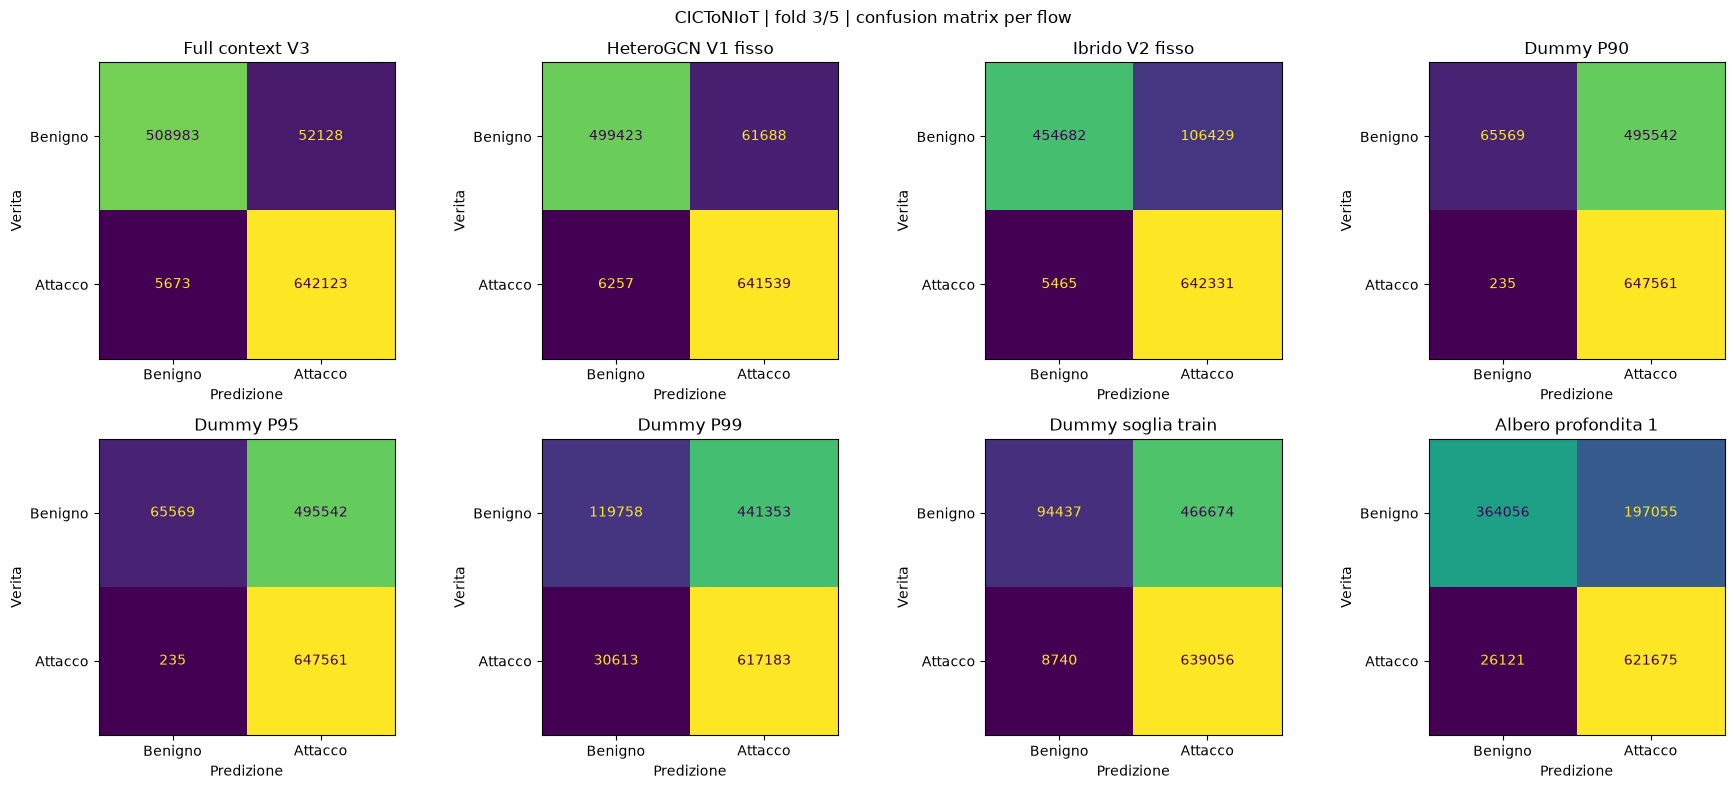

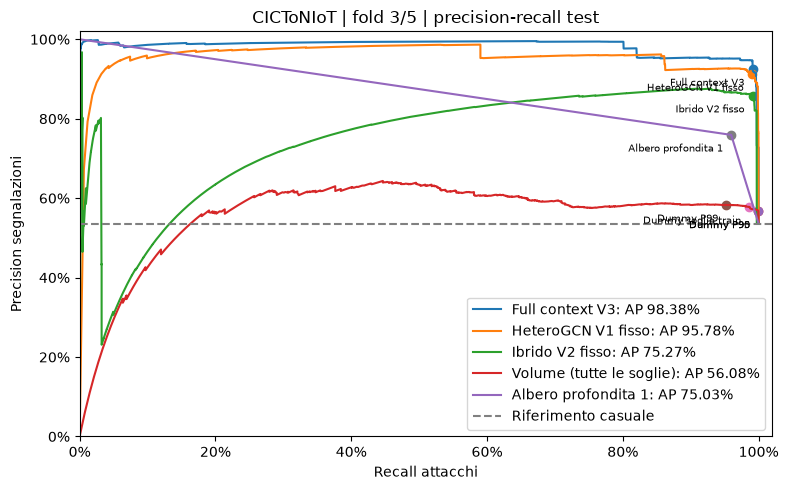

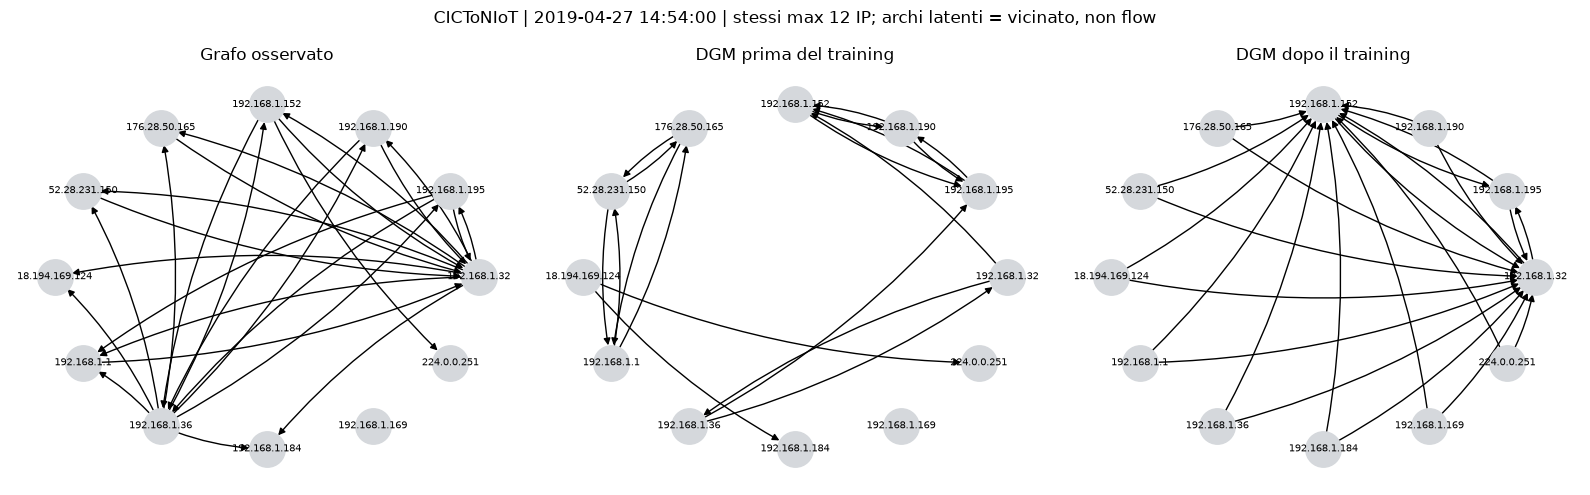

CICToNIoT | test fold 4/5


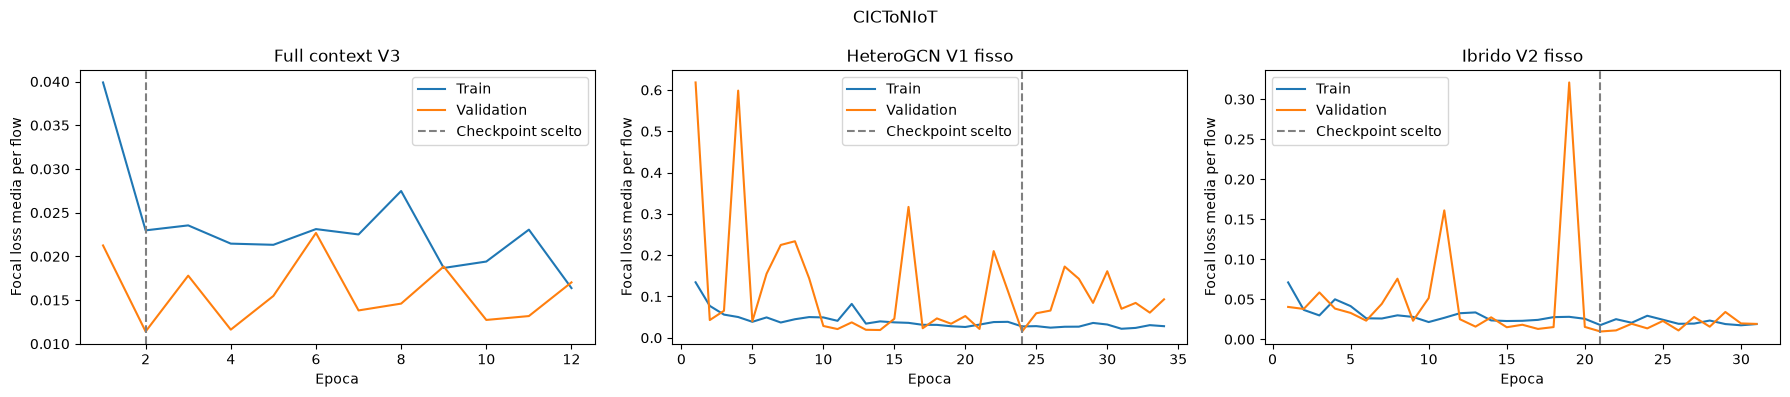

CICToNIoT | percentili train: {'P90': 1.0, 'P95': 2.0, 'P99': 241.92999999999302} | soglia F1 train: 54.0
Albero appreso sul train:
|--- source_out <= 1473.50
|   |--- class: 0
|--- source_out >  1473.50
|   |--- class: 1

Accuracy sempre benigno: 44.52%


CICToNIoT | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,98.93,98.41,99.45,98.80,99.23,99.44,98.72,0.98,10377,3550
HeteroGCN V1 fisso,98.59,98.82,98.36,98.44,99.37,99.51,98.45,0.97,7579,10602
Ibrido V2 fisso,98.93,98.68,99.19,98.81,99.12,99.46,98.77,0.98,8555,5228
Dummy P90,76.38,61.81,99.96,65.71,78.72,73.68,61.49,0.38,398355,266
Dummy P95,76.53,62.01,99.92,65.99,78.72,73.68,61.82,0.38,394824,521
Dummy P99,75.61,64.04,92.28,66.96,78.72,73.68,63.85,0.34,334234,49790
Dummy soglia train,76.98,63.12,98.66,67.27,78.72,73.68,63.41,0.39,371822,8655
Albero profondita 1,91.76,87.09,96.96,90.34,86.13,89.53,89.53,0.81,92684,19598


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,125909,2156,68.78,91.19,1595,190
HeteroGCN V1 fisso,125909,2156,59.12,53.06,570,1012
Ibrido V2 fisso,125909,2156,77.03,84.32,746,338
Dummy P90,125909,2156,43.95,87.66,4555,266
Dummy P95,125909,2156,52.53,81.73,2790,394
Dummy P99,125909,2156,43.68,34.83,532,1405
Dummy soglia train,125909,2156,52.42,48.52,789,1110
Albero profondita 1,125909,2156,72.75,62.34,195,812


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,97.99,98.54,98.35
backdoor,88.31,0.02,68.35
ddos,51.72,44.83,0.00
dos,10.34,0.00,0.00
injection,99.93,99.38,99.93
mitm,74.65,42.25,7.98
password,99.94,99.49,99.93
ransomware,32.86,3.27,0.20
scanning,99.83,96.62,99.82


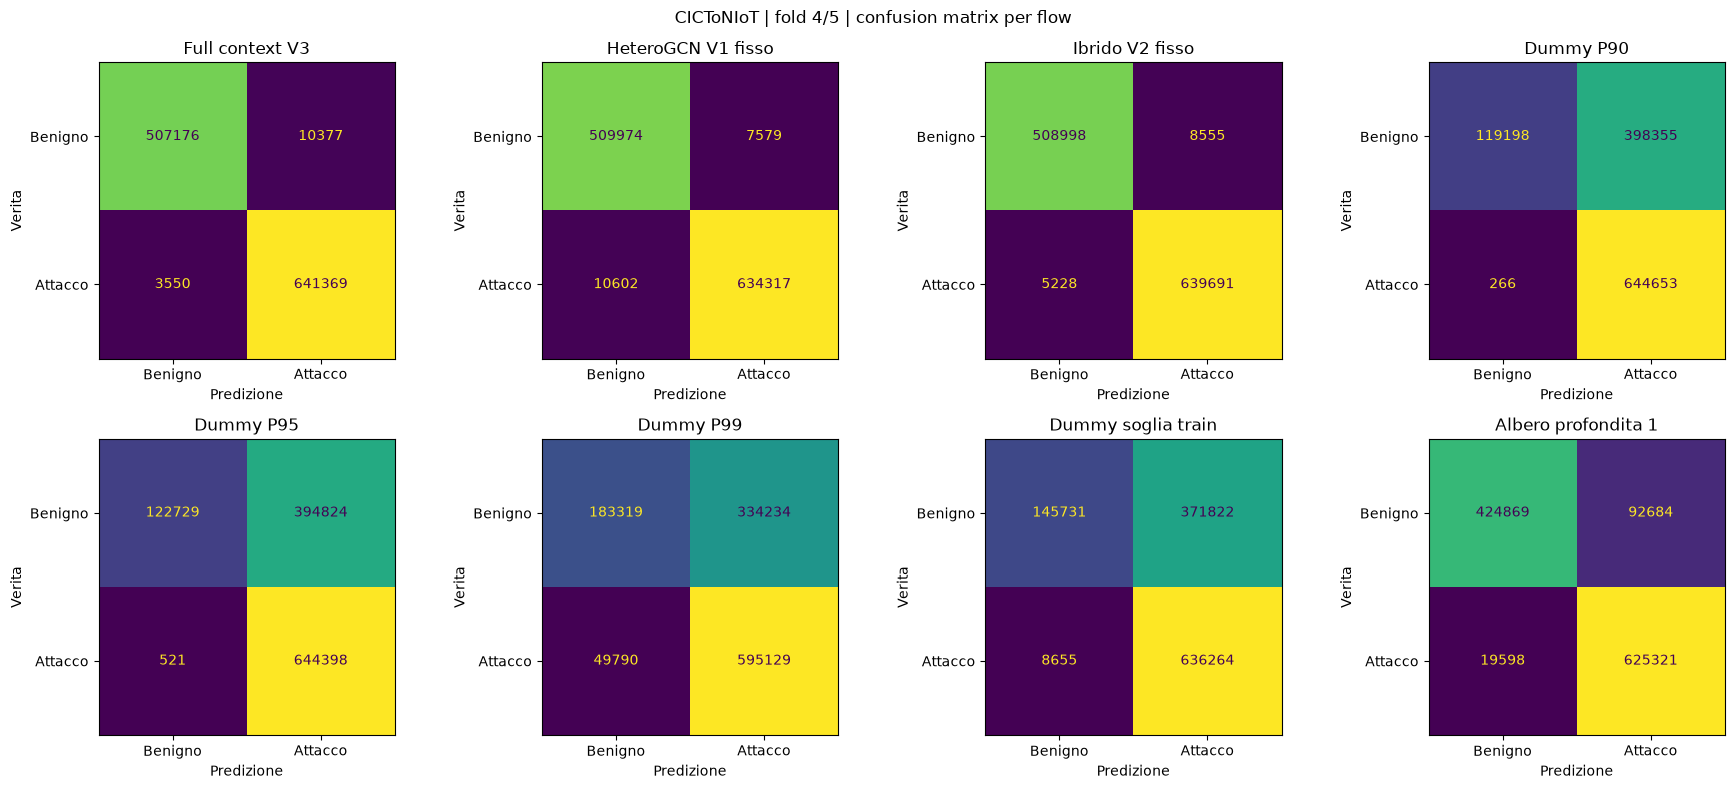

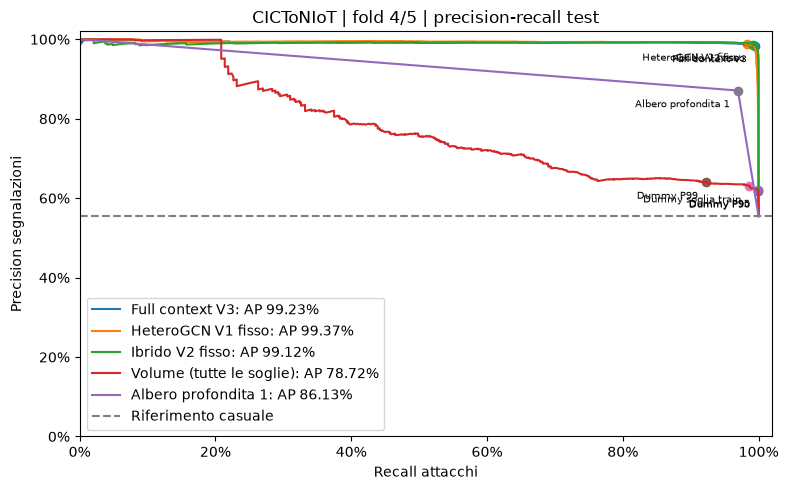

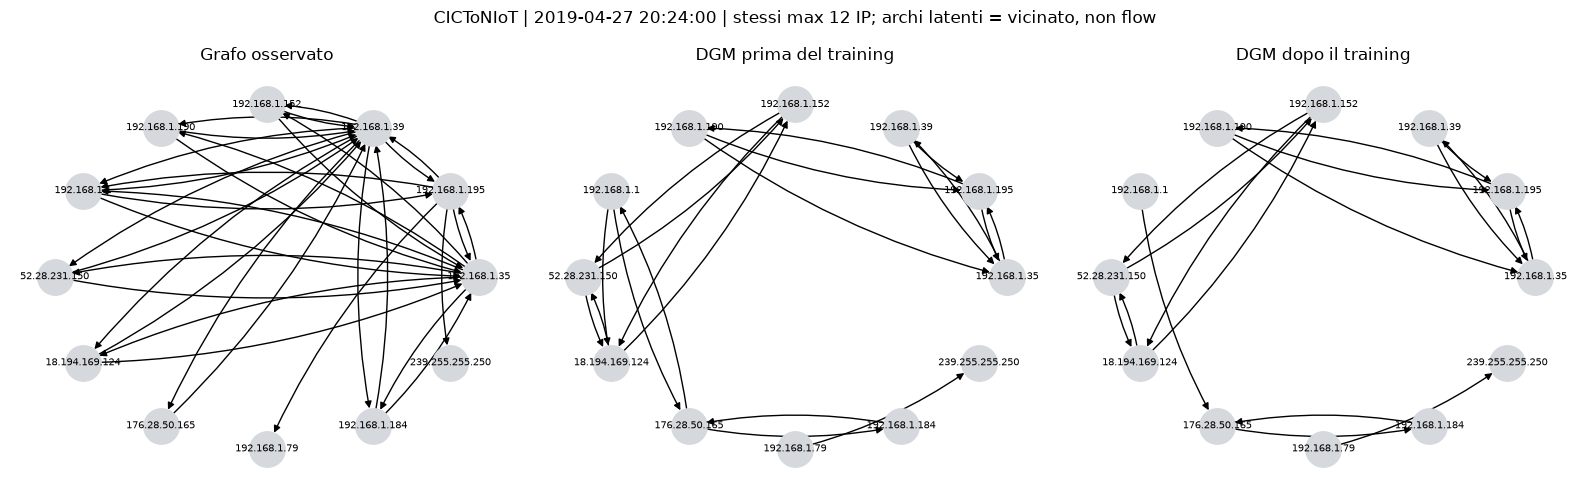

CICToNIoT | test fold 5/5


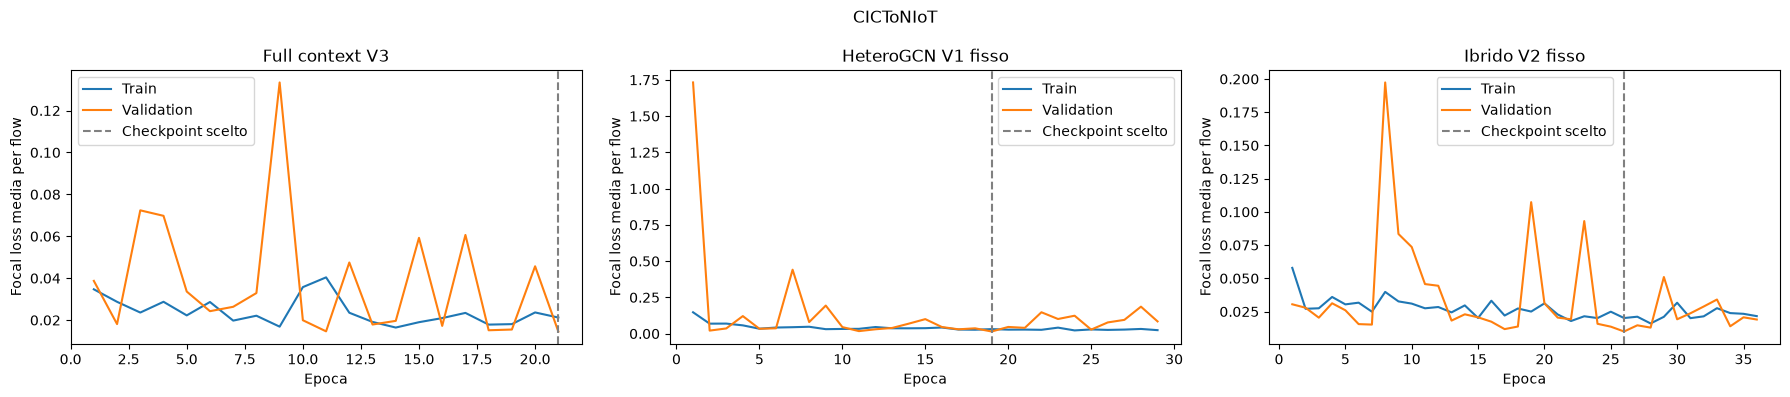

CICToNIoT | percentili train: {'P90': 1.0, 'P95': 2.0, 'P99': 298.0} | soglia F1 train: 54.0
Albero appreso sul train:
|--- source_out <= 1634.50
|   |--- class: 0
|--- source_out >  1634.50
|   |--- class: 1

Accuracy sempre benigno: 51.92%


CICToNIoT | test: una decisione per flow


,F1 (%),precision (%),recall (%),accuracy (%),AP (%),ROC-AUC (%),balanced accuracy (%),MCC,falsi allarmi,attacchi mancati
modello,,,,,,,,,,
Full context V3,97.91,97.86,97.97,97.99,97.32,99.00,97.99,0.96,8152,7740
HeteroGCN V1 fisso,97.66,98.06,97.26,97.76,99.31,99.50,97.74,0.96,7324,10423
Ibrido V2 fisso,98.27,97.55,99.02,98.33,98.37,99.19,98.35,0.97,9483,3748
Dummy P90,72.94,57.43,99.94,64.35,71.79,74.04,65.67,0.42,282005,217
Dummy P95,73.15,57.71,99.89,64.75,71.79,74.04,66.05,0.43,278598,428
Dummy P99,71.03,59.80,87.46,65.71,71.79,74.04,66.51,0.36,223726,47746
Dummy soglia train,73.69,59.08,97.89,66.38,71.79,74.04,67.55,0.44,258104,8015
Albero profondita 1,87.95,86.35,89.60,88.19,82.37,88.24,88.24,0.76,53901,39575


Controllo per coppia IP/finestra: target = almeno un flow di attacco


,totali,attacchi reali,F1 (%),recall (%),falsi allarmi,attacchi mancati
modello,,,,,,
Full context V3,134786,1719,74.14,83.48,717,284
HeteroGCN V1 fisso,134786,1719,54.24,44.27,326,958
Ibrido V2 fisso,134786,1719,70.60,89.41,1098,182
Dummy P90,134786,1719,41.35,87.38,4043,217
Dummy P95,134786,1719,51.18,81.21,2340,323
Dummy P99,134786,1719,34.12,24.43,323,1299
Dummy soglia train,134786,1719,46.10,39.15,528,1046
Albero profondita 1,134786,1719,59.10,44.39,100,956


Famiglie reali: recall attacchi / specificita BENIGN


modello,Full context V3,HeteroGCN V1 fisso,Ibrido V2 fisso
attack_type,,,
BENIGN,98.02,98.22,97.69
backdoor,93.64,0.02,97.29
ddos,11.76,0.00,7.84
dos,10.81,0.00,8.11
injection,99.78,99.88,99.03
mitm,5.51,27.56,7.87
password,99.57,99.08,98.30
ransomware,0.00,2.59,1.15
scanning,99.94,92.68,94.03


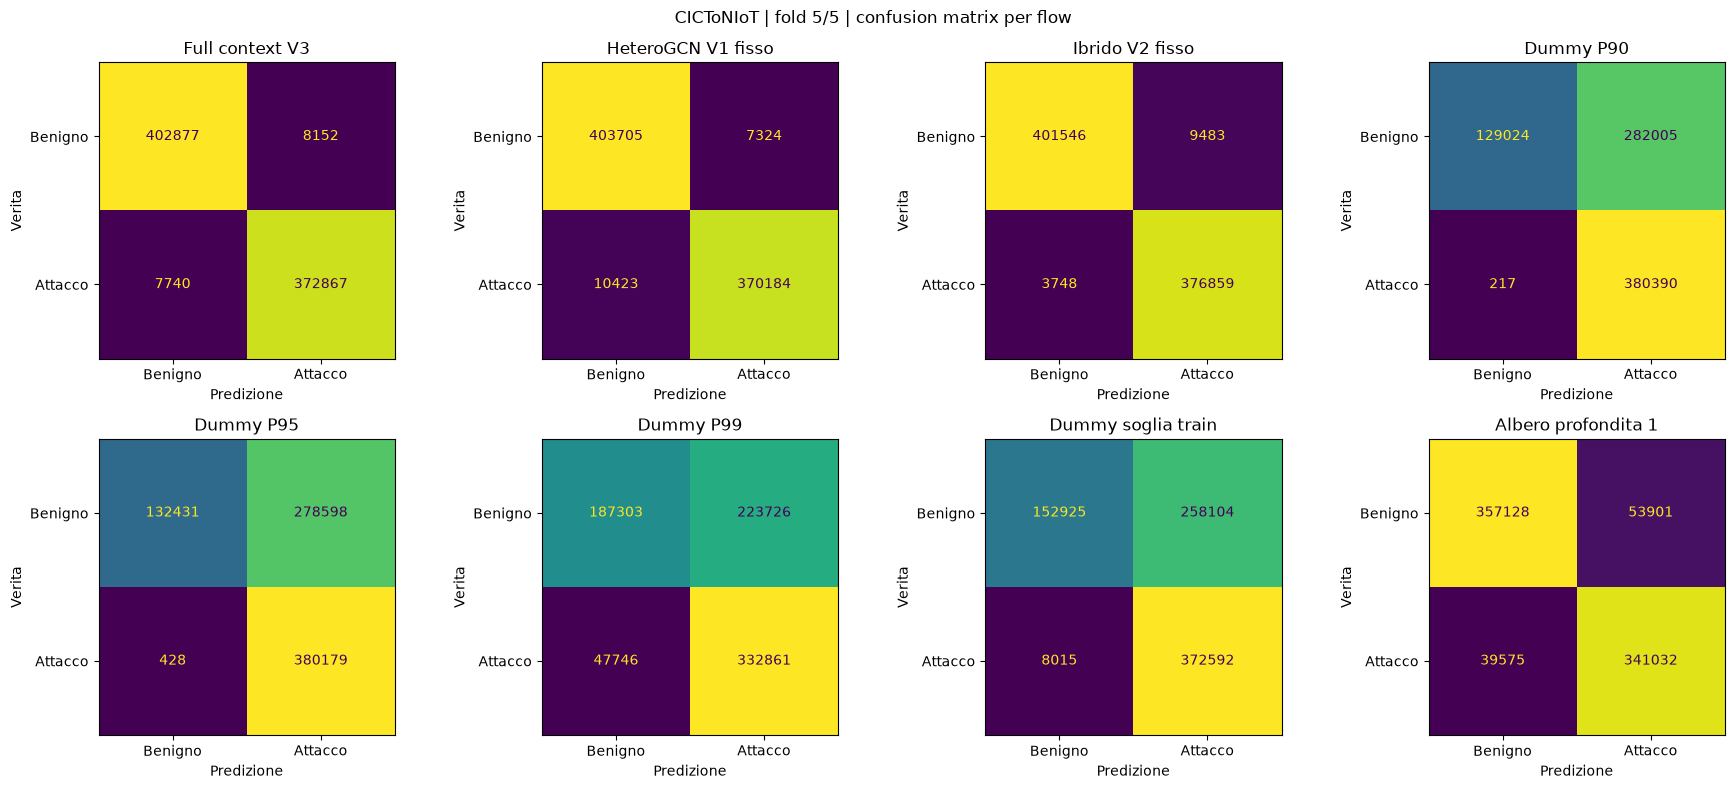

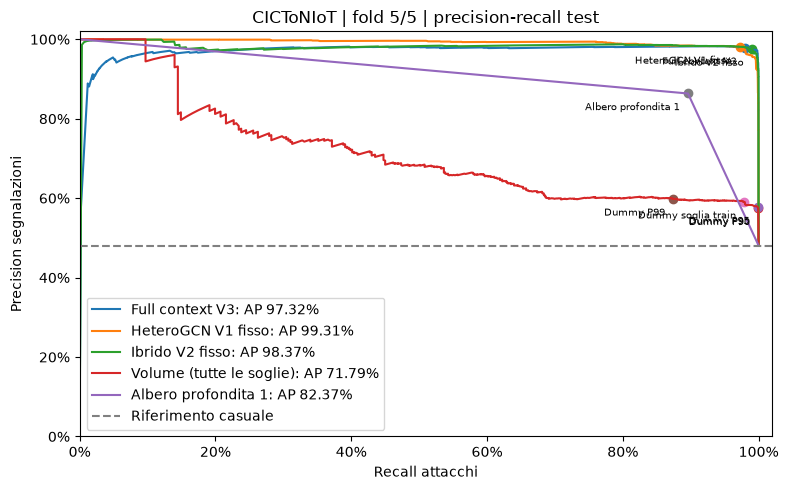

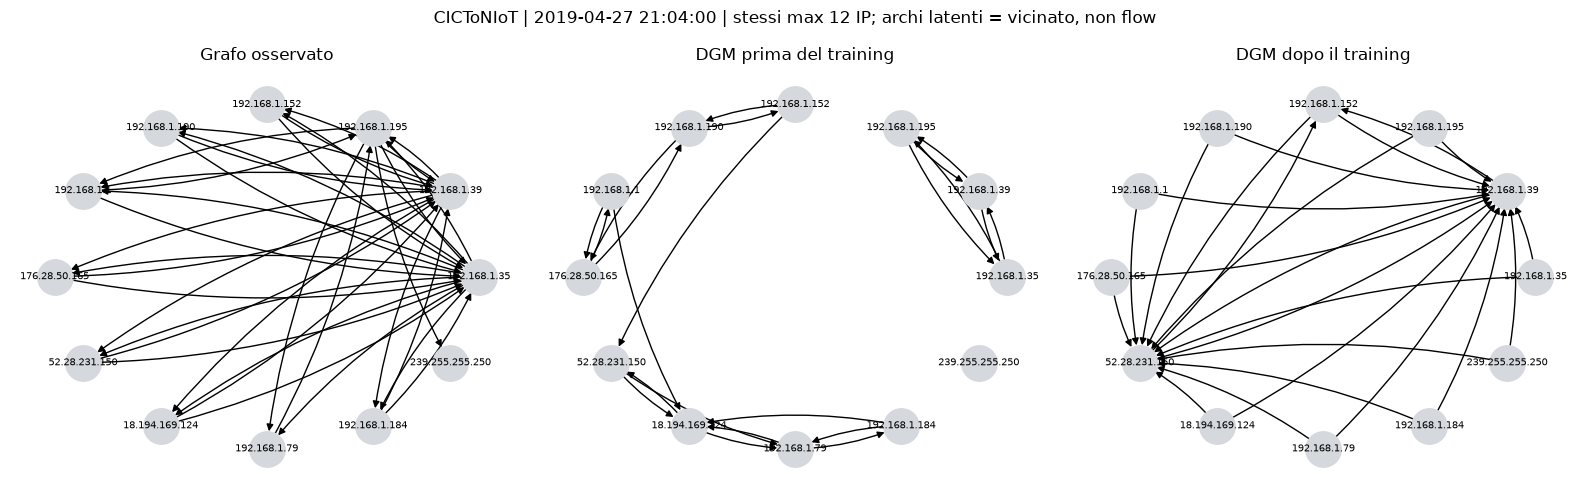

V3 completata. Risultati e checkpoint: data\marco_output_v3\20261026_094912_086837
summary_test.csv | media e deviazione standard fra i fold; std non stimabile con un solo fold


fold eseguiti  F1 (%) mean  F1 (%) std  \
dataset    modello                                                       
CICIDS2017 Albero profondita 1              5        95.21        1.88   
           Dummy P90                        5        41.63        7.47   
           Dummy P95                        5        44.55        7.56   
           Dummy P99                        5        52.58        7.56   
           Dummy soglia train               5        95.26        1.87   
           Full context V3                  5        96.87        1.05   
           HeteroGCN V1 fisso               5        94.40        4.16   
           Ibrido V2 fisso                  5        97.85        0.64   
CICToNIoT  Albero profondita 1              5        88.72        2.87   
           Dummy P90                        5        74.18        2.10   
           Dummy P95                        5        74.31        2.12   
           Dummy P99                        5        73.32        2.14   
           Dummy soglia train               5        74.81        2.12   
           Full context V3                  5        97.92        1.31   
           HeteroGCN V1 fisso               5        97.46        1.48   
           Ibrido V2 fisso                  5        96.38        3.01   

                                recall (%) mean  falsi allarmi mean  
dataset    modello                                                   
CICIDS2017 Albero profondita 1            91.00                96.2  
           Dummy P90                      99.79            301183.0  
           Dummy P95                      99.61            266107.8  
           Dummy P99                      99.04            189961.8  
           Dummy soglia train             91.00                 0.0  
           Full context V3                97.47              4061.6  
           HeteroGCN V1 fisso             93.37              4701.8  
           Ibrido V2 fisso                98.05              2780.0  
CICToNIoT  Albero profondita 1            94.85            110607.0  
           Dummy P90                      99.96            392324.0  
           Dummy P95                      99.93            389513.6  
           Dummy P99                      91.81            332238.4  
           Dummy soglia train             98.45            365902.6  
           Full context V3                99.17             20088.8  
           HeteroGCN V1 fisso             98.47             21707.8  
           Ibrido V2 fisso                99.14             39769.8

summary_pairs.csv | media e deviazione standard fra i fold; std non stimabile con un solo fold


fold eseguiti  F1 (%) mean  F1 (%) std  \
dataset    modello                                                       
CICIDS2017 Albero profondita 1              5         7.06        2.48   
           Dummy P90                        5         1.71        0.11   
           Dummy P95                        5         2.39        0.18   
           Dummy P99                        5         7.00        0.82   
           Dummy soglia train               5         7.85        2.93   
           Full context V3                  5        16.53        0.81   
           HeteroGCN V1 fisso               5        16.46        3.39   
           Ibrido V2 fisso                  5        20.41        2.97   
CICToNIoT  Albero profondita 1              5        67.66        6.00   
           Dummy P90                        5        42.90        1.10   
           Dummy P95                        5        50.54        4.62   
           Dummy P99                        5        42.47        5.08   
           Dummy soglia train               5        51.12        2.95   
           Full context V3                  5        76.67        6.10   
           HeteroGCN V1 fisso               5        64.81       10.88   
           Ibrido V2 fisso                  5        74.84        4.34   

                                recall (%) mean  falsi allarmi mean  
dataset    modello                                                   
CICIDS2017 Albero profondita 1             4.11                25.0  
           Dummy P90                      39.24              9924.6  
           Dummy P95                      27.21              4801.2  
           Dummy P99                      19.53               978.2  
           Dummy soglia train              4.11                 0.0  
           Full context V3                15.28               157.4  
           HeteroGCN V1 fisso             12.11                67.8  
           Ibrido V2 fisso                19.58               174.6  
CICToNIoT  Albero profondita 1            57.45               251.0  
           Dummy P90                      88.66              4492.2  
           Dummy P95                      84.51              3087.2  
           Dummy P99                      33.66               484.0  
           Dummy soglia train             46.68               717.8  
           Full context V3                87.89               865.6  
           HeteroGCN V1 fisso             69.28               924.8  
           Ibrido V2 fisso                90.02              1020.6

,dataset,fold configurati,fold eseguiti,flow test unici,flow dataset,copertura (%)
0,CICIDS2017,5,5,2830743,2830743,100.0
1,CICToNIoT,5,5,5351760,5351760,100.0


In [3]:
# TEST, GRAFO LATENTE E CONFRONTO CON TUTTE LE BASELINE
def evaluation_metrics(target, score, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(target, predicted, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(target, predicted, labels=[0, 1]).ravel()
    both = len(np.unique(target)) == 2
    return {"F1 (%)": 100*f1, "precision (%)": 100*precision, "recall (%)": 100*recall,
        "accuracy (%)": 100*accuracy_score(target, predicted),
        "AP (%)": 100*average_precision_score(target, score) if both else None,
        "ROC-AUC (%)": 100*roc_auc_score(target, score) if both else None,
        "balanced accuracy (%)": 100*balanced_accuracy_score(target, predicted),
        "MCC": float(matthews_corrcoef(target, predicted)),
        "veri negativi": int(tn), "falsi allarmi": int(fp), "attacchi mancati": int(fn), "veri positivi": int(tp),
        "FPR (%)": 100*fp/(fp+tn) if fp+tn else None}

@torch.no_grad()
def plot_latent_comparison(trained, untrained, graph, window_df, folder, dataset_name):
    trained.eval(); untrained.eval()
    _, initial = untrained.latent_graph(graph)
    _, learned = trained.latent_graph(graph)
    mapping = list(dict.fromkeys(value for pair in zip(window_df["Source IP"],window_df["Destination IP"]) for value in pair))
    original = graph[RELATIONS[0]].edge_index.cpu()
    focus = graph["ip"].num_nodes
    selected = torch.bincount(original.flatten(),minlength=focus).topk(min(MAX_LATENT_NODES,focus)).indices.tolist()
    positions = nx.circular_layout(selected)
    fig, axes = plt.subplots(1,3,figsize=(16,5))
    for ax,title,edge_index in zip(axes,["Grafo osservato","DGM prima del training","DGM dopo il training"],
                                 [original,initial.cpu(),learned.cpu()]):
        shown = nx.DiGraph(); shown.add_nodes_from(selected)
        shown.add_edges_from((int(u),int(v)) for u,v in edge_index.t().tolist() if int(u) in selected and int(v) in selected)
        nx.draw_networkx(shown,positions,ax=ax,labels={i:mapping[i] for i in selected},font_size=7,
                         node_size=650,node_color="#d5d8dc",arrowsize=10,connectionstyle="arc3,rad=0.1")
        ax.set_title(title);ax.axis("off")
    fig.suptitle(f"{dataset_name} | {window_df.window.iloc[0]} | stessi max {MAX_LATENT_NODES} IP; archi latenti = vicinato, non flow")
    fig.tight_layout();fig.savefig(folder/"latent_graph.png",dpi=PLOT_DPI);plt.show()


def summarize_folds(comparisons, pair_rows, experiments, datasets, run_dir):
    metrics = ["F1 (%)","precision (%)","recall (%)","accuracy (%)","AP (%)","ROC-AUC (%)",
               "balanced accuracy (%)","MCC","FPR (%)","falsi allarmi","attacchi mancati"]
    for rows, filename in [(comparisons,"summary_test.csv"),(pair_rows,"summary_pairs.csv")]:
        frame = pd.DataFrame(rows)
        grouped = frame.groupby(["dataset","modello"])
        stats = grouped[metrics].agg(["mean","std"])
        stats.columns = [f"{metric} {stat}" for metric,stat in stats.columns]
        stats.insert(0,"fold eseguiti",grouped["fold"].nunique())
        stats.to_csv(run_dir/filename)
        print(filename,"| media e deviazione standard fra i fold; std non stimabile con un solo fold")
        display(stats[["fold eseguiti","F1 (%) mean","F1 (%) std","recall (%) mean","falsi allarmi mean"]].round(2))
    coverage = []
    for name,df in datasets.items():
        runs = [e for e in experiments.values() if e["dataset"]==name]
        tested = [int(i) for e in runs for i in e["test_ids"]]
        assert len(tested)==len(set(tested)), "Flow valutati in piu test esterni"
        configured = runs[0]["n_folds"]
        if configured>1 and len(runs)==configured:
            assert set(tested)==set(df.flow_id), "La k-fold completa deve valutare tutti i flow"
        coverage.append({"dataset":name,"fold configurati":configured,"fold eseguiti":len(runs),
                         "flow test unici":len(tested),"flow dataset":len(df),"copertura (%)":100*len(tested)/len(df)})
    coverage = pd.DataFrame(coverage)
    coverage.to_csv(run_dir/"test_coverage.csv",index=False)
    display(coverage.round(2))

all_comparisons, all_pairs = [], []
for experiment in experiments.values():
    dataset_name = experiment["dataset"]
    fold, n_folds = experiment["fold"], experiment["n_folds"]
    print(f"{dataset_name} | test fold {fold}/{n_folds}")
    folder, df = experiment["folder"], datasets[dataset_name]
    best = torch.load(folder/"best_model.pt",map_location="cpu",weights_only=True)
    baseline = torch.load(folder/"baseline_v1.pt",map_location="cpu",weights_only=True)
    baseline_v2 = torch.load(folder/"baseline_v2.pt",map_location="cpu",weights_only=True)
    network_predictions = {}
    models = {}
    fig, axes = plt.subplots(1,3,figsize=(18,4))
    for ax,(name,checkpoint) in zip(axes,[("Full context V3",best),("HeteroGCN V1 fisso",baseline),("Ibrido V2 fisso",baseline_v2)]):
        model = new_model(checkpoint["params"]).to(DEVICE)
        model.load_state_dict(checkpoint["state_dict"])
        prediction = predict(model,experiment["test_graphs"],DEVICE,checkpoint["params"]["batch_size"])
        assert prediction.flow_id.is_unique and set(prediction.flow_id)==set(experiment["test_ids"])
        prediction["prediction"] = (prediction.score.astype("float64")>=checkpoint["threshold"]).astype(int)
        network_predictions[name] = prediction.set_index("flow_id")
        models[name] = model
        history = pd.DataFrame(checkpoint["history"]).set_index("epoca")
        ax.plot(history.index,history.train,label="Train")
        ax.plot(history.index,history.validation,label="Validation")
        ax.axvline(checkpoint["best_epoch"],color="gray",linestyle="--",label="Checkpoint scelto")
        ax.set(title=name,xlabel="Epoca",ylabel="Focal loss media per flow");ax.legend()
    fig.suptitle(dataset_name);fig.tight_layout();fig.savefig(folder/"loss.png",dpi=PLOT_DPI);plt.show()
    predictions = network_predictions["Full context V3"].reset_index().merge(
        df[["flow_id","window","Source IP","Destination IP","attack_type"]],on="flow_id",validate="one_to_one")
    reference = network_predictions["HeteroGCN V1 fisso"].loc[predictions.flow_id]
    assert np.array_equal(reference.target,predictions.target)
    predictions["v1_score"] = reference.score.to_numpy()
    predictions["v1_prediction"] = reference.prediction.to_numpy()
    reference_v2 = network_predictions["Ibrido V2 fisso"].loc[predictions.flow_id]
    assert np.array_equal(reference_v2.target,predictions.target)
    predictions["v2_score"] = reference_v2.score.to_numpy()
    predictions["v2_prediction"] = reference_v2.prediction.to_numpy()
    train_flows = df[df.flow_id.isin(experiment["train_ids"]) ]
    test_flows = df[df.flow_id.isin(experiment["test_ids"])]
    train_counts = count_features(train_flows)
    count_predictions = count_features(test_flows).set_index("flow_id").loc[predictions.flow_id].reset_index()
    thresholds = fit_count_thresholds(train_flows)
    count_train_threshold = choose_threshold(train_counts[["target","flow_count"]].rename(columns={"flow_count":"score"}))
    stump = DecisionTreeClassifier(max_depth=TREE_MAX_DEPTH,random_state=SEED).fit(train_counts[STUMP_FEATURES],train_counts.target)
    stump_rule = export_text(stump,feature_names=STUMP_FEATURES,decimals=2)
    print(dataset_name,"| percentili train:",thresholds,"| soglia F1 train:",count_train_threshold)
    print("Albero appreso sul train:\n"+stump_rule)
    print(f"Accuracy sempre benigno: {100*(predictions.target==0).mean():.2f}%")
    specs = [("Full context V3",predictions.score.to_numpy(),predictions.prediction.to_numpy(),f"score >= {best['threshold']:.8g}"),
             ("HeteroGCN V1 fisso",predictions.v1_score.to_numpy(),predictions.v1_prediction.to_numpy(),f"score >= {baseline['threshold']:.8g}"),
             ("Ibrido V2 fisso",predictions.v2_score.to_numpy(),predictions.v2_prediction.to_numpy(),f"score >= {baseline_v2['threshold']:.8g}")]
    for name,threshold in thresholds.items():
        count_predictions[name] = (count_predictions.flow_count>threshold).astype(int)
        specs.append((f"Dummy {name}",count_predictions.flow_count.to_numpy(),count_predictions[name].to_numpy(),f"flow > {threshold:g}"))
    count_predictions["Soglia_train"] = (count_predictions.flow_count>=count_train_threshold).astype(int)
    count_predictions["Albero"] = stump.predict(count_predictions[STUMP_FEATURES])
    specs.extend([("Dummy soglia train",count_predictions.flow_count.to_numpy(),count_predictions.Soglia_train.to_numpy(),f"flow >= {count_train_threshold:g}"),
                  (f"Albero profondita {TREE_MAX_DEPTH}",stump.predict_proba(count_predictions[STUMP_FEATURES])[:,1],count_predictions.Albero.to_numpy(),stump_rule)])
    y = predictions.target.to_numpy()
    comparison_rows,unit_rows,reports,family_rows = [],[],{},[]
    for name,scores,guessed,rule in specs:
        comparison_rows.append({"dataset":dataset_name,"fold":fold,"modello":name,"regola":rule,**evaluation_metrics(y,scores,guessed)})
        pairs = predictions[["window","Source IP","Destination IP","target"]].assign(score=scores,prediction=guessed)
        pairs = pairs.groupby(["window","Source IP","Destination IP"]).agg(
            target=("target","max"),score=("score","max"),prediction=("prediction","max"))
        unit_rows.append({"dataset":dataset_name,"fold":fold,"modello":name,"unita":"coppia IP/finestra","totali":len(pairs),"attacchi reali":int(pairs.target.sum()),
                          **evaluation_metrics(pairs.target,pairs.score,pairs.prediction)})
        reports[name] = classification_report(y,guessed,labels=[0,1],target_names=["BENIGN","ATTACK"],output_dict=True,zero_division=0)
        if name in network_predictions:
            family = predictions.assign(guess=guessed).groupby("attack_type").apply(
                lambda part:pd.Series({"flow":len(part),"corretti (%)":100*(part.target==part.guess).mean()})).reset_index()
            family["modello"] = name; family_rows.extend(family.to_dict("records"))
    comparison = pd.DataFrame(comparison_rows).set_index("modello")
    print(dataset_name,"| test: una decisione per flow")
    display(comparison[["F1 (%)","precision (%)","recall (%)","accuracy (%)","AP (%)","ROC-AUC (%)",
                        "balanced accuracy (%)","MCC","falsi allarmi","attacchi mancati"]].round(2))
    print("Controllo per coppia IP/finestra: target = almeno un flow di attacco")
    display(pd.DataFrame(unit_rows).set_index("modello")[["totali","attacchi reali","F1 (%)","recall (%)","falsi allarmi","attacchi mancati"]].round(2))
    print("Famiglie reali: recall attacchi / specificita BENIGN")
    display(pd.DataFrame(family_rows).pivot(index="attack_type",columns="modello",values="corretti (%)").round(2))
    cols = min(4,len(specs)); rows = int(np.ceil(len(specs)/cols))
    fig,axes = plt.subplots(rows,cols,figsize=(4.5*cols,4*rows),squeeze=False)
    for ax,(name,scores,guessed,rule) in zip(axes.flat,specs):
        ConfusionMatrixDisplay(confusion_matrix(y,guessed,labels=[0,1]),display_labels=["Benigno","Attacco"]).plot(
            ax=ax,colorbar=False,values_format="d")
        ax.set(title=name,xlabel="Predizione",ylabel="Verita")
    for ax in list(axes.flat)[len(specs):]:
        ax.axis("off")
    fig.suptitle(f"{dataset_name} | fold {fold}/{n_folds} | confusion matrix per flow");fig.tight_layout()
    fig.savefig(folder/"confusion_matrices.png",dpi=PLOT_DPI);plt.show()
    fig,ax = plt.subplots(figsize=(8,5))
    for index in [0,1,2,3,len(specs)-1]:
        name,scores,guessed,_ = specs[index]
        precision,recall,_ = precision_recall_curve(y,scores)
        label = "Volume (tutte le soglie)" if index==3 else name
        ax.plot(recall,precision,label=f"{label}: AP {100*average_precision_score(y,scores):.2f}%")
    for name,scores,guessed,_ in specs:
        precision,recall,_,_ = precision_recall_fscore_support(y,guessed,average="binary",zero_division=0)
        ax.scatter([recall],[precision]);ax.annotate(name,(recall,precision),xytext=(-6,-12),textcoords="offset points",ha="right",fontsize=7)
    ax.axhline(y.mean(),color="gray",linestyle="--",label="Riferimento casuale")
    ax.set(title=f"{dataset_name} | fold {fold}/{n_folds} | precision-recall test",xlabel="Recall attacchi",ylabel="Precision segnalazioni",xlim=(0,1.02),ylim=(0,1.02))
    ax.xaxis.set_major_formatter(PercentFormatter(1));ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend();fig.tight_layout();fig.savefig(folder/"precision_recall.png",dpi=PLOT_DPI);plt.show()
    # Grafo completo in inferenza; si disegnano solo gli IP piu presenti.
    sample = max(experiment["test_graphs"],key=lambda g:int(g[RELATIONS[0]].edge_label.sum()))
    sample_flows = df[df.window==pd.Timestamp(sample.window)]
    seed_everything(SEED)
    untrained = new_model(best["params"]).to(DEVICE).eval()
    plot_latent_comparison(models["Full context V3"],untrained,sample.clone().to(DEVICE),sample_flows,folder,dataset_name)
    predictions.to_csv(folder/"predictions.csv",index=False)
    count_predictions.to_csv(folder/"count_baseline_predictions.csv",index=False)
    comparison.to_csv(folder/"comparison_test.csv")
    pd.DataFrame(unit_rows).to_csv(folder/"unit_comparison.csv",index=False)
    pd.DataFrame(family_rows).to_csv(folder/"attack_families.csv",index=False)
    run = {"dataset":dataset_name,"files":[str(p) for p in DATASETS[dataset_name]],"rows":len(df),"windows":int(df.window.nunique()),
        "device":DEVICE_NAME,"cpu_threads":CPU_THREADS,"seed":SEED,"params":best["params"],"baseline_params":baseline["params"],"baseline_v2_params":baseline_v2["params"],
        "max_epochs":MAX_EPOCHS,"patience":PATIENCE,"min_delta":MIN_DELTA,
        "best_epoch":best["best_epoch"],"epochs_run":best["epochs_run"],"threshold":best["threshold"],
        "baseline_best_epoch":baseline["best_epoch"],"baseline_threshold":baseline["threshold"],
        "selection":"checkpoint min validation loss; V3 trial max validation F1, AP, then min loss; V1/V2 fixed; model thresholds inside optimal validation score interval",
        "split":"random minute graphs 70/15/15; stratified by attack presence when possible; same for all models",
        "normalization":"train-only StandardScaler; V3 log1p(abs) of community_size, indegree, outdegree, betweenness; V1/V2 original 3 node features with log1p degrees; shared signed log1p edge attrs",
        "centrality_samples":CENTRALITY_SAMPLES,"node_features_v3":["community_size","in_degree","out_degree","betweenness"],
        "node_features_v12":["community_id","in_degree","out_degree"],
        "latent_gcn_numerics":"standard GCN forward; zero degree masked before inverse square root for finite backward",
        "normalization_stats":{k:{field:value.tolist() for field,value in stats.items()} for k,stats in best["normalization"].items()},
        "dgm":"V3: within-minute top-k of full-neighbor softmax of negative squared latent distances; learned temperature and embedding through selected edge weights in both GCNs; physical GAT relations retained in both layers; chunked and recomputed backward",
        "test_flows":len(y),"test_attacks":int(y.sum()),"edge_features_used_by_hybrid":True,"edge_features_used_by_v1":False,
        "count_baseline_thresholds":thresholds,"count_train_threshold":count_train_threshold,"stump_rule":stump_rule,
        "loss_history":best["history"],"baseline_loss_history":baseline["history"],
        "baseline_v2_loss_history":baseline_v2["history"],"baseline_v2_threshold":baseline_v2["threshold"],
        "baseline_v2_best_epoch":baseline_v2["best_epoch"],"architecture_source":"gae_for_3edge_contaminato1_v2.ipynb",
        "comparison":comparison.reset_index().to_dict("records"),"classification_reports":reports,
        "accuracy_always_benign":float((y==0).mean()),"torch":str(torch.__version__),"pyg":str(torch_geometric.__version__)}
    run.update({"fold":fold,"n_folds":n_folds,
        "evaluation":"holdout" if n_folds==1 else "outer graph k-fold with inner validation",
        "grid_search":GRID_SEARCH,
        "cv_scope":"holdout" if n_folds==1 else ("grid selected on inner validation" if GRID_SEARCH else "fixed configuration; not a new cross-validated hyperparameter search"),
        "split":"disjoint minute graphs; shared by all compared models; external fold never used for checkpoint/threshold selection"})
    run.update({"grid_search":GRID_SEARCH,"early_stopping":EARLY_STOPPING,"split_seed":SPLIT_SEED,
        "holdout_test_fraction":HOLDOUT_TEST_FRACTION,"holdout_validation_fraction":HOLDOUT_VAL_FRACTION,
        "kfold_validation_fraction":KFOLD_VAL_FRACTION,"window_minutes":WINDOW_MINUTES,
        "focal_alpha":FOCAL_ALPHA,"focal_gamma":FOCAL_GAMMA,"count_percentiles":COUNT_PERCENTILES,
        "tree_max_depth":TREE_MAX_DEPTH,"loader_workers":LOADER_WORKERS,"gpu_requested":USE_GPU})
    (folder/"run.json").write_text(json.dumps(run,indent=2),encoding="utf-8")
    all_comparisons.extend(comparison_rows)
    all_pairs.extend(unit_rows)
    del models,model,untrained,train_counts,count_predictions
    gc.collect()
pd.DataFrame(all_comparisons).to_csv(RUN_DIR/"comparison_all_datasets.csv",index=False)
print("V3 completata. Risultati e checkpoint:",RUN_DIR)

summarize_folds(all_comparisons,all_pairs,experiments,datasets,RUN_DIR)
